# 1 Introduction

Public transport accessibility plays a fundamental role in connecting people with employment opportunities (Bastiaanssen et al., 2022). This is particularly important for night-time workers and others travelling during overnight hours, when public transport services may be less frequent and journeys by public transport more difficult (Kapitza, 2024). Limited night-time public transport can constrain access to employment, with potentially greater effects on lower-income and public transport-dependent populations, thereby contributing to existing transport inequalities (Lucas, 2012; Palm et al., 2023; Bastiaanssen et al., 2022). Improving employment accessibility is important consideration in transport planning, particularly in urban areas where the distribution of population and employment opportunities is uneven (Bastiaanssen et al., 2022; Geurs and van Wee, 2004).

Greater Manchester has a diverse but spatially uneven economy, with access to employment and economic opportunities varying across the city-region (HM Government, 2019; Mealy and Coyle, 2022). It also has a substantial night-time economy, with around one-third of the Greater Manchester workforce employed in jobs or businesses that are active at night (Greater Manchester Combined Authority, 2022). Culture, leisure and related activities tend to be concentrated in city and town centres, while Manchester city centre has a particularly strong night-time and visitor economy(Greater Manchester Combined Authority, 2019; Manchester City Council, 2024). Access to these employment opportunities can be more difficult at night, as limited night-time transport provision can constrain workers’ access to employment (Emilia Smeds et al., 2017; McArthur et al., 2019). In Greater Manchester, poor night-time transport links have similarly been identified as a barrier to employment and other opportunities(Bee Network Committee, 2024). Transport for Greater Manchester (TfGM) introduced the Bee Network overnight bus pilot, extending the operating hours of four existing routes to improve late-night connectivity and support access to employment (Transport for Greater Manchester, n.d.; Greater Manchester Combined Authority, 2024).

The problem is that extending operating hours does not affect accessibility equally across Greater Manchester. Accessibility depends on transport network conditions and the spatial distribution of employment opportunities, so the effect of the pilot may vary between neighbourhoods (Geurs and van Wee, 2004; Greater Manchester Combined Authority, 2024). It is important to establish whether the additional services change access to employment, where these changes occur and whether more disadvantaged areas benefit.

The aim of this study is to evaluate the effect of the Bee Network overnight bus pilot on accessibility to hospitality employment and assess the equity of the resulting changes across neighbourhoods with different levels of income deprivation in Greater Manchester.

The study answers three research questions:
1.	How is night-time public transport accessibility to hospitality employment distributed across Greater Manchester with and without the overnight bus pilot? 
2.	To what extent does the pilot improve accessibility to hospitality employment, and where are these improvements concentrated? 
3.	Are the accessibility changes associated with the pilot distributed equitably across neighbourhoods with different levels of income deprivation, after accounting for relevant neighbourhood characteristics?

The study adopts a quantitative neighbourhood-level design using Lower-layer Super Output Areas (LSOAs) as the spatial unit. Public transport accessibility is measured using timetable-based routing and a cumulative opportunity measure of hospitality jobs reachable within a specified travel-time threshold. Two network scenarios are compared: one with the overnight pilot services and the other one without the pilot services. All other modelling conditions are held constant to estimate the accessibility change associated with the pilot. Spatial analysis is used to examine the distribution of accessibility and accessibility change across Greater Manchester. These results are then combined with the Income Deprivation domain of the English Indices of Deprivation 2025 (IMD 2025) to assess how accessibility changes are distributed across neighbourhoods. Regression analysis is used to examine whether deprivation is associated with accessibility change after controlling for relevant neighbourhood characteristics, while spatial autocorrelation is tested to assess whether residual spatial dependence remains.

The findings show that the pilot improves accessibility to hospitality employment in some areas, but the changes are spatially concentrated around the four pilot routes. More than half of LSOAs experience no measurable increase, while differences in accessibility change between income deprivation groups are not statistically significant. The distribution of accessibility change is therefore more closely related to the geographical coverage of the pilot routes than to neighbourhood income deprivation.

The remainder of the dissertation is organised as follows. Chapter 2 reviews the literature on transport accessibility, transport equity, accessibility inequality, deprivation and network-based accessibility measurement. Chapter 3 describes the research design, study area, accessibility modelling, data, spatial analysis and statistical methods. Chapter 4 presents the accessibility, pilot comparison, equity, regression and spatial analysis results. Chapter 5 discusses the findings in relation to transport equity, policy implications and the limitations of the study. Chapter 6 concludes by summarising the contribution of the research and identifying directions for further work.

# 2 Literature Review

## 2.1 Transport Equity

# 3 Methodology

## 3.1 Research design

This study adopts a quantitative case-study design to evaluate the accessibility and equity impacts of the Bee Network overnight bus pilot in Greater Manchester. The analysis is conducted at the Lower Layer Super Output Area (LSOA) level and compares two modelled public transport scenarios under the same night-time conditions. First one retaining the four pilot services and the other one excluding them. This design isolates the accessibility change associated with the additional overnight services while keeping the remaining network and modelling conditions unchanged.

The analysis follows three stages corresponding to the research questions. First, night-time accessibility to hospitality employment is estimated under both scenarios to examine its spatial distribution across Greater Manchester. Second, the two scenarios are compared to identify the magnitude and spatial distribution of accessibility changes associated with the pilot. Third, the equity of these changes is assessed across neighbourhoods with different levels of income deprivation. This includes comparisons between deprivation groups and regression analysis of whether accessibility improves and by how much, while controlling for relevant neighbourhood characteristics. Spatial diagnostics are used to examine whether unexplained geographical patterns remain in the regression results. 

## 3.2 Study Area

In [1]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
from IPython.display import display

# file paths
imd_path = (
    r"D:\final dissertation"
    r"\LSOA_IMD2025_OSGB1936_-7140860978498206463.zip"
)

output_dir = r"D:\final dissertation\outputs"
os.makedirs(output_dir, exist_ok=True)

# read the IMD 2025 LSOA dataset
imd = gpd.read_file(imd_path)

# reproject to British National Grid
imd = imd.to_crs("EPSG:27700")

# retrieve the Greater Manchester boundary from OSM 
gm_osm_boundary = ox.geocode_to_gdf(
    "Greater Manchester, England, United Kingdom"
)

gm_osm_boundary = gm_osm_boundary.to_crs(imd.crs)

In [2]:
# create representative points for all LSOAs
imd_points = imd[
    [
        "LSOA21CD",
        "LSOA21NM",
        "IMDRank",
        "IMDDecil",
        "geometry"
    ]
].copy()

imd_points["geometry"] = imd_points.representative_point()

# identify Greater Manchester LSOAs
gm_lsoa_points = gpd.sjoin(
    imd_points,
    gm_osm_boundary[["geometry"]],
    predicate="within",
    how="inner"
)

gm_lsoa_codes = gm_lsoa_points[
    "LSOA21CD"
].unique()

imd_gm = imd[
    imd["LSOA21CD"].isin(gm_lsoa_codes)
].copy()

In [3]:
import pandas as pd

# create the Greater Manchester study-area boundary
gm_boundary = (
    imd_gm[["geometry"]]
    .dissolve()
    .reset_index(drop=True)
)

# ensure the study-area boundary uses British National Grid
if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs("EPSG:27700")

# create LSOA representative origins
origins = imd_gm[
    [
        "LSOA21CD",
        "LSOA21NM",
        "IMDRank",
        "IMDDecil",
        "geometry"
    ]
].copy()

# ensure the origin polygons use British National Grid
if origins.crs.to_epsg() != 27700:
    origins = origins.to_crs("EPSG:27700")

# create one representative point within each LSOA polygon
origins["geometry"] = origins.representative_point()

# rename the LSOA code as the origin ID
origins = origins.rename(
    columns={
        "LSOA21CD": "id"
    }
)

# extract British National Grid coordinates for display
origins_display = origins.copy()

origins_display["Easting"] = (
    origins_display.geometry.x.round(2)
)

origins_display["Northing"] = (
    origins_display.geometry.y.round(2)
)

The Greater Manchester boundary was retrieved from OpenStreetMap (OSM) using the OSMnx package (Boeing, 2017) and used as a spatial mask to identify LSOAs within the study area. LSOA boundary polygons were obtained from the IMD 2025 spatial dataset and projected to the British National Grid.

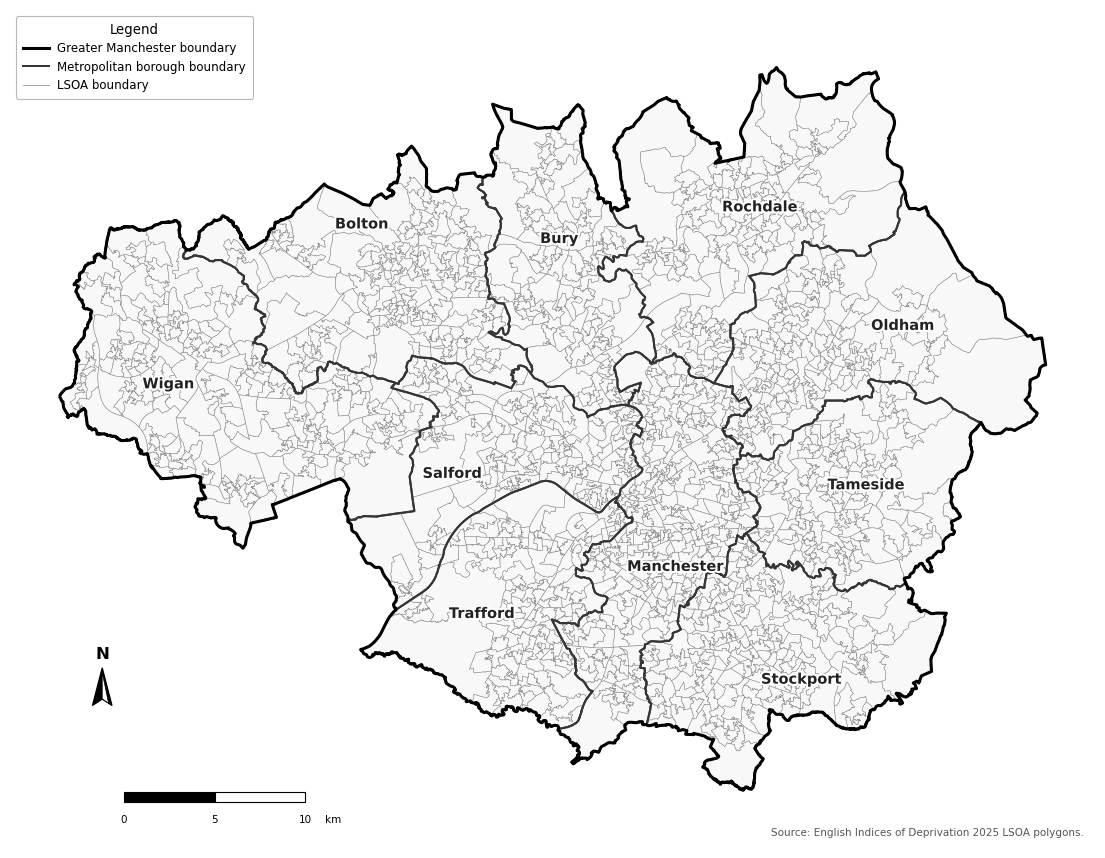

In [72]:
from matplotlib.lines import Line2D
import matplotlib.patheffects as path_effects
from matplotlib.patches import Polygon, Rectangle
import numpy as np

imd_map = imd_gm.copy()
gm_map = gm_boundary.copy()

# ensure British National Grid projection
if imd_map.crs is None:
    raise ValueError("imd_gm has no CRS assigned.")

if gm_map.crs is None:
    raise ValueError("gm_boundary has no CRS assigned.")

if imd_map.crs.to_epsg() != 27700:
    imd_map = imd_map.to_crs("EPSG:27700")

if gm_map.crs.to_epsg() != 27700:
    gm_map = gm_map.to_crs("EPSG:27700")

# extract borough names from LSOA names
imd_map["Borough"] = (
    imd_map["LSOA21NM"]
    .astype(str)
    .str.replace(r"\s+\d{3}[A-Z]$", "", regex=True)
    .str.strip()
)

expected_boroughs = {
    "Bolton",
    "Bury",
    "Manchester",
    "Oldham",
    "Rochdale",
    "Salford",
    "Stockport",
    "Tameside",
    "Trafford",
    "Wigan"
}

found_boroughs = set(imd_map["Borough"].dropna().unique())

missing_boroughs = expected_boroughs - found_boroughs
unexpected_boroughs = found_boroughs - expected_boroughs

if missing_boroughs:
    print("Warning - missing boroughs:", sorted(missing_boroughs))

if unexpected_boroughs:
    print("Warning - unexpected borough names:", sorted(unexpected_boroughs))

# dissolve LSOAs into metropolitan boroughs
boroughs_gm = (
    imd_map[["Borough", "geometry"]]
    .dropna(subset=["Borough"])
    .dissolve(by="Borough")
    .reset_index()
)

# create borough label points
borough_labels = boroughs_gm.copy()
borough_labels["geometry"] = borough_labels.representative_point()
label_offsets = {
    "Bolton": (0, 2500),
    "Bury": (800, 1200),
    "Manchester": (1000, -500),
    "Oldham": (1600, 0),
    "Rochdale": (0, 1000),
    "Salford": (-1200, 500),
    "Stockport": (800, -1000),
    "Tameside": (1200, 0),
    "Trafford": (-1200, -500),
    "Wigan": (-800, 0)
}

# create figure
fig, ax = plt.subplots(
    figsize=(14, 11),
    facecolor="white"
)

ax.set_facecolor("white")

# LSOA polygons
imd_map.plot(
    ax=ax,
    facecolor="#F8F8F8",
    edgecolor="#8A8A8A",
    linewidth=0.38,
    zorder=1
)

# metropolitan borough boundaries
boroughs_gm.boundary.plot(
    ax=ax,
    color="#353535",
    linewidth=1.45,
    zorder=2
)

# Greater Manchester outer boundary
gm_map.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2.2,
    zorder=3
)

# add borough labels
for _, row in borough_labels.iterrows():

    borough_name = row["Borough"]

    offset_x, offset_y = label_offsets.get(
        borough_name,
        (0, 0)
    )

    label = ax.text(
        row.geometry.x + offset_x,
        row.geometry.y + offset_y,
        borough_name,
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="bold",
        color="#222222",
        zorder=10
    )

    label.set_path_effects([
        path_effects.withStroke(
            linewidth=3.0,
            foreground="white"
        )
    ])

# set map extent
xmin, ymin, xmax, ymax = gm_map.total_bounds

map_data_width = xmax - xmin
map_data_height = ymax - ymin

x_margin = map_data_width * 0.05
y_margin = map_data_height * 0.08

ax.set_xlim(
    xmin - x_margin,
    xmax + x_margin
)

ax.set_ylim(
    ymin - y_margin,
    ymax + y_margin
)

ax.set_aspect("equal")

# legend
legend_handles = [
    Line2D(
        [0], [0],
        color="black",
        linewidth=2.2,
        label="Greater Manchester boundary"
    ),

    Line2D(
        [0], [0],
        color="#353535",
        linewidth=1.45,
        label="Metropolitan borough boundary"
    ),

    Line2D(
        [0], [0],
        color="#8A8A8A",
        linewidth=0.55,
        label="LSOA boundary"
    )
]

legend = ax.legend(
    handles=legend_handles,
    title="Legend",
    loc="upper left",
    frameon=True,
    framealpha=1.0,
    facecolor="white",
    edgecolor="#B8B8B8",
    fontsize=8.5,
    title_fontsize=9.5,
    borderpad=0.6,
    labelspacing=0.45,
    handlelength=2.2,
    handletextpad=0.7
)

legend.get_frame().set_linewidth(0.8)

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.17,
    size=0.045
):
    """
    Add a black-and-white north arrow using axes-relative coordinates.
    """

    axis.text(
        x,
        y + size * 1.15,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="black",
        zorder=30
    )

    outer = np.array([
        [x, y + size],
        [x - size * 0.20, y],
        [x, y + size * 0.17],
        [x + size * 0.20, y]
    ])

    outer_display = axis.transAxes.transform(outer)
    outer_data = axis.transData.inverted().transform(outer_display)

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner = np.array([
        [x, y + size * 0.88],
        [x, y + size * 0.18],
        [x + size * 0.13, y + size * 0.06]
    ])

    inner_display = axis.transAxes.transform(inner)
    inner_data = axis.transData.inverted().transform(inner_display)

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

add_north_arrow(
    ax,
    x=0.085,
    y=0.17,
    size=0.045
)

# scale bar
def add_scale_bar(
    axis,
    total_length_km=10,
    segment_length_km=5,
    x_position=0.105,
    y_position=0.055,
    bar_height_ratio=0.012
):
    """
    Add a segmented scale bar.

    This function assumes the map CRS is measured in metres.
    """

    xmin_map, xmax_map = axis.get_xlim()
    ymin_map, ymax_map = axis.get_ylim()

    map_width = xmax_map - xmin_map
    map_height = ymax_map - ymin_map

    scale_x = xmin_map + x_position * map_width
    scale_y = ymin_map + y_position * map_height

    segment_length_m = segment_length_km * 1000
    total_length_m = total_length_km * 1000
    bar_height = map_height * bar_height_ratio

    number_of_segments = int(
        total_length_m / segment_length_m
    )

    colours = ["black", "white"]

    for i in range(number_of_segments):

        axis.add_patch(
            Rectangle(
                (
                    scale_x + i * segment_length_m,
                    scale_y
                ),
                segment_length_m,
                bar_height,
                facecolor=colours[i % 2],
                edgecolor="black",
                linewidth=0.8,
                zorder=25
            )
        )

    tick_values = np.arange(
        0,
        total_length_km + segment_length_km,
        segment_length_km
    )

    for distance_km in tick_values:

        tick_x = scale_x + distance_km * 1000

        axis.text(
            tick_x,
            scale_y - map_height * 0.015,
            str(int(distance_km)),
            ha="center",
            va="top",
            fontsize=7.5,
            color="black",
            zorder=25
        )

    axis.text(
        scale_x + total_length_m + map_width * 0.018,
        scale_y - map_height * 0.015,
        "km",
        ha="left",
        va="top",
        fontsize=7.5,
        color="black",
        zorder=25
    )

add_scale_bar(
    ax,
    total_length_km=10,
    segment_length_km=5,
    x_position=0.105,
    y_position=0.055
)

source_note = (
    "Source: English Indices of Deprivation 2025 LSOA polygons."
)

ax.text(
    0.99,
    0.012,
    source_note,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.5,
    color="#555555",
    linespacing=1.25,
    zorder=40
)

_ = ax.axis("off")

Figure 1 shows the Greater Manchester study area, including the administrative boundary, the ten metropolitan boroughs and the 1,702 LSOAs retained for analysis. Representative points were generated for each of the 1,702 LSOAs, which were used as the common spatial units in the subsequent accessibility analysis.

In [5]:
# important stops for each pilot route
important_stop_settings = {

    "V1": [
        {
            "label": "Leigh",
            "keywords": [
                "leigh bus station",
                "leigh interchange",
                "leigh"
            ],
            "required_tokens": [
                "leigh"
            ],
            "reference_lon": -2.5190,
            "reference_lat": 53.4960
        },
        {
            "label": "Tyldesley",
            "keywords": [
                "tyldesley interchange",
                "tyldesley"
            ],
            "required_tokens": [
                "tyldesley"
            ],
            "reference_lon": -2.4680,
            "reference_lat": 53.5140
        },
        {
            "label": "Salford",
            "keywords": [
                "salford shopping centre",
                "salford precinct",
                "salford"
            ],
            "required_tokens": [
                "salford"
            ],
            "reference_lon": -2.2910,
            "reference_lat": 53.4870
        },
        {
            "label": "Manchester Royal Infirmary",
            "keywords": [
                "manchester royal infirmary",
                "royal infirmary"
            ],
            "required_tokens": [
                "royal",
                "infirmary"
            ],
            "reference_lon": -2.2280,
            "reference_lat": 53.4620
        }
    ],

    "36": [
        {
            "label": "Bolton",
            "keywords": [
                "bolton interchange",
                "bolton"
            ],
            "required_tokens": [
                "bolton"
            ],
            "reference_lon": -2.4290,
            "reference_lat": 53.5780
        },
        {
            "label": "Great Lever",
            "keywords": [
                "great lever"
            ],
            "required_tokens": [
                "great",
                "lever"
            ],
            "reference_lon": -2.4260,
            "reference_lat": 53.5590
        },
        {
            "label": "Peel",
            "keywords": [
                "peel lane",
                "peel"
            ],
            "required_tokens": [
                "peel"
            ],
            "reference_lon": -2.4010,
            "reference_lat": 53.5300
        },
        {
            "label": "Piccadilly Gardens",
            "keywords": [
                "piccadilly gardens"
            ],
            "required_tokens": [
                "piccadilly",
                "gardens"
            ],
            "reference_lon": -2.2370,
            "reference_lat": 53.4810
        }
    ],

    "17": [
        {
            "label": "Norden",
            "keywords": [
                "norden"
            ],
            "required_tokens": [
                "norden"
            ],
            "reference_lon": -2.2100,
            "reference_lat": 53.6270
        },
        {
            "label": "Broadhalgh",
            "keywords": [
                "broadhalgh"
            ],
            "required_tokens": [
                "broadhalgh"
            ],
            "reference_lon": -2.1870,
            "reference_lat": 53.6150
        },
        {
            "label": "Rochdale",
            "keywords": [
                "rochdale interchange",
                "rochdale"
            ],
            "required_tokens": [
                "rochdale"
            ],
            "reference_lon": -2.1560,
            "reference_lat": 53.6170
        },
        {
            "label": "Middleton",
            "keywords": [
                "middleton bus station",
                "middleton interchange",
                "middleton"
            ],
            "required_tokens": [
                "middleton"
            ],
            "reference_lon": -2.2010,
            "reference_lat": 53.5510
        },
        {
            "label": "Shudehill",
            "keywords": [
                "shudehill interchange",
                "shudehill"
            ],
            "required_tokens": [
                "shudehill"
            ],
            "reference_lon": -2.2390,
            "reference_lat": 53.4860
        }
    ],

    "135": [
        {
            "label": "Bury",
            "keywords": [
                "bury interchange",
                "bury"
            ],
            "required_tokens": [
                "bury"
            ],
            "reference_lon": -2.2980,
            "reference_lat": 53.5930
        },
        {
            "label": "Whitefield",
            "keywords": [
                "whitefield"
            ],
            "required_tokens": [
                "whitefield"
            ],
            "reference_lon": -2.2960,
            "reference_lat": 53.5520
        },
        {
            "label": "Cheetham Hill",
            "keywords": [
                "cheetham hill"
            ],
            "required_tokens": [
                "cheetham",
                "hill"
            ],
            "reference_lon": -2.2400,
            "reference_lat": 53.5120
        },
        {
            "label": "Piccadilly Gardens",
            "keywords": [
                "piccadilly gardens"
            ],
            "required_tokens": [
                "piccadilly",
                "gardens"
            ],
            "reference_lon": -2.2370,
            "reference_lat": 53.4810
        }
    ]
}

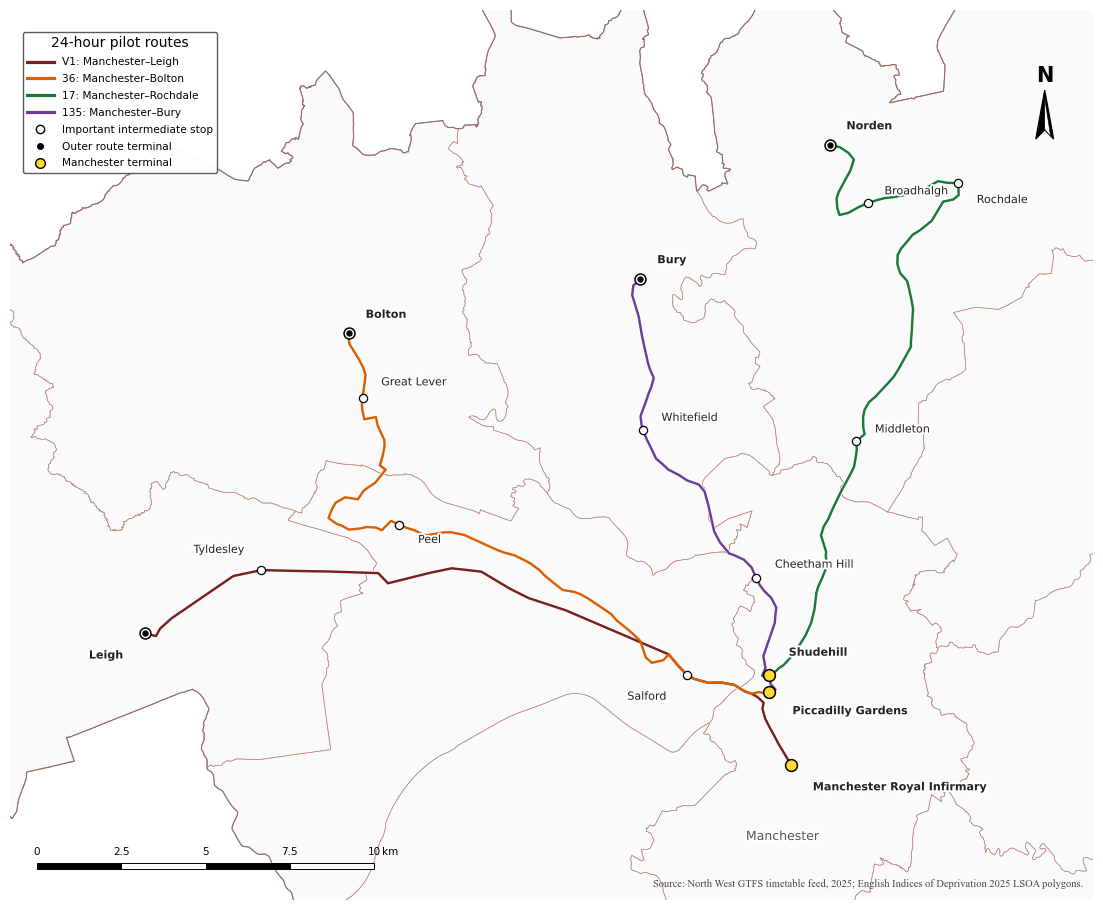

In [75]:
import re
import unicodedata
import zipfile

from shapely.geometry import LineString
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from pathlib import Path

# pilot route settings
pilot_route_numbers = [
    "V1",
    "36",
    "17",
    "135"
]

pilot_route_colours = {
    "V1": "#7A1F1F",
    "36": "#D95F02",
    "17": "#1B7837",
    "135": "#6A3D9A"
}

pilot_route_labels = {
    "V1": "V1: Manchester–Leigh",
    "36": "36: Manchester–Bolton",
    "17": "17: Manchester–Rochdale",
    "135": "135: Manchester–Bury"
}

pilot_route_keywords = {
    "V1": [
        "manchester",
        "leigh"
    ],
    "36": [
        "manchester",
        "bolton"
    ],
    "17": [
        "manchester",
        "rochdale"
    ],
    "135": [
        "manchester",
        "bury"
    ]
}

# number of representative stops shown on each route
representative_stops_per_route = 5

# route line widths
route_casing_width = 3.2
route_line_width = 2.0

# use the online light basemap
use_basemap = True

# GTFS timetable used for the pilot-route map
gtfs_path = Path(
    r"D:\final dissertation"
    r"\itm_north_west_gtfs_20251220.zip"
)

if not gtfs_path.exists():

    raise FileNotFoundError(
        f"GTFS archive not found:\n{gtfs_path}"
    )

if "gm_boundary" not in globals():

    raise NameError(
        "gm_boundary has not been defined."
    )

if "accessibility_output_dir" not in globals():

    accessibility_output_dir = (
        Path(r"D:\final dissertation")
        / "outputs"
    )

else:

    accessibility_output_dir = Path(
        accessibility_output_dir
    )

accessibility_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Greater Manchester boundary
gm_boundary_plot = gm_boundary.copy()

if gm_boundary_plot.crs is None:

    raise ValueError(
        "gm_boundary has no coordinate reference system."
    )

if gm_boundary_plot.crs.to_epsg() != 27700:

    gm_boundary_plot = (
        gm_boundary_plot
        .to_crs("EPSG:27700")
    )

try:

    gm_geometry = (
        gm_boundary_plot
        .geometry
        .union_all()
    )

except AttributeError:

    gm_geometry = (
        gm_boundary_plot
        .geometry
        .unary_union
    )

# small buffer prevents route endpoints being clipped
gm_geometry_buffered = (
    gm_geometry.buffer(2000)
)

# borough boundaries
plot_boroughs = False

if "boroughs_gm" in globals():

    boroughs_plot = boroughs_gm.copy()

    if boroughs_plot.crs is None:

        raise ValueError(
            "boroughs_gm has no coordinate reference system."
        )

    if boroughs_plot.crs.to_epsg() != 27700:

        boroughs_plot = (
            boroughs_plot
            .to_crs("EPSG:27700")
        )

    plot_boroughs = True

# read GTFS tables
with zipfile.ZipFile(
    gtfs_path,
    "r"
) as gtfs_zip:

    gtfs_files = set(
        gtfs_zip.namelist()
    )

    required_gtfs_files = {
        "routes.txt",
        "trips.txt",
        "stops.txt",
        "stop_times.txt"
    }

    missing_gtfs_files = (
        required_gtfs_files
        - gtfs_files
    )

    if missing_gtfs_files:

        raise FileNotFoundError(
            "The following GTFS files are missing:\n"
            + "\n".join(
                sorted(missing_gtfs_files)
            )
        )

    routes = pd.read_csv(
        gtfs_zip.open("routes.txt"),
        dtype=str
    )

    trips = pd.read_csv(
        gtfs_zip.open("trips.txt"),
        dtype=str
    )

    stops = pd.read_csv(
        gtfs_zip.open("stops.txt"),
        dtype=str
    )

    stop_times = pd.read_csv(
        gtfs_zip.open("stop_times.txt"),
        dtype=str,
        usecols=[
            "trip_id",
            "stop_id",
            "stop_sequence"
        ]
    )

# standardise GTFS fields
routes["route_short_name"] = (
    routes["route_short_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

if "route_long_name" not in routes.columns:

    routes["route_long_name"] = ""

routes["route_long_name"] = (
    routes["route_long_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

if "stop_name" not in stops.columns:

    stops["stop_name"] = stops["stop_id"]

stops["stop_name"] = (
    stops["stop_name"]
    .fillna("")
    .astype(str)
    .str.strip()
)

stops["stop_lon"] = pd.to_numeric(
    stops["stop_lon"],
    errors="coerce"
)

stops["stop_lat"] = pd.to_numeric(
    stops["stop_lat"],
    errors="coerce"
)

stop_times["stop_sequence"] = pd.to_numeric(
    stop_times["stop_sequence"],
    errors="coerce"
)

# create stop geometries
valid_stops = (
    stops
    .dropna(
        subset=[
            "stop_lon",
            "stop_lat"
        ]
    )
    .copy()
)

stops_gdf = gpd.GeoDataFrame(
    valid_stops,
    geometry=gpd.points_from_xy(
        valid_stops["stop_lon"],
        valid_stops["stop_lat"]
    ),
    crs="EPSG:4326"
)

stops_gdf = (
    stops_gdf
    .to_crs("EPSG:27700")
)

stops_gdf["inside_gm"] = (
    stops_gdf
    .geometry
    .within(gm_geometry_buffered)
)

gm_stop_ids = set(
    stops_gdf.loc[
        stops_gdf["inside_gm"],
        "stop_id"
    ]
)

# find candidate route IDs
candidate_routes = routes[
    routes["route_short_name"]
    .isin(pilot_route_numbers)
].copy()

if candidate_routes.empty:

    raise ValueError(
        "None of the pilot route numbers were found "
        "in routes.txt."
    )

candidate_trips = trips.merge(
    candidate_routes[
        [
            "route_id",
            "route_short_name",
            "route_long_name"
        ]
    ],
    on="route_id",
    how="inner"
)

candidate_trip_stops = (
    stop_times[
        stop_times["trip_id"]
        .isin(candidate_trips["trip_id"])
    ]
    .merge(
        candidate_trips[
            [
                "trip_id",
                "route_id",
                "route_short_name"
            ]
        ],
        on="trip_id",
        how="inner"
    )
)

candidate_trip_stops["inside_gm"] = (
    candidate_trip_stops["stop_id"]
    .isin(gm_stop_ids)
)

route_stop_scores = (
    candidate_trip_stops
    .groupby(
        [
            "route_short_name",
            "route_id"
        ]
    )
    .agg(
        gm_stop_records=(
            "inside_gm",
            "sum"
        ),
        total_stop_records=(
            "stop_id",
            "size"
        ),
        unique_gm_stops=(
            "stop_id",
            lambda values: (
                values[
                    candidate_trip_stops.loc[
                        values.index,
                        "inside_gm"
                    ]
                ]
                .nunique()
            )
        )
    )
    .reset_index()
)

route_stop_scores["gm_stop_share"] = (
    route_stop_scores["gm_stop_records"]
    / route_stop_scores["total_stop_records"]
)

# select one correct route_id for each pilot service
selected_route_records = []

for route_number in pilot_route_numbers:

    route_candidates = candidate_routes[
        candidate_routes[
            "route_short_name"
        ] == route_number
    ].copy()

    if route_candidates.empty:

        raise ValueError(
            f"Route {route_number} was not found."
        )

    route_candidates = route_candidates.merge(
        route_stop_scores,
        on=[
            "route_short_name",
            "route_id"
        ],
        how="left"
    )

    score_columns = [
        "gm_stop_records",
        "total_stop_records",
        "unique_gm_stops",
        "gm_stop_share"
    ]

    route_candidates[
        score_columns
    ] = route_candidates[
        score_columns
    ].fillna(0)

    keywords = pilot_route_keywords[
        route_number
    ]

    route_candidates["name_score"] = (
        route_candidates["route_long_name"]
        .apply(
            lambda name: sum(
                keyword in name
                for keyword in keywords
            )
        )
    )

    route_candidates = (
        route_candidates
        .sort_values(
            [
                "name_score",
                "unique_gm_stops",
                "gm_stop_share",
                "gm_stop_records"
            ],
            ascending=[
                False,
                False,
                False,
                False
            ]
        )
    )

    best_candidate = (
        route_candidates
        .iloc[0]
        .copy()
    )

    if best_candidate["unique_gm_stops"] == 0:

        raise ValueError(
            f"No Greater Manchester stops were found "
            f"for route {route_number}."
        )

    selected_route_records.append(
        best_candidate
    )

selected_routes = pd.DataFrame(
    selected_route_records
)

selected_route_ids = set(
    selected_routes["route_id"]
)

# select trips belonging to chosen routes
selected_trips = (
    trips[
        trips["route_id"]
        .isin(selected_route_ids)
    ]
    .merge(
        selected_routes[
            [
                "route_id",
                "route_short_name"
            ]
        ],
        on="route_id",
        how="inner"
    )
)

if selected_trips.empty:

    raise ValueError(
        "No trips were found for the selected routes."
    )

# join trips to ordered stops
route_stop_sequences = (
    stop_times
    .merge(
        selected_trips[
            [
                "trip_id",
                "route_id",
                "route_short_name"
            ]
        ],
        on="trip_id",
        how="inner"
    )
    .merge(
        stops[
            [
                "stop_id",
                "stop_name",
                "stop_lon",
                "stop_lat"
            ]
        ],
        on="stop_id",
        how="left"
    )
    .dropna(
        subset=[
            "stop_sequence",
            "stop_lon",
            "stop_lat"
        ]
    )
)

if route_stop_sequences.empty:

    raise ValueError(
        "No valid stop sequences were found."
    )

# stop matching
def normalise_stop_name(value):

    value = str(value).lower()

    value = unicodedata.normalize(
        "NFKD",
        value
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value
    )

    value = re.sub(
        r"\s+",
        " ",
        value
    ).strip()

    return value

# standardise every stop name
route_stop_sequences = (
    route_stop_sequences
    .copy()
)

route_stop_sequences[
    "_normalised_stop_name"
] = (
    route_stop_sequences[
        "stop_name"
    ]
    .fillna("")
    .map(normalise_stop_name)
)

# use the already projected stop layer created
stop_coordinate_lookup = (
    stops_gdf[
        [
            "stop_id",
            "geometry"
        ]
    ]
    .drop_duplicates(
        subset="stop_id"
    )
    .copy()
)

stop_coordinate_lookup[
    "_x"
] = (
    stop_coordinate_lookup
    .geometry
    .x
)

stop_coordinate_lookup[
    "_y"
] = (
    stop_coordinate_lookup
    .geometry
    .y
)

route_stop_sequences = (
    route_stop_sequences
    .merge(
        stop_coordinate_lookup[
            [
                "stop_id",
                "_x",
                "_y"
            ]
        ],
        on="stop_id",
        how="left"
    )
)

# project reference locations
reference_stop_records = []

for route_number, route_settings in (
    important_stop_settings.items()
):

    for position, stop_setting in enumerate(
        route_settings
    ):

        reference_stop_records.append(
            {
                "route_short_name":
                    route_number,

                "position":
                    position,

                "display_label":
                    stop_setting["label"],

                "reference_lon":
                    stop_setting["reference_lon"],

                "reference_lat":
                    stop_setting["reference_lat"]
            }
        )

reference_stops_gdf = gpd.GeoDataFrame(
    reference_stop_records,
    geometry=gpd.points_from_xy(
        [
            record["reference_lon"]
            for record in reference_stop_records
        ],
        [
            record["reference_lat"]
            for record in reference_stop_records
        ]
    ),
    crs="EPSG:4326"
).to_crs(
    "EPSG:27700"
)

reference_stops_gdf[
    "_reference_x"
] = (
    reference_stops_gdf
    .geometry
    .x
)

reference_stops_gdf[
    "_reference_y"
] = (
    reference_stops_gdf
    .geometry
    .y
)

# add processed values to important-stop settings
for _, reference_row in (
    reference_stops_gdf.iterrows()
):

    route_number = (
        reference_row[
            "route_short_name"
        ]
    )

    position = int(
        reference_row[
            "position"
        ]
    )

    stop_setting = (
        important_stop_settings[
            route_number
        ][position]
    )

    stop_setting[
        "_normalised_keywords"
    ] = [
        normalise_stop_name(keyword)
        for keyword in stop_setting[
            "keywords"
        ]
    ]

    stop_setting[
        "_normalised_required_tokens"
    ] = [
        normalise_stop_name(token)
        for token in stop_setting.get(
            "required_tokens",
            []
        )
    ]

    stop_setting[
        "_reference_x"
    ] = float(
        reference_row[
            "_reference_x"
        ]
    )

    stop_setting[
        "_reference_y"
    ] = float(
        reference_row[
            "_reference_y"
        ]
    )

# fast important-stop matching
def find_stop_match(
    trip_stops,
    stop_setting,
    maximum_fallback_distance=10000
):

    if trip_stops.empty:

        return None

    stop_names = (
        trip_stops[
            "_normalised_stop_name"
        ]
    )

    for normalised_keyword in (
        stop_setting[
            "_normalised_keywords"
        ]
    ):

        matching_mask = (
            stop_names
            .str.contains(
                normalised_keyword,
                regex=False,
                na=False
            )
        )

        if matching_mask.any():

            selected_row = (
                trip_stops.loc[
                    matching_mask
                ]
                .sort_values(
                    "stop_sequence"
                )
                .iloc[0]
                .copy()
            )

            selected_row[
                "match_method"
            ] = "stop-name match"

            return selected_row

    required_tokens = stop_setting[
        "_normalised_required_tokens"
    ]

    if required_tokens:

        token_mask = pd.Series(
            True,
            index=trip_stops.index
        )

        for token in required_tokens:

            token_mask &= (
                stop_names
                .str.contains(
                    token,
                    regex=False,
                    na=False
                )
            )

        if token_mask.any():

            selected_row = (
                trip_stops.loc[
                    token_mask
                ]
                .sort_values(
                    "stop_sequence"
                )
                .iloc[0]
                .copy()
            )

            selected_row[
                "match_method"
            ] = "token match"

            return selected_row

    valid_coordinates = (
        trip_stops[
            [
                "_x",
                "_y"
            ]
        ]
        .notna()
        .all(axis=1)
    )

    if not valid_coordinates.any():

        return None

    coordinate_candidates = (
        trip_stops.loc[
            valid_coordinates
        ]
        .copy()
    )

    distance_squared = (
        (
            coordinate_candidates["_x"]
            - stop_setting["_reference_x"]
        ) ** 2
        +
        (
            coordinate_candidates["_y"]
            - stop_setting["_reference_y"]
        ) ** 2
    )

    nearest_index = (
        distance_squared
        .idxmin()
    )

    nearest_distance = float(
        np.sqrt(
            distance_squared.loc[
                nearest_index
            ]
        )
    )

    if (
        nearest_distance
        > maximum_fallback_distance
    ):

        return None

    selected_row = (
        coordinate_candidates
        .loc[
            nearest_index
        ]
        .copy()
    )

    selected_row[
        "match_method"
    ] = "nearest route stop"

    selected_row[
        "match_distance_m"
    ] = nearest_distance

    return selected_row

# cache ordered stop records
trip_stop_groups = {}

for trip_id, trip_group in (
    route_stop_sequences
    .groupby(
        "trip_id",
        sort=False
    )
):

    trip_stop_groups[
        trip_id
    ] = (
        trip_group
        .sort_values(
            "stop_sequence"
        )
        .drop_duplicates(
            subset=[
                "stop_sequence",
                "stop_id"
            ]
        )
        .copy()
    )

route_trip_lookup = (
    route_stop_sequences
    .groupby(
        "route_short_name"
    )[
        "trip_id"
    ]
    .unique()
    .to_dict()
)

# score trips and select the best trip
trip_match_records = []

for route_number in pilot_route_numbers:

    route_trip_ids = (
        route_trip_lookup.get(
            route_number,
            []
        )
    )

    route_required_stops = (
        important_stop_settings[
            route_number
        ]
    )

    for trip_id in route_trip_ids:

        trip_stops = (
            trip_stop_groups[
                trip_id
            ]
        )

        matched_stop_count = 0

        for stop_setting in (
            route_required_stops
        ):

            matched_stop = find_stop_match(
                trip_stops,
                stop_setting
            )

            if matched_stop is not None:

                matched_stop_count += 1

        trip_match_records.append(
            {
                "route_short_name":
                    route_number,

                "trip_id":
                    trip_id,

                "matched_stop_count":
                    matched_stop_count,

                "trip_stop_count":
                    len(trip_stops)
            }
        )

trip_match_summary = pd.DataFrame(
    trip_match_records
)

if trip_match_summary.empty:

    raise ValueError(
        "No trips were available for important-stop matching."
    )

selected_display_trip_ids = {}

for route_number in pilot_route_numbers:

    route_trip_scores = (
        trip_match_summary[
            trip_match_summary[
                "route_short_name"
            ] == route_number
        ]
        .sort_values(
            [
                "matched_stop_count",
                "trip_stop_count"
            ],
            ascending=[
                False,
                False
            ]
        )
    )

    if route_trip_scores.empty:

        raise ValueError(
            f"No GTFS trips were available for route "
            f"{route_number}."
        )

    best_trip = (
        route_trip_scores
        .iloc[0]
    )

    selected_display_trip_ids[
        route_number
    ] = best_trip[
        "trip_id"
    ]

# extract required stops from selected trips
important_stop_records = []
missing_important_stops = []

for route_number in pilot_route_numbers:

    selected_trip_id = (
        selected_display_trip_ids[
            route_number
        ]
    )

    trip_stops = (
        trip_stop_groups[
            selected_trip_id
        ]
    )

    route_stop_settings = (
        important_stop_settings[
            route_number
        ]
    )

    for position, stop_setting in enumerate(
        route_stop_settings
    ):

        matched_stop = find_stop_match(
            trip_stops,
            stop_setting
        )

        if matched_stop is None:

            missing_important_stops.append(
                (
                    route_number,
                    stop_setting["label"]
                )
            )

            continue

        important_stop_records.append(
            {
                "route_short_name":
                    route_number,

                "trip_id":
                    selected_trip_id,

                "stop_id":
                    matched_stop["stop_id"],

                "stop_name":
                    matched_stop["stop_name"],

                "display_label":
                    stop_setting["label"],

                "match_method":
                    matched_stop.get(
                        "match_method",
                        "unknown"
                    ),

                "match_distance_m":
                    matched_stop.get(
                        "match_distance_m",
                        0
                    ),

                "stop_sequence":
                    float(
                        matched_stop[
                            "stop_sequence"
                        ]
                    ),

                "stop_lon":
                    float(
                        matched_stop[
                            "stop_lon"
                        ]
                    ),

                "stop_lat":
                    float(
                        matched_stop[
                            "stop_lat"
                        ]
                    ),

                "is_terminal":
                    (
                        position == 0
                        or position
                        == len(
                            route_stop_settings
                        ) - 1
                    ),

                "is_city_centre_terminal":
                    stop_setting[
                        "label"
                    ] in {
                        "Piccadilly Gardens",
                        "Shudehill",
                        "Manchester Royal Infirmary"
                    }
            }
        )

important_stops = pd.DataFrame(
    important_stop_records
)

if important_stops.empty:

    raise ValueError(
        "No specified important stops were matched."
    )

important_stops_gdf = gpd.GeoDataFrame(
    important_stops,
    geometry=gpd.points_from_xy(
        important_stops[
            "stop_lon"
        ],
        important_stops[
            "stop_lat"
        ]
    ),
    crs="EPSG:4326"
).to_crs(
    "EPSG:27700"
)

if missing_important_stops:

    print(
        "Specified stops not found:"
    )

    for route_number, stop_label in (
        missing_important_stops
    ):

        print(
            f"- {route_number}: {stop_label}"
        )

# build trimmed route geometries
trimmed_route_lines = []

for route_number in pilot_route_numbers:

    selected_trip_id = (
        selected_display_trip_ids[
            route_number
        ]
    )

    route_key_stops = (
        important_stops[
            important_stops[
                "route_short_name"
            ] == route_number
        ]
    )

    if len(route_key_stops) < 2:

        raise ValueError(
            f"Fewer than two important stops were matched "
            f"for route {route_number}."
        )

    minimum_sequence = (
        route_key_stops[
            "stop_sequence"
        ]
        .min()
    )

    maximum_sequence = (
        route_key_stops[
            "stop_sequence"
        ]
        .max()
    )

    trip_stops = (
        trip_stop_groups[
            selected_trip_id
        ]
    )

    trimmed_trip_stops = (
        trip_stops[
            trip_stops[
                "stop_sequence"
            ].between(
                minimum_sequence,
                maximum_sequence
            )
        ]
        .sort_values(
            "stop_sequence"
        )
        .dropna(
            subset=[
                "stop_lon",
                "stop_lat"
            ]
        )
    )

    coordinates = list(
        dict.fromkeys(
            zip(
                trimmed_trip_stops[
                    "stop_lon"
                ],
                trimmed_trip_stops[
                    "stop_lat"
                ]
            )
        )
    )

    if len(coordinates) < 2:

        raise ValueError(
            f"A valid route line could not be created "
            f"for route {route_number}."
        )

    trimmed_route_lines.append(
        {
            "route_short_name":
                route_number,

            "trip_id":
                selected_trip_id,

            "geometry":
                LineString(
                    coordinates
                )
        }
    )

pilot_routes_dissolved = gpd.GeoDataFrame(
    trimmed_route_lines,
    geometry="geometry",
    crs="EPSG:4326"
).to_crs(
    "EPSG:27700"
)

# remove duplicated labels at shared stops
important_stops_plot = (
    important_stops_gdf
    .sort_values(
        [
            "is_city_centre_terminal",
            "is_terminal"
        ],
        ascending=[
            False,
            False
        ]
    )
    .drop_duplicates(
        subset="display_label",
        keep="first"
    )
    .copy()
)

# borough labels
borough_label_points = None

if plot_boroughs:

    borough_label_points = (
        boroughs_plot
        .reset_index()
        .copy()
    )

    if "Borough" not in borough_label_points.columns:

        possible_name_columns = [
            column
            for column
            in borough_label_points.columns
            if column != "geometry"
        ]

        if possible_name_columns:

            borough_label_points = (
                borough_label_points
                .rename(
                    columns={
                        possible_name_columns[0]:
                        "Borough"
                    }
                )
            )

    borough_label_points[
        "label_point"
    ] = (
        borough_label_points
        .geometry
        .representative_point()
    )

important_place_names = {
    str(place_name).strip().lower()
    for place_name in important_stops_plot[
        "display_label"
    ]
}

if borough_label_points is not None:

    borough_label_points = (
        borough_label_points[
            ~borough_label_points[
                "Borough"
            ]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(
                important_place_names
            )
        ]
        .copy()
    )

# map extent
route_xmin, route_ymin, route_xmax, route_ymax = (
    pilot_routes_dissolved
    .total_bounds
)

route_width = (
    route_xmax - route_xmin
)

route_height = (
    route_ymax - route_ymin
)

horizontal_padding = max(
    route_width * 0.08,
    4000
)

vertical_padding = max(
    route_height * 0.08,
    4000
)

main_xlim = (
    route_xmin - horizontal_padding,
    route_xmax + horizontal_padding
)

main_ylim = (
    route_ymin - vertical_padding,
    route_ymax + vertical_padding
)

# north arrow
def add_north_arrow(
    axis,
    x=0.955,
    y=0.855,
    size=0.055
):

    axis.text(
        x,
        y + size * 1.08,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        color="black",
        zorder=40
    )

    outer_arrow = np.array([
        [x, y + size],
        [x - size * 0.15, y],
        [x, y + size * 0.19],
        [x + size * 0.15, y]
    ])

    outer_display = (
        axis.transAxes
        .transform(
            outer_arrow
        )
    )

    outer_data = (
        axis.transData
        .inverted()
        .transform(
            outer_display
        )
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=40
        )
    )

    inner_arrow = np.array([
        [x, y + size * 0.84],
        [x, y + size * 0.20],
        [x + size * 0.10, y + size * 0.05]
    ])

    inner_display = (
        axis.transAxes
        .transform(
            inner_arrow
        )
    )

    inner_data = (
        axis.transData
        .inverted()
        .transform(
            inner_display
        )
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.45,
            zorder=41
        )
    )

# scale bar
def add_scale_bar(
    axis,
    total_length_km=10,
    segments=4
):

    xmin_map, xmax_map = axis.get_xlim()
    ymin_map, ymax_map = axis.get_ylim()

    map_width = (
        xmax_map - xmin_map
    )

    map_height = (
        ymax_map - ymin_map
    )

    start_x = (
        xmin_map
        + map_width * 0.025
    )

    start_y = (
        ymin_map
        + map_height * 0.035
    )

    total_length_m = (
        total_length_km * 1000
    )

    segment_length = (
        total_length_m / segments
    )

    bar_height = (
        map_height * 0.007
    )

    for segment in range(
        segments
    ):

        colour = (
            "black"
            if segment % 2 == 0
            else "white"
        )

        axis.add_patch(
            Rectangle(
                (
                    start_x
                    + segment
                    * segment_length,
                    start_y
                ),
                segment_length,
                bar_height,
                facecolor=colour,
                edgecolor="black",
                linewidth=0.7,
                zorder=35
            )
        )

    scale_values = np.linspace(
        0,
        total_length_km,
        segments + 1
    )

    for value in scale_values:

        axis.text(
            start_x + value * 1000,
            start_y
            + bar_height
            + map_height * 0.006,
            f"{value:g}",
            ha="center",
            va="bottom",
            fontsize=7.5,
            color="black",
            zorder=35
        )

    axis.text(
        start_x
        + total_length_m
        + map_width * 0.007,
        start_y
        + bar_height
        + map_height * 0.006,
        "km",
        ha="left",
        va="bottom",
        fontsize=7.5,
        color="black",
        zorder=35
    )

# plot route lines
def plot_routes(
    axis
):

    for route_number in pilot_route_numbers:

        route_layer = pilot_routes_dissolved[
            pilot_routes_dissolved[
                "route_short_name"
            ] == route_number
        ]

        if route_layer.empty:

            continue

        route_layer.plot(
            ax=axis,
            color="white",
            linewidth=2.8,
            zorder=10
        )

        route_layer.plot(
            ax=axis,
            color=pilot_route_colours[
                route_number
            ],
            linewidth=1.75,
            zorder=11
        )

# label positions
stop_label_offsets = {
    "Leigh": (
        -650,
        -650,
        "right"
    ),
    "Tyldesley": (
        -500,
        600,
        "right"
    ),
    "Salford": (
        -600,
        -650,
        "right"
    ),
    "Manchester Royal Infirmary": (
        650,
        -650,
        "left"
    ),

    "Bolton": (
        500,
        550,
        "left"
    ),
    "Great Lever": (
        550,
        450,
        "left"
    ),
    "Peel": (
        550,
        -450,
        "left"
    ),
    "Piccadilly Gardens": (
        700,
        -550,
        "left"
    ),

    "Norden": (
        500,
        550,
        "left"
    ),
    "Broadhalgh": (
        500,
        350,
        "left"
    ),
    "Rochdale": (
        550,
        -500,
        "left"
    ),
    "Middleton": (
        550,
        350,
        "left"
    ),
    "Shudehill": (
        600,
        650,
        "left"
    ),

    "Bury": (
        500,
        550,
        "left"
    ),
    "Whitefield": (
        550,
        350,
        "left"
    ),
    "Cheetham Hill": (
        550,
        400,
        "left"
    )
}

# plot all specified important stops
def plot_important_stops(
    axis
):

    intermediate_stops = (
        important_stops_plot[
            ~important_stops_plot[
                "is_terminal"
            ]
        ]
    )

    outer_terminals = (
        important_stops_plot[
            important_stops_plot[
                "is_terminal"
            ]
            & ~important_stops_plot[
                "is_city_centre_terminal"
            ]
        ]
    )

    city_terminals = (
        important_stops_plot[
            important_stops_plot[
                "is_city_centre_terminal"
            ]
        ]
    )

    if not intermediate_stops.empty:

        intermediate_stops.plot(
            ax=axis,
            marker="o",
            facecolor="white",
            edgecolor="black",
            linewidth=0.9,
            markersize=35,
            zorder=20
        )

    if not outer_terminals.empty:

        outer_terminals.plot(
            ax=axis,
            marker="o",
            facecolor="white",
            edgecolor="black",
            linewidth=1.1,
            markersize=62,
            zorder=21
        )

        outer_terminals.plot(
            ax=axis,
            marker="o",
            facecolor="black",
            edgecolor="black",
            markersize=13,
            zorder=22
        )

    if not city_terminals.empty:

        city_terminals.plot(
            ax=axis,
            marker="o",
            facecolor="#FFD92F",
            edgecolor="black",
            linewidth=1.1,
            markersize=72,
            zorder=23
        )

    for _, row in important_stops_plot.iterrows():

        label_text = row[
            "display_label"
        ]

        offset_x, offset_y, alignment = (
            stop_label_offsets.get(
                label_text,
                (
                    450,
                    350,
                    "left"
                )
            )
        )

        label = axis.text(
            row.geometry.x + offset_x,
            row.geometry.y + offset_y,
            label_text,
            fontsize=8,
            fontweight=(
                "bold"
                if row["is_terminal"]
                else "normal"
            ),
            color="#222222",
            ha=alignment,
            va="center",
            zorder=25
        )

        label.set_path_effects([
            path_effects.Stroke(
                linewidth=2.8,
                foreground="white"
            ),
            path_effects.Normal()
        ])

# create map
fig, ax = plt.subplots(
    figsize=(
        15,
        10
    )
)

ax.set_xlim(
    main_xlim
)

ax.set_ylim(
    main_ylim
)

gm_boundary_plot.plot(
    ax=ax,
    facecolor="#FAFAFA",
    edgecolor="#755252",
    linewidth=0.8,
    zorder=1
)

if plot_boroughs:

    boroughs_plot.boundary.plot(
        ax=ax,
        color="#B77C72",
        linewidth=0.45,
        alpha=0.85,
        zorder=2
    )

plot_routes(
    axis=ax
)

plot_important_stops(
    axis=ax
)

# borough labels without duplicated place names
if (
    plot_boroughs
    and borough_label_points is not None
):

    for _, row in borough_label_points.iterrows():

        label_point = row[
            "label_point"
        ]

        if not (
            main_xlim[0]
            <= label_point.x
            <= main_xlim[1]
            and main_ylim[0]
            <= label_point.y
            <= main_ylim[1]
        ):

            continue

        borough_text = ax.text(
            label_point.x,
            label_point.y,
            row["Borough"],
            ha="center",
            va="center",
            fontsize=9,
            color="#555555",
            zorder=5
        )

        borough_text.set_path_effects([
            path_effects.Stroke(
                linewidth=2.8,
                foreground="white"
            ),
            path_effects.Normal()
        ])

# legend with complete route descriptions
legend_handles = [
    Line2D(
        [0],
        [0],
        color=pilot_route_colours[
            route_number
        ],
        linewidth=2.3,
        label=pilot_route_labels[
            route_number
        ]
    )
    for route_number in pilot_route_numbers
]

legend_handles.extend([
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=6,
        label="Important intermediate stop"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=4,
        label="Outer route terminal"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#FFD92F",
        markeredgecolor="black",
        markersize=7,
        label="Manchester terminal"
    )
])

ax.legend(
    handles=legend_handles,
    title="24-hour pilot routes",
    loc="upper left",
    bbox_to_anchor=(
        0.012,
        0.975
    ),
    borderaxespad=0,
    frameon=True,
    framealpha=0.97,
    facecolor="white",
    edgecolor="#555555",
    fontsize=7.6,
    title_fontsize=10,
    handlelength=2.5,
    labelspacing=0.65
)

# map formatting
ax.set_aspect(
    "equal"
)

ax.set_axis_off()

add_north_arrow(
    axis=ax
)

add_scale_bar(
    axis=ax,
    total_length_km=10,
    segments=4
)

# source information
source_note = (
    "Source: North West GTFS timetable feed, 2025; "
    "English Indices of Deprivation 2025 LSOA polygons."
)

ax.text(
    0.99,
    0.012,
    source_note,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.5,
    family="Times New Roman",
    color="#444444",
    zorder=40
)

fig.subplots_adjust(
    left=0.015,
    right=0.99,
    top=0.93,
    bottom=0.040
)

# save map
pilot_route_map_output = (
    accessibility_output_dir
    / "greater_manchester_24_hour_bus_pilot_routes.png"
)

plt.savefig(
    pilot_route_map_output,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(
    fig
)

## 3.3 Accessibility Modeling

### 3.3.1 Accessibility Measure and Routing

Public transport accessibility was modelled using the r5py package, which constructs an R5 transport network from the GTFS timetable and OSM road network. LSOA representative points were used as origins, while LSOAs containing hospitality employment were used as destinations. R5 estimated public transport travel times, including walking access and egress, waiting, transfers and in-vehicle travel, and generated an origin–destination travel-time matrix between the two sets of locations.
Accessibility was measured using the cumulative opportunity approach. For each origin LSOA, hospitality employment in destination LSOAs reachable within the selected travel-time threshold was summed. The accessibility measure can be expressed as:

A_i=∑_j▒〖W_j f(c_ij)〗

where Ai represents accessibility at origin i, W_j represents the number of accommodation-sector employment opportunities at destination j,[JV1.1] and c_ij represents the public transport travel time between the origin and destination. The impedance function f(c_ij)is defined as:

f(c_ij )={█(1,&c_ij≤T@0,&c_ij＞T)┤

where T is the selected travel-time threshold. Employment opportunities that can be reached within the threshold contribute to the accessibility score, whereas destinations beyond the threshold are excluded.

### 3.3.2 Pilot Scenario Design

The North West England GTFS timetable obtained from the Bus Open Data Service (BODS) Archive was used to construct two night-time public transport scenarios. Two night-time public transport scenarios were modelled to evaluate the accessibility effect of the Bee Network 24-hour bus pilot. The with-pilot scenario retained the overnight services on routes V1, 36, 17 and 135, while the without-pilot scenario used the same GTFS timetable but excluded the overnight pilots. 20 December 2025 was selected because it was a Saturday within the normal pre-Christmas service period, when all four pilot routes were scheduled to operate overnight.

In [ ]:
from pathlib import Path
from datetime import timedelta
import zipfile

from IPython.display import display, HTML

# file path
gtfs_path = Path(
    r"D:\final dissertation"
    r"\itm_north_west_gtfs_20251220.zip"
)

analysis_date = pd.Timestamp("2025-12-20")

night_start = pd.Timestamp(
    "2025-12-20 00:00:00"
)

night_end = pd.Timestamp(
    "2025-12-20 06:00:00"
)

pilot_routes = [
    "V1",
    "36",
    "17",
    "135"
]

route_settings = {

    "V1": {
        "outer": ["leigh"],
        "city": [
            "manchester royal infirmary",
            "piccadilly gardens",
            "manchester"
        ],
        "outer_label": "Leigh"
    },

    "36": {
        "outer": ["bolton"],
        "city": [
            "piccadilly gardens",
            "manchester"
        ],
        "outer_label": "Bolton"
    },

    "17": {
        "outer": [
            "rochdale",
            "norden"
        ],
        "city": [
            "shudehill",
            "manchester"
        ],
        "outer_label": "Rochdale"
    },

    "135": {
        "outer": ["bury"],
        "city": [
            "piccadilly gardens",
            "shudehill",
            "manchester"
        ],
        "outer_label": "Bury"
    }
}

if not gtfs_path.exists():

    raise FileNotFoundError(
        f"GTFS file not found:\n{gtfs_path}"
    )

# read GTFS
def find_gtfs_file(
    zip_file,
    filename
):

    matches = [
        name
        for name in zip_file.namelist()
        if name.lower().endswith(
            filename.lower()
        )
    ]

    if not matches:

        raise FileNotFoundError(
            f"{filename} not found in GTFS."
        )

    return matches[0]

with zipfile.ZipFile(
    gtfs_path,
    "r"
) as gtfs_zip:

    routes = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "routes.txt"
            )
        ),
        dtype=str
    )

    trips = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "trips.txt"
            )
        ),
        dtype=str
    )

    stop_times = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "stop_times.txt"
            )
        ),
        dtype=str
    )

    stops = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "stops.txt"
            )
        ),
        dtype=str
    )

    calendar = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "calendar.txt"
            )
        ),
        dtype=str
    )

    calendar_dates = pd.read_csv(
        gtfs_zip.open(
            find_gtfs_file(
                gtfs_zip,
                "calendar_dates.txt"
            )
        ),
        dtype=str
    )

# clean fields
routes["route_short_name"] = (
    routes["route_short_name"]
    .fillna("")
    .str.strip()
)

stops["stop_name"] = (
    stops["stop_name"]
    .fillna("")
    .str.strip()
)

if "direction_id" not in trips.columns:
    trips["direction_id"] = "0"

trips["direction_id"] = (
    trips["direction_id"]
    .fillna("0")
)

# identify Greater Manchester route IDs
selected_route_ids = []

for route_number, settings in route_settings.items():

    candidate_route_ids = (
        routes.loc[
            routes["route_short_name"]
            == route_number,
            "route_id"
        ]
        .dropna()
        .unique()
    )

    for route_id in candidate_route_ids:

        candidate_trip_ids = (
            trips.loc[
                trips["route_id"] == route_id,
                "trip_id"
            ]
        )

        candidate_stop_ids = (
            stop_times.loc[
                stop_times["trip_id"].isin(
                    candidate_trip_ids
                ),
                "stop_id"
            ]
            .dropna()
            .unique()
        )

        stop_name_text = " ".join(
            stops.loc[
                stops["stop_id"].isin(
                    candidate_stop_ids
                ),
                "stop_name"
            ]
            .str.lower()
            .tolist()
        )

        has_outer = any(
            keyword in stop_name_text
            for keyword in settings["outer"]
        )

        has_city = any(
            keyword in stop_name_text
            for keyword in settings["city"]
        )

        if has_outer and has_city:

            selected_route_ids.append(
                route_id
            )

selected_routes = routes[
    routes["route_id"].isin(
        selected_route_ids
    )
][
    [
        "route_id",
        "route_short_name"
    ]
].drop_duplicates()

# select pilot trips
pilot_trips = trips[
    trips["route_id"].isin(
        selected_route_ids
    )
].copy()

# identify active services
def get_active_services(
    service_date
):

    weekday = (
        service_date
        .day_name()
        .lower()
    )

    date_value = (
        service_date
        .strftime("%Y%m%d")
    )

    active = set(
        calendar.loc[
            (
                calendar["start_date"]
                <= date_value
            )
            &
            (
                calendar["end_date"]
                >= date_value
            )
            &
            (
                calendar[weekday]
                == "1"
            ),
            "service_id"
        ]
        .astype(str)
    )

    exceptions = calendar_dates[
        calendar_dates["date"]
        == date_value
    ]

    active.update(
        exceptions.loc[
            exceptions["exception_type"]
            == "1",
            "service_id"
        ].astype(str)
    )

    active.difference_update(
        exceptions.loc[
            exceptions["exception_type"]
            == "2",
            "service_id"
        ].astype(str)
    )

    return active

# convert GTFS time
def gtfs_time_to_datetime(
    service_date,
    value
):

    if pd.isna(value):
        return pd.NaT

    hour, minute, second = map(
        int,
        str(value).split(":")
    )

    return (
        service_date.normalize()
        + timedelta(
            hours=hour,
            minutes=minute,
            seconds=second
        )
    )

# first and last stop of every trip
pilot_stop_times = stop_times[
    stop_times["trip_id"].isin(
        pilot_trips["trip_id"]
    )
].copy()

pilot_stop_times[
    "stop_sequence_num"
] = pd.to_numeric(
    pilot_stop_times["stop_sequence"],
    errors="coerce"
)

pilot_stop_times = (
    pilot_stop_times
    .sort_values(
        [
            "trip_id",
            "stop_sequence_num"
        ]
    )
)

first_stops = (
    pilot_stop_times
    .groupby(
        "trip_id",
        as_index=False
    )
    .first()
    [
        [
            "trip_id",
            "stop_id",
            "departure_time"
        ]
    ]
    .rename(
        columns={
            "stop_id": "origin_stop_id"
        }
    )
)

last_stops = (
    pilot_stop_times
    .groupby(
        "trip_id",
        as_index=False
    )
    .last()
    [
        [
            "trip_id",
            "stop_id"
        ]
    ]
    .rename(
        columns={
            "stop_id":
                "destination_stop_id"
        }
    )
)

stop_lookup = stops[
    [
        "stop_id",
        "stop_name"
    ]
]

first_stops = first_stops.merge(
    stop_lookup.rename(
        columns={
            "stop_id": "origin_stop_id",
            "stop_name": "Origin"
        }
    ),
    on="origin_stop_id",
    how="left"
)

last_stops = last_stops.merge(
    stop_lookup.rename(
        columns={
            "stop_id":
                "destination_stop_id",

            "stop_name":
                "Destination"
        }
    ),
    on="destination_stop_id",
    how="left"
)

pilot_trips = (
    pilot_trips
    .merge(
        first_stops,
        on="trip_id",
        how="left"
    )
    .merge(
        last_stops,
        on="trip_id",
        how="left"
    )
    .merge(
        selected_routes,
        on="route_id",
        how="left"
    )
)

# previous service day
service_dates = [
    analysis_date
    - pd.Timedelta(days=1),

    analysis_date
]

records = []

for service_date in service_dates:

    active_services = (
        get_active_services(
            service_date
        )
    )

    active_trips = pilot_trips[
        pilot_trips["service_id"].isin(
            active_services
        )
    ].copy()

    if active_trips.empty:
        continue

    active_trips[
        "departure_datetime"
    ] = (
        active_trips[
            "departure_time"
        ]
        .apply(
            lambda value:
            gtfs_time_to_datetime(
                service_date,
                value
            )
        )
    )

    records.append(
        active_trips
    )

night_trips = pd.concat(
    records,
    ignore_index=True
)

# overnight period
night_trips = night_trips[
    (
        night_trips[
            "departure_datetime"
        ] >= night_start
    )
    &
    (
        night_trips[
            "departure_datetime"
        ] < night_end
    )
].copy()

# main route directions
route_direction_settings = {

    "V1": {
        "outer_keywords": ["leigh"],
        "city_keywords": [
            "manchester royal infirmary",
            "manchester"
        ],
        "outer_direction":
            "Manchester Royal Infirmary → Leigh Bus Station",
        "city_direction":
            "Leigh Bus Station → Manchester Royal Infirmary"
    },

    "36": {
        "outer_keywords": ["bolton"],
        "city_keywords": [
            "piccadilly gardens",
            "manchester"
        ],
        "outer_direction":
            "Piccadilly Gardens → Bolton Interchange",
        "city_direction":
            "Bolton Interchange → Piccadilly Gardens"
    },

    "17": {
        "outer_keywords": [
            "rochdale",
            "norden"
        ],
        "city_keywords": [
            "shudehill",
            "manchester"
        ],
        "outer_direction":
            "Shudehill Interchange → Rochdale Interchange",
        "city_direction":
            "Rochdale Interchange → Shudehill Interchange"
    },

    "135": {
        "outer_keywords": ["bury"],
        "city_keywords": [
            "piccadilly gardens",
            "shudehill",
            "manchester"
        ],
        "outer_direction":
            "Piccadilly Gardens → Bury Interchange",
        "city_direction":
            "Bury Interchange → Piccadilly Gardens"
    }
}

# identify direction for each route-direction group
def get_direction_label(group):

    route = group[
        "route_short_name"
    ].iloc[0]

    settings = (
        route_direction_settings[
            route
        ]
    )

    destinations = " ".join(
        group["Destination"]
        .fillna("")
        .str.lower()
        .tolist()
    )

    if any(
        keyword in destinations
        for keyword in settings[
            "outer_keywords"
        ]
    ):
        return (
            settings[
                "outer_direction"
            ]
        )

    if any(
        keyword in destinations
        for keyword in settings[
            "city_keywords"
        ]
    ):
        return (
            settings[
                "city_direction"
            ]
        )

    return (
        f"Direction "
        f"{group['direction_id'].iloc[0]}"
    )

# create compact timetable
summary_rows = []

for (
    route_number,
    direction_id
), group in night_trips.groupby(
    [
        "route_short_name",
        "direction_id"
    ]
):

    departures = (
        group[
            "departure_datetime"
        ]
        .dropna()
        .sort_values()
        .dt.strftime("%H:%M")
        .tolist()
    )

    summary_rows.append(
        {
            "Route":
                route_number,

            "Direction":
                get_direction_label(
                    group
                ),

            "Overnight departures (00:00–06:00)":
                ", ".join(
                    departures
                ),

            "Number of departures":
                group[
                    "trip_id"
                ].nunique()
        }
    )

pilot_timetable = pd.DataFrame(
    summary_rows
)

# sort routes and directions
route_order = {
    "V1": 1,
    "36": 2,
    "17": 3,
    "135": 4
}

pilot_timetable[
    "_route_order"
] = (
    pilot_timetable[
        "Route"
    ]
    .map(
        route_order
    )
)

pilot_timetable = (
    pilot_timetable
    .sort_values(
        [
            "_route_order",
            "Direction"
        ]
    )
    .drop(
        columns="_route_order"
    )
    .reset_index(
        drop=True
    )
)

# route number
pilot_timetable.loc[
    pilot_timetable[
        "Route"
    ].duplicated(),
    "Route"
] = ""

# display compact table
table_html = (
    pilot_timetable
    .to_html(
        index=False,
        border=0,
        classes="pilot-timetable"
    )
)

display(
    HTML(
        f"""
        <style>

        .table-container {{
            width: 100%;
            overflow-x: auto;
            font-family:
                "Times New Roman",
                Times,
                serif;
        }}

        table.pilot-timetable {{
            width: 100%;
            border-collapse: collapse;
            font-size: 12.5px;
            line-height: 1.35;
            border-top: 1.5px solid black;
            border-bottom: 1.5px solid black;
        }}

        table.pilot-timetable thead th {{
            text-align: center !important;
            vertical-align: middle !important;
            font-weight: bold;
            padding: 7px 8px;
            border-bottom: 1px solid black;
        }}

        table.pilot-timetable tbody td {{
            vertical-align: middle;
            padding: 7px 8px;
            border: none;
        }}

        /* Route */
        table.pilot-timetable
        th:nth-child(1),
        table.pilot-timetable
        td:nth-child(1) {{
            width: 8%;
            text-align: center;
            white-space: nowrap;
        }}

        /* Direction */
        table.pilot-timetable
        th:nth-child(2),
        table.pilot-timetable
        td:nth-child(2) {{
            width: 32%;
            text-align: left;
            white-space: nowrap;
        }}

        /* Departures */
        table.pilot-timetable
        th:nth-child(3),
        table.pilot-timetable
        td:nth-child(3) {{
            width: 48%;
            text-align: center;
        }}

        /* Number */
        table.pilot-timetable
        th:nth-child(4),
        table.pilot-timetable
        td:nth-child(4) {{
            width: 12%;
            text-align: center;
        }}

        </style>

        <div class="table-container">
            {table_html}
        </div>
        """
    )
)

Route,Direction,Overnight departures (00:00–06:00),Number of departures
V1,Leigh Bus Station → Manchester Royal Infirmary,"00:00, 01:00, 02:00, 03:00, 04:00, 05:00",6
,Manchester Royal Infirmary → Leigh Bus Station,"00:00, 00:30, 01:30, 02:30, 03:30, 04:30, 05:30",7
36,Bolton Interchange → Piccadilly Gardens,"00:45, 01:45, 02:45, 03:45, 04:51, 05:21, 05:51",7
,Piccadilly Gardens → Bolton Interchange,"00:55, 01:55, 02:55, 03:55, 04:55",5
17,Rochdale Interchange → Shudehill Interchange,"00:04, 00:34, 01:34, 02:34, 03:34, 04:30, 04:34, 05:05, 05:09, 05:39",10
,Shudehill Interchange → Rochdale Interchange,"00:42, 01:42, 02:42, 03:42, 04:42, 05:15, 05:45",7
135,Bury Interchange → Piccadilly Gardens,"00:25, 01:25, 02:25, 03:25, 04:25, 05:11, 05:41",7
,Piccadilly Gardens → Bury Interchange,"00:15, 01:15, 02:15, 03:15, 04:15, 05:15, 05:55",7


Table 1 summarises the timetable of the four pilot routes. Based on the schedules, 02:00–03:00 period was selected because it falls within the core overnight operating period, avoiding the transition around midnight and the increase in early-morning services towards the end of the night. All pilots operate in both directions during this hour, providing a consistent period for evaluating the accessibility effect of the pilot. A one-hour departure window was used to account for the low frequency and different timings of overnight services. The same origins, destinations, travel modes and travel-time threshold were applied in both scenarios. The 45-minute threshold was selected as a reasonable public transport commuting time and was used to calculate the number of hospitality employment opportunities accessible from each LSOA. Keeping these parameters unchanged allowed the two scenarios to be compared directly.
Accessibility change for each LSOA was calculated as:

〖∆A〗_i= A_i^P-A_i^C

Where A_i^Prepresents accessibility under the pilot scenario and A_i^C represents accessibility under the counterfactual scenario. Positive values of 〖∆A〗_i indicate higher accessibility under the pilot scenario, zero indicates no change, and negative values indicate lower accessibility.

## 3.4 Data Preparation

### 3.4.1 GTFS Data

In [8]:
# file paths
gtfs_path = (
    r"D:\final dissertation"
    r"\itm_north_west_gtfs_20251220.zip"
)

output_dir = r"D:\final dissertation\outputs"
os.makedirs(output_dir, exist_ok=True)

# load the core GTFS tables
with zipfile.ZipFile(gtfs_path, "r") as gtfs_zip:

    agency = pd.read_csv(
        gtfs_zip.open("agency.txt"),
        dtype=str
    )

    routes = pd.read_csv(
        gtfs_zip.open("routes.txt"),
        dtype=str
    )

    trips = pd.read_csv(
        gtfs_zip.open("trips.txt"),
        dtype=str
    )

    stop_times = pd.read_csv(
        gtfs_zip.open("stop_times.txt"),
        dtype=str,
        usecols=[
            "trip_id",
            "arrival_time",
            "departure_time",
            "stop_id",
            "stop_sequence"
        ]
    )

    stops = pd.read_csv(
        gtfs_zip.open("stops.txt"),
        dtype=str
    )

    calendar = pd.read_csv(
        gtfs_zip.open("calendar.txt"),
        dtype=str
    )

    if "calendar_dates.txt" in gtfs_zip.namelist():
        calendar_dates = pd.read_csv(
            gtfs_zip.open("calendar_dates.txt"),
            dtype=str
        )
    else:
        calendar_dates = pd.DataFrame()

In [ ]:
# convert required columns to numeric format
routes["route_type"] = pd.to_numeric(
    routes["route_type"],
    errors="coerce"
)

stops["stop_lat"] = pd.to_numeric(
    stops["stop_lat"],
    errors="coerce"
)

stops["stop_lon"] = pd.to_numeric(
    stops["stop_lon"],
    errors="coerce"
)

stop_times["stop_sequence"] = pd.to_numeric(
    stop_times["stop_sequence"],
    errors="coerce"
)

# remove records without valid coordinates
stops = stops.dropna(
    subset=["stop_lat", "stop_lon"]
).copy()

# retain bus and tram services
selected_routes = routes[
    routes["route_type"].isin([0, 3])
].copy()

selected_route_ids = set(
    selected_routes["route_id"]
)

selected_trips = trips[
    trips["route_id"].isin(selected_route_ids)
].copy()

selected_trip_ids = set(
    selected_trips["trip_id"]
)

selected_stop_times = stop_times[
    stop_times["trip_id"].isin(selected_trip_ids)
].copy()

selected_stop_ids = set(
    selected_stop_times["stop_id"]
)

selected_stops = stops[
    stops["stop_id"].isin(selected_stop_ids)
].copy()

mode_names = {
    0: "Tram",
    3: "Bus"
}

route_summary = (
    selected_routes["route_type"]
    .value_counts()
    .sort_index()
    .rename_axis("route_type")
    .reset_index(name="number_of_routes")
)

route_summary["mode"] = (
    route_summary["route_type"]
    .map(mode_names)
)

In [10]:
# create GTFS stop geometries
stops_gdf = gpd.GeoDataFrame(
    selected_stops,
    geometry=gpd.points_from_xy(
        selected_stops["stop_lon"],
        selected_stops["stop_lat"]
    ),
    crs="EPSG:4326"
)

# transform to British National Grid
stops_gdf = stops_gdf.to_crs("EPSG:27700")

if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs("EPSG:27700")

# select stops within Greater Manchester
stops_gm = gpd.sjoin(
    stops_gdf,
    gm_boundary[["geometry"]],
    predicate="within",
    how="inner"
)

stops_gm = (
    stops_gm
    .drop(columns=["index_right"])
    .drop_duplicates(subset="stop_id")
    .copy()
)

# identify the transport mode serving each stop
trip_modes = selected_trips.merge(
    selected_routes[
        ["route_id", "route_type"]
    ],
    on="route_id",
    how="left"
)

stop_modes = (
    selected_stop_times[
        ["trip_id", "stop_id"]
    ]
    .merge(
        trip_modes[
            ["trip_id", "route_type"]
        ],
        on="trip_id",
        how="left"
    )
    .drop_duplicates()
)

bus_stop_ids = set(
    stop_modes.loc[
        stop_modes["route_type"] == 3,
        "stop_id"
    ]
)

tram_stop_ids = set(
    stop_modes.loc[
        stop_modes["route_type"] == 0,
        "stop_id"
    ]
)

bus_stops_gm = stops_gm[
    stops_gm["stop_id"].isin(bus_stop_ids)
].copy()

tram_stops_gm = stops_gm[
    stops_gm["stop_id"].isin(tram_stop_ids)
].copy()

# create a GTFS summary table
gtfs_summary = pd.DataFrame({
    "Indicator": [
        "Geographic feed",
        "Modes retained",
        "Routes retained",
        "Trips retained",
        "Stop-time records retained",
        "Bus stop records within Greater Manchester",
        "Metrolink stop records within Greater Manchester"
    ],
    "Value": [
        "North West England",
        "Bus and Tram",
        len(selected_routes),
        len(selected_trips),
        len(selected_stop_times),
        bus_stops_gm["stop_id"].nunique(),
        tram_stops_gm["stop_id"].nunique()
    ]
})

The GTFS dataset contained route, trip, stop and stop-time records used to construct the public transport network. Only bus and tram (Metrolink) services within Greater Manchester were retained. The corresponding stops were converted to spatial point features, projected to the British National Grid and clipped to the study area, resulting in 12,510 stops used in the accessibility modelling. As GTFS represents scheduled services, it does not capture real-time operating conditions.

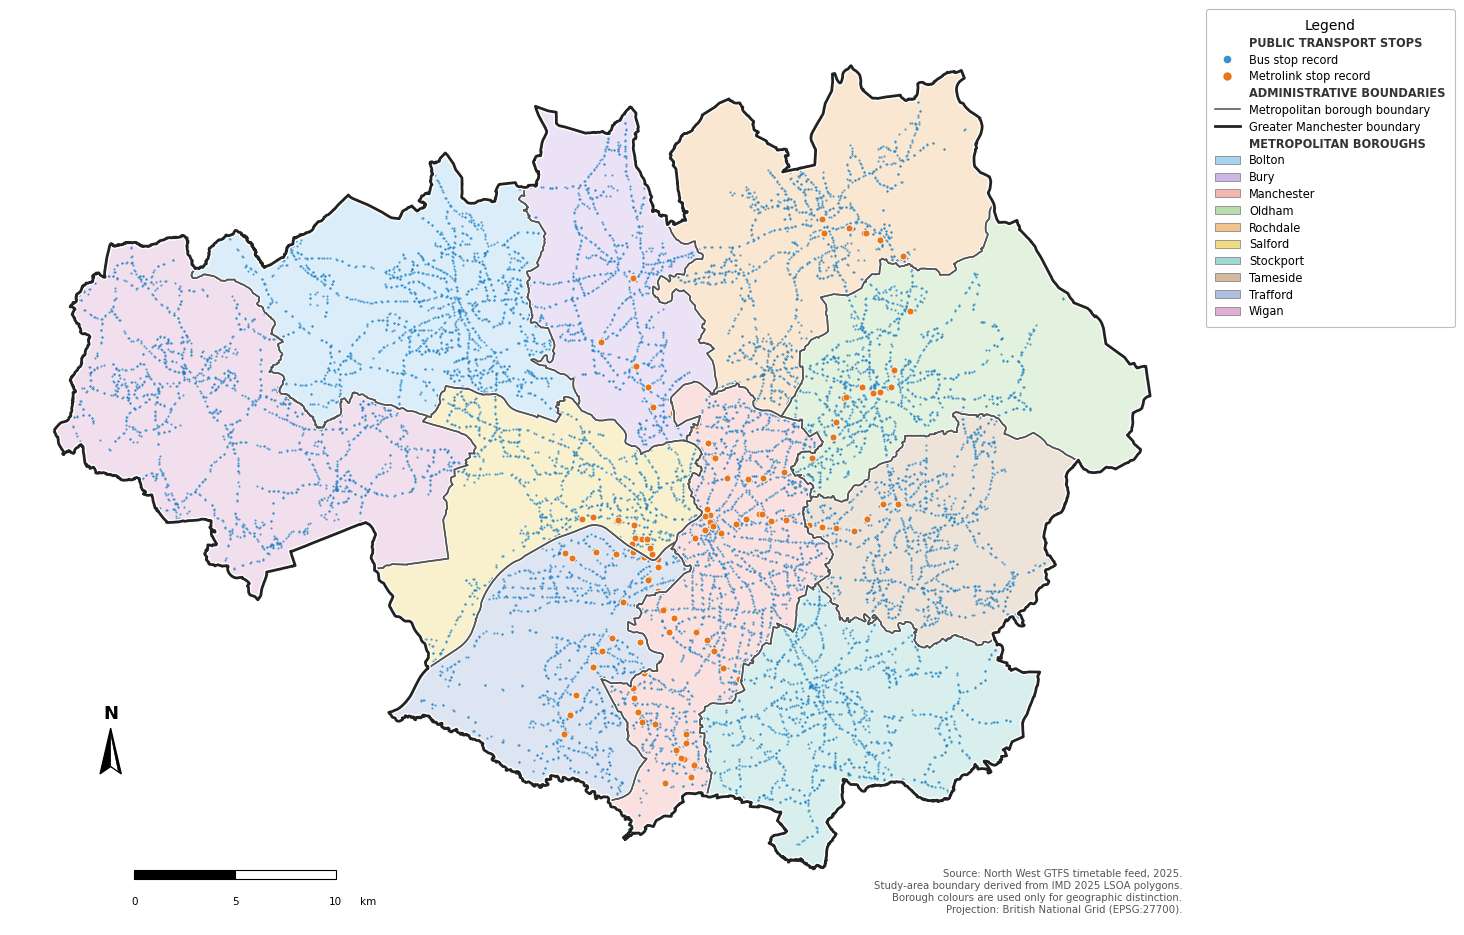

In [ ]:
from matplotlib.patches import Rectangle, Polygon, Patch

# ensure that all layers use British National Grid
analysis_crs = "EPSG:27700"

if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs(analysis_crs)

if boroughs_gm.crs.to_epsg() != 27700:
    boroughs_gm = boroughs_gm.to_crs(analysis_crs)

if bus_stops_gm.crs.to_epsg() != 27700:
    bus_stops_gm = bus_stops_gm.to_crs(analysis_crs)

if tram_stops_gm.crs.to_epsg() != 27700:
    tram_stops_gm = tram_stops_gm.to_crs(analysis_crs)

# distinct borough colours
borough_palette = {
    "Bolton": "#A7D3EE",
    "Bury": "#CDB7E9",
    "Manchester": "#F4B6B2",
    "Oldham": "#B9DDAF",
    "Rochdale": "#F2C48D",
    "Salford": "#F2DC83",
    "Stockport": "#9FD8D2",
    "Tameside": "#D5B99F",
    "Trafford": "#AEBFE0",
    "Wigan": "#DFAFD4"
}

borough_order = [
    "Bolton",
    "Bury",
    "Manchester",
    "Oldham",
    "Rochdale",
    "Salford",
    "Stockport",
    "Tameside",
    "Trafford",
    "Wigan"
]

boroughs_plot = boroughs_gm.copy()

boroughs_plot["fill_color"] = (
    boroughs_plot["Borough"]
    .map(borough_palette)
    .fillna("#E5E5E5")
)

# create figure
fig, ax = plt.subplots(
    figsize=(16, 11),
    facecolor="white"
)

ax.set_facecolor("white")

# plot metropolitan borough
for _, row in boroughs_plot.iterrows():

    gpd.GeoSeries(
        [row.geometry],
        crs=boroughs_plot.crs
    ).plot(
        ax=ax,
        facecolor=row["fill_color"],
        edgecolor="none",
        alpha=0.40,
        zorder=1
    )

# plot bus stops
bus_stops_gm.plot(
    ax=ax,
    markersize=2.4,
    color="#2585C4",
    alpha=0.78,
    linewidth=0,
    zorder=2
)

# plot tram stops
tram_stops_gm.plot(
    ax=ax,
    markersize=25,
    color="#E8751A",
    edgecolor="white",
    linewidth=0.55,
    alpha=0.98,
    zorder=3
)

# white underlay
boroughs_gm.boundary.plot(
    ax=ax,
    color="white",
    linewidth=2.6,
    zorder=4
)

# main borough boundary
boroughs_gm.boundary.plot(
    ax=ax,
    color="#555555",
    linewidth=1.15,
    zorder=5
)

# plot Greater Manchester outer boundary
gm_boundary.boundary.plot(
    ax=ax,
    color="white",
    linewidth=4.0,
    zorder=6
)

gm_boundary.boundary.plot(
    ax=ax,
    color="#222222",
    linewidth=2.0,
    zorder=7
)

# map extent
xmin, ymin, xmax, ymax = gm_boundary.total_bounds

x_margin = (xmax - xmin) * 0.04
y_margin = (ymax - ymin) * 0.07

ax.set_xlim(
    xmin - x_margin,
    xmax + x_margin
)

ax.set_ylim(
    ymin - y_margin,
    ymax + y_margin
)

# legend
legend_handles = [
    Line2D(
        [], [],
        linestyle="none",
        label="PUBLIC TRANSPORT STOPS"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="#2585C4",
        markeredgecolor="none",
        markersize=5.5,
        alpha=0.90,
        label="Bus stop record"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="#E8751A",
        markeredgecolor="white",
        markersize=7,
        label="Metrolink stop record"
    ),

    Line2D(
        [], [],
        linestyle="none",
        label="ADMINISTRATIVE BOUNDARIES"
    ),

    Line2D(
        [0], [0],
        color="#555555",
        linewidth=1.15,
        label="Metropolitan borough boundary"
    ),

    Line2D(
        [0], [0],
        color="#222222",
        linewidth=2.0,
        label="Greater Manchester boundary"
    ),

    Line2D(
        [], [],
        linestyle="none",
        label="METROPOLITAN BOROUGHS"
    )
]

# borough colour
legend_handles.extend([
    Patch(
        facecolor=borough_palette[borough],
        edgecolor="#777777",
        linewidth=0.5,
        label=borough
    )
    for borough in borough_order
])

legend = ax.legend(
    handles=legend_handles,
    title="Legend",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    borderaxespad=0,
    frameon=True,
    framealpha=1.0,
    facecolor="white",
    edgecolor="#BDBDBD",
    fontsize=8.2,
    title_fontsize=10,
    borderpad=0.8,
    labelspacing=0.42,
    handlelength=2.2,
    handletextpad=0.8,
    ncol=1
)

legend.get_frame().set_linewidth(0.8)

# make section headings bold
section_headings = {
    "PUBLIC TRANSPORT STOPS",
    "ADMINISTRATIVE BOUNDARIES",
    "METROPOLITAN BOROUGHS"
}

for text in legend.get_texts():

    if text.get_text() in section_headings:
        text.set_fontweight("bold")
        text.set_color("#333333")

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="black",
        zorder=30
    )

    outer_arrow = np.array([
        [x, y + size],
        [x - size * 0.18, y],
        [x, y + size * 0.16],
        [x + size * 0.18, y]
    ])

    outer_display = axis.transAxes.transform(
        outer_arrow
    )

    outer_data = axis.transData.inverted().transform(
        outer_display
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array([
        [x, y + size * 0.88],
        [x, y + size * 0.17],
        [x + size * 0.13, y + size * 0.05]
    ])

    inner_display = axis.transAxes.transform(
        inner_arrow
    )

    inner_data = axis.transData.inverted().transform(
        inner_display
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

add_north_arrow(ax)

# scale bar
xmin_map, xmax_map = ax.get_xlim()
ymin_map, ymax_map = ax.get_ylim()

map_width = xmax_map - xmin_map
map_height = ymax_map - ymin_map

scale_x = xmin_map + 0.105 * map_width
scale_y = ymin_map + 0.050 * map_height

segment_length = 5000
bar_height = 480

for segment, colour in enumerate(
    ["black", "white"]
):

    ax.add_patch(
        plt.Rectangle(
            (
                scale_x + segment * segment_length,
                scale_y
            ),
            segment_length,
            bar_height,
            facecolor=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=25
        )
    )

for distance, position in zip(
    [0, 5, 10],
    [
        scale_x,
        scale_x + 5000,
        scale_x + 10000
    ]
):

    ax.text(
        position,
        scale_y - 850,
        str(distance),
        ha="center",
        va="top",
        fontsize=7.5,
        color="black",
        zorder=25
    )

ax.text(
    scale_x + 11200,
    scale_y - 850,
    "km",
    ha="left",
    va="top",
    fontsize=7.5,
    color="black",
    zorder=25
)

# add source and projection information
source_note = (
    "Source: North West GTFS timetable feed, 2025.\n"
    "Study-area boundary derived from IMD 2025 LSOA polygons.\n"
    "Borough colours are used only for geographic distinction.\n"
    "Projection: British National Grid (EPSG:27700)."
)

ax.text(
    0.99,
    0.012,
    source_note,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.3,
    color="#555555",
    linespacing=1.25
)

ax.axis("off")

plt.subplots_adjust(
    left=0.03,
    right=0.77,
    top=0.92,
    bottom=0.04
)

plt.show()

Figure 3 presents the processed GTFS stops retained for this study. Bus stops provide near-continuous coverage across Greater Manchester, whereas tram stops are concentrated along fixed tram routes, particularly around Manchester city centre. This distribution reflects the complementary roles of the bus and tram networks within the regional public transport system.

### 3.4.2 Road Network

In [ ]:
import ast
from matplotlib.patches import Patch, Polygon

# file paths
output_dir = r"D:\final dissertation\outputs"
os.makedirs(output_dir, exist_ok=True)

graphml_path = os.path.join(
    output_dir,
    "greater_manchester_driving_network.graphml"
)

all_edges_path = os.path.join(
    output_dir,
    "greater_manchester_driving_edges.gpkg"
)

classified_edges_path = os.path.join(
    output_dir,
    "greater_manchester_classified_road_network.gpkg"
)

# coordinate reference systems
analysis_crs = "EPSG:27700"
download_crs = "EPSG:4326"

# ensure analysis layers use British National Grid
if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs(analysis_crs)

if boroughs_gm.crs.to_epsg() != 27700:
    boroughs_gm = boroughs_gm.to_crs(analysis_crs)

# create buffered study area
buffer_distance_m = 3000

network_buffer = gm_boundary[["geometry"]].copy()

network_buffer["geometry"] = (
    network_buffer.geometry.buffer(buffer_distance_m)
)

# convert to WGS84 for the OSMnx download query
network_buffer_wgs84 = network_buffer.to_crs(download_crs)

network_polygon = (
    network_buffer_wgs84
    .geometry
    .iloc[0]
)

In [13]:
# load an existing network or download a new one
if os.path.exists(graphml_path):

    driving_graph = ox.load_graphml(
        filepath=graphml_path
    )

    network_source = "Existing GraphML file"

else:

    driving_graph = ox.graph_from_polygon(
        network_polygon,
        network_type="drive",
        simplify=True,
        retain_all=False,
        truncate_by_edge=True
    )

    network_source = "Downloaded from OpenStreetMap"

# project the network to British National Grid
graph_crs = driving_graph.graph.get("crs")

if graph_crs is None:
    raise ValueError(
        "The road network does not contain CRS information."
    )

graph_epsg = gpd.GeoSeries(
    crs=graph_crs
).crs.to_epsg()

if graph_epsg != 27700:
    driving_graph = ox.project_graph(
        driving_graph,
        to_crs=analysis_crs
    )

# save the processed network
ox.save_graphml(
    driving_graph,
    filepath=graphml_path
)

# summary of the road network
network_summary = pd.DataFrame(
    {
        "Item": [
            "Network source",
            "Network type",
            "Nodes",
            "Edges",
            "Final CRS"
        ],
        "Value": [
            network_source,
            "Driving network",
            f"{len(driving_graph.nodes):,}",
            f"{len(driving_graph.edges):,}",
            str(driving_graph.graph["crs"])
        ]
    }
)

In [ ]:
# ensure the road network uses British National Grid
graph_crs = driving_graph.graph.get("crs")

if graph_crs is None:
    raise ValueError(
        "The road network does not contain CRS information."
    )

graph_epsg = gpd.GeoSeries(
    crs=graph_crs
).crs.to_epsg()

if graph_epsg != 27700:
    driving_graph = ox.project_graph(
        driving_graph,
        to_crs=analysis_crs
    )

# convert graph edges to a GeoDataFrame
network_edges = ox.graph_to_gdfs(
    driving_graph,
    nodes=False,
    edges=True
)

# ensure boundary CRS consistency
if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs(analysis_crs)

# select road edges intersecting Greater Manchester
gm_geometry = gm_boundary.geometry.union_all()

candidate_indices = network_edges.sindex.query(
    gm_geometry,
    predicate="intersects"
)

network_edges_gm = (
    network_edges
    .iloc[candidate_indices]
    .copy()
    .reset_index()
)

# remove duplicate edge records
edge_id_columns = [
    column
    for column in ["u", "v", "key"]
    if column in network_edges_gm.columns
]

if len(edge_id_columns) == 3:
    network_edges_gm = (
        network_edges_gm
        .drop_duplicates(subset=edge_id_columns)
        .reset_index(drop=True)
    )

# keep required attributes
columns_to_keep = [
    column
    for column in [
        "u",
        "v",
        "key",
        "osmid",
        "name",
        "ref",
        "highway",
        "maxspeed",
        "oneway",
        "length",
        "geometry"
    ]
    if column in network_edges_gm.columns
]

network_edges_gm = network_edges_gm[
    columns_to_keep
].copy()

# convert complex attributes
text_columns = [
    "osmid",
    "name",
    "ref",
    "highway",
    "maxspeed",
    "oneway"
]

for column in text_columns:
    if column in network_edges_gm.columns:
        network_edges_gm[column] = (
            network_edges_gm[column]
            .astype(str)
        )

# save the processed road network
if os.path.exists(all_edges_path):
    os.remove(all_edges_path)

network_edges_gm.to_file(
    all_edges_path,
    layer="driving_edges",
    driver="GPKG"
)

# display processing summary
processing_summary = pd.DataFrame(
    {
        "Processing item": [
            "Downloaded road-network edges",
            "Selected road-network edges",
            "Coordinate reference system",
            "Output file"
        ],
        "Value": [
            f"{len(network_edges):,}",
            f"{len(network_edges_gm):,}",
            network_edges_gm.crs.to_string(),
            os.path.basename(all_edges_path)
        ]
    }
)

In [ ]:
# load the processed road network
if "network_edges_gm" not in globals():

    network_edges_gm = gpd.read_file(
        all_edges_path,
        layer="driving_edges"
    )

# ensure British National Grid projection
if network_edges_gm.crs.to_epsg() != 27700:

    network_edges_gm = network_edges_gm.to_crs(
        analysis_crs
    )

# OSM road hierarchy
highway_priority = {
    "motorway": 1,
    "motorway_link": 2,
    "trunk": 3,
    "trunk_link": 4,
    "primary": 5,
    "primary_link": 6,
    "secondary": 7,
    "secondary_link": 8,
    "tertiary": 9,
    "tertiary_link": 10,
    "residential": 11,
    "unclassified": 12,
    "living_street": 13,
    "service": 14,
    "road": 15
}

# standardise OSM highway values
def standardise_highway(value):
    """
    Extract one standard OSM highway type from values stored
    as strings, lists, tuples, or string representations of lists.

    Where multiple highway types are present, the highest-ranked
    road type is retained.
    """

    if value is None:
        return "unknown"

    if isinstance(value, (list, tuple, set)):

        highway_values = [
            str(item).strip()
            for item in value
        ]

    elif isinstance(value, str):

        text = value.strip()

        if text.startswith("[") and text.endswith("]"):

            try:

                parsed = ast.literal_eval(text)

                if isinstance(parsed, (list, tuple, set)):

                    highway_values = [
                        str(item).strip()
                        for item in parsed
                    ]

                else:
                    highway_values = [text]

            except (ValueError, SyntaxError):
                highway_values = [text]

        else:
            highway_values = [text]

    else:

        highway_values = [
            str(value).strip()
        ]

    valid_values = [
        item
        for item in highway_values
        if item
        and item.lower() not in ["nan", "none", "unknown"]
    ]

    if not valid_values:
        return "unknown"

    return min(
        valid_values,
        key=lambda item: highway_priority.get(item, 999)
    )

network_edges_gm["highway_type"] = (
    network_edges_gm["highway"]
    .apply(standardise_highway)
)

# classify roads into mapping categories
road_class_lookup = {
    "motorway": "Motorway",
    "motorway_link": "Motorway",

    "trunk": "Trunk road",
    "trunk_link": "Trunk road",

    "primary": "Primary road",
    "primary_link": "Primary road",

    "secondary": "Secondary road",
    "secondary_link": "Secondary road",

    "tertiary": "Tertiary road",
    "tertiary_link": "Tertiary road",

    "residential": "Local road",
    "unclassified": "Local road",
    "living_street": "Local road",
    "service": "Local road",
    "road": "Local road"
}

network_edges_gm["road_class"] = (
    network_edges_gm["highway_type"]
    .map(road_class_lookup)
    .fillna("Other road")
)

# create separate road layers
motorway_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Motorway"
].copy()

trunk_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Trunk road"
].copy()

primary_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Primary road"
].copy()

secondary_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Secondary road"
].copy()

tertiary_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Tertiary road"
].copy()

local_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Local road"
].copy()

other_edges = network_edges_gm[
    network_edges_gm["road_class"] == "Other road"
].copy()

# summarise the classified road network
road_class_order = [
    "Motorway",
    "Trunk road",
    "Primary road",
    "Secondary road",
    "Tertiary road",
    "Local road",
    "Other road"
]

road_class_summary = (
    network_edges_gm["road_class"]
    .value_counts()
    .reindex(
        road_class_order,
        fill_value=0
    )
    .rename_axis("Road class")
    .reset_index(name="Number of edges")
)

The road network was obtained from OpenStreetMap (OSM) using the OSMnx package. To minimise edge effects, a 3 km buffer was applied to the Greater Manchester boundary before downloading the network. The downloaded network was reprojected to the British National Grid. The processed driving network contained 116,434 nodes and 260,712 edges. For map visualisation, the original OSM highway classifications were grouped into motorway, trunk, primary, secondary, tertiary and local roads. The original OSM network was retained for accessibility modelling.

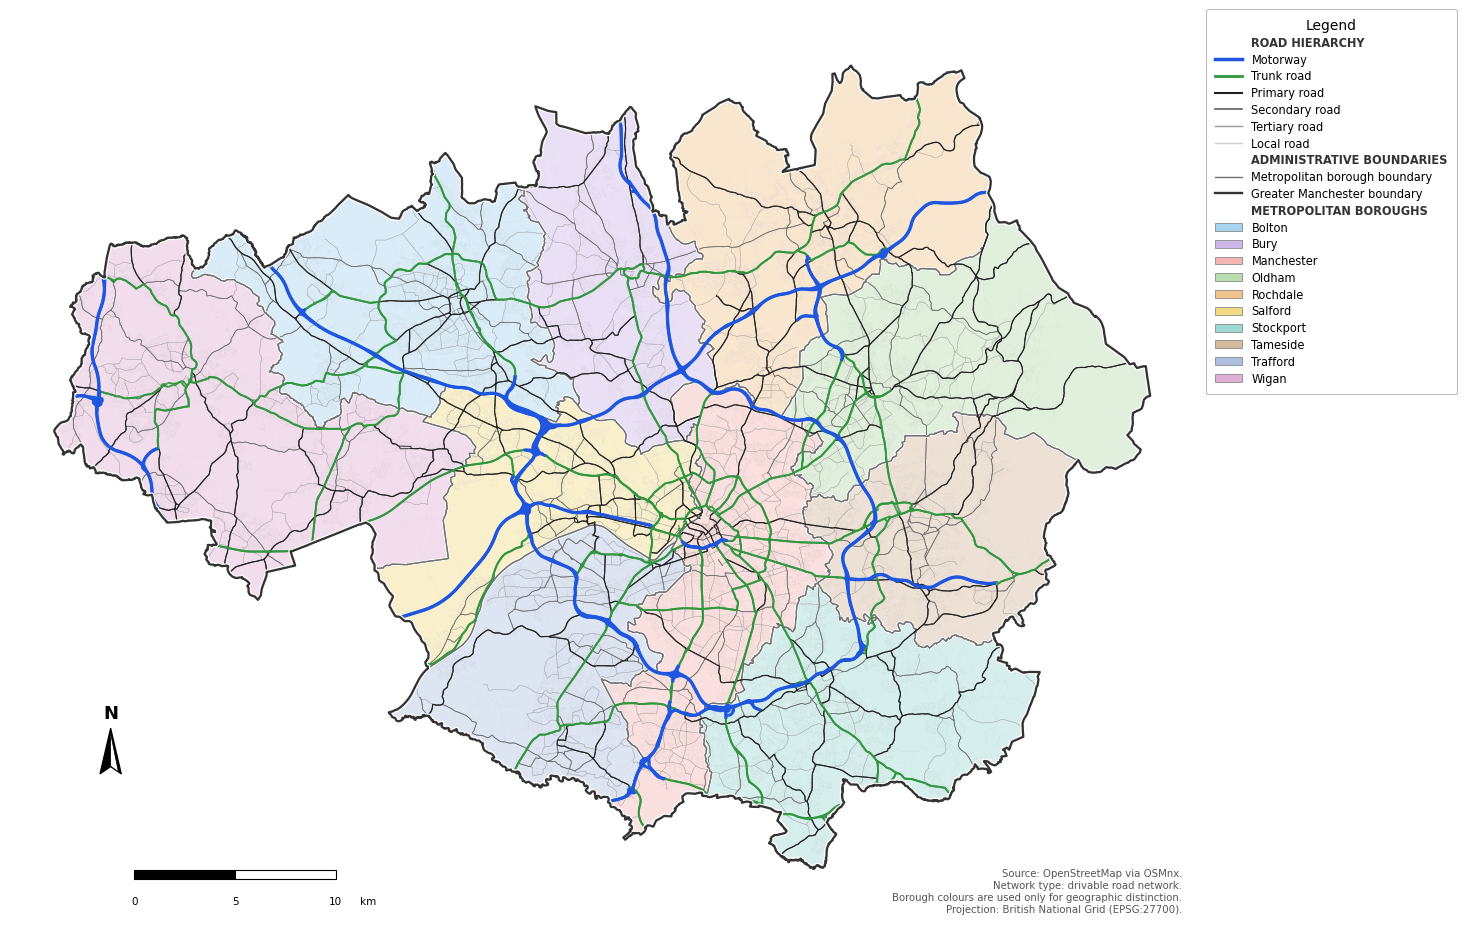

In [ ]:
# prepare road layers for cartographic display
motorway_map = gpd.clip(
    motorway_edges,
    gm_boundary
)

trunk_map = gpd.clip(
    trunk_edges,
    gm_boundary
)

primary_map = gpd.clip(
    primary_edges,
    gm_boundary
)

secondary_map = gpd.clip(
    secondary_edges,
    gm_boundary
)

tertiary_map = gpd.clip(
    tertiary_edges,
    gm_boundary
)

gm_geometry = gm_boundary.geometry.union_all()

local_map = local_edges[
    local_edges.intersects(gm_geometry)
].copy()

# distinct borough colours
borough_palette = {
    "Bolton": "#A7D3EE",      
    "Bury": "#CDB7E9",         
    "Manchester": "#F4B6B2",   
    "Oldham": "#B9DDAF",      
    "Rochdale": "#F2C48D",    
    "Salford": "#F2DC83",      
    "Stockport": "#9FD8D2",  
    "Tameside": "#D5B99F",    
    "Trafford": "#AEBFE0",   
    "Wigan": "#DFAFD4"       
}

boroughs_plot = boroughs_gm.copy()

boroughs_plot["fill_color"] = (
    boroughs_plot["Borough"]
    .map(borough_palette)
    .fillna("#E5E5E5")
)

# create the figure
fig, ax = plt.subplots(
    figsize=(16, 11),
    facecolor="white"
)

ax.set_facecolor("white")

# plot borough colour
for _, row in boroughs_plot.iterrows():

    gpd.GeoSeries(
        [row.geometry],
        crs=boroughs_plot.crs
    ).plot(
        ax=ax,
        facecolor=row["fill_color"],
        edgecolor="none",
        alpha=0.42,
        zorder=1
    )

# local roads
local_map.plot(
    ax=ax,
    color="#CFCFCF",
    linewidth=0.10,
    alpha=0.30,
    zorder=2
)

# tertiary roads
tertiary_map.plot(
    ax=ax,
    color="#969696",
    linewidth=0.30,
    alpha=0.62,
    zorder=3
)

# secondary roads
secondary_map.plot(
    ax=ax,
    color="#5F5F5F",
    linewidth=0.50,
    alpha=0.84,
    zorder=4
)

# white boundary underlay
boroughs_gm.boundary.plot(
    ax=ax,
    color="white",
    linewidth=2.0,
    zorder=5
)

# metropolitan borough boundaries
boroughs_gm.boundary.plot(
    ax=ax,
    color="#727272",
    linewidth=0.90,
    zorder=6
)

# primary roads
primary_map.plot(
    ax=ax,
    color="#202020",
    linewidth=0.78,
    alpha=0.95,
    zorder=7
)

# trunk roads
trunk_map.plot(
    ax=ax,
    color="#2F963E",
    linewidth=1.35,
    alpha=1.0,
    zorder=8
)

# motorways
motorway_map.plot(
    ax=ax,
    color="#1F56E0",
    linewidth=2.15,
    alpha=1.0,
    zorder=9
)

# plot Greater Manchester outer boundary
gm_boundary.boundary.plot(
    ax=ax,
    color="white",
    linewidth=3.4,
    zorder=10
)

gm_boundary.boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=1.65,
    zorder=11
)

# map extent
xmin, ymin, xmax, ymax = gm_boundary.total_bounds

x_margin = (xmax - xmin) * 0.04
y_margin = (ymax - ymin) * 0.07

ax.set_xlim(
    xmin - x_margin,
    xmax + x_margin
)

ax.set_ylim(
    ymin - y_margin,
    ymax + y_margin
)

# legend
legend_handles = [
    Line2D(
        [], [],
        linestyle="none",
        label="ROAD HIERARCHY"
    ),

    Line2D(
        [0], [0],
        color="#1F56E0",
        linewidth=2.5,
        label="Motorway"
    ),

    Line2D(
        [0], [0],
        color="#2F963E",
        linewidth=2.0,
        label="Trunk road"
    ),

    Line2D(
        [0], [0],
        color="#202020",
        linewidth=1.5,
        label="Primary road"
    ),

    Line2D(
        [0], [0],
        color="#5F5F5F",
        linewidth=1.2,
        label="Secondary road"
    ),

    Line2D(
        [0], [0],
        color="#969696",
        linewidth=1.0,
        label="Tertiary road"
    ),

    Line2D(
        [0], [0],
        color="#CFCFCF",
        linewidth=1.0,
        label="Local road"
    ),

    Line2D(
        [], [],
        linestyle="none",
        label="ADMINISTRATIVE BOUNDARIES"
    ),

    Line2D(
        [0], [0],
        color="#727272",
        linewidth=1.0,
        label="Metropolitan borough boundary"
    ),

    Line2D(
        [0], [0],
        color="#333333",
        linewidth=1.7,
        label="Greater Manchester boundary"
    ),

    Line2D(
        [], [],
        linestyle="none",
        label="METROPOLITAN BOROUGHS"
    ),

    Patch(
        facecolor=borough_palette["Bolton"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Bolton"
    ),

    Patch(
        facecolor=borough_palette["Bury"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Bury"
    ),

    Patch(
        facecolor=borough_palette["Manchester"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Manchester"
    ),

    Patch(
        facecolor=borough_palette["Oldham"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Oldham"
    ),

    Patch(
        facecolor=borough_palette["Rochdale"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Rochdale"
    ),

    Patch(
        facecolor=borough_palette["Salford"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Salford"
    ),

    Patch(
        facecolor=borough_palette["Stockport"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Stockport"
    ),

    Patch(
        facecolor=borough_palette["Tameside"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Tameside"
    ),

    Patch(
        facecolor=borough_palette["Trafford"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Trafford"
    ),

    Patch(
        facecolor=borough_palette["Wigan"],
        edgecolor="#777777",
        linewidth=0.5,
        label="Wigan"
    )
]

legend = ax.legend(
    handles=legend_handles,
    title="Legend",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    borderaxespad=0,
    frameon=True,
    framealpha=1.0,
    facecolor="white",
    edgecolor="#BDBDBD",
    fontsize=8.2,
    title_fontsize=10,
    borderpad=0.8,
    labelspacing=0.42,
    handlelength=2.4,
    handletextpad=0.8,
    ncol=1
)

legend.get_frame().set_linewidth(0.8)

# legend headings
section_headings = {
    "ROAD HIERARCHY",
    "ADMINISTRATIVE BOUNDARIES",
    "METROPOLITAN BOROUGHS"
}

for text in legend.get_texts():

    if text.get_text() in section_headings:
        text.set_fontweight("bold")
        text.set_color("#333333")

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="black",
        zorder=30
    )

    outer_arrow = np.array([
        [x, y + size],
        [x - size * 0.18, y],
        [x, y + size * 0.16],
        [x + size * 0.18, y]
    ])

    outer_display = axis.transAxes.transform(
        outer_arrow
    )

    outer_data = axis.transData.inverted().transform(
        outer_display
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array([
        [x, y + size * 0.88],
        [x, y + size * 0.17],
        [x + size * 0.13, y + size * 0.05]
    ])

    inner_display = axis.transAxes.transform(
        inner_arrow
    )

    inner_data = axis.transData.inverted().transform(
        inner_display
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

add_north_arrow(ax)

# scale bar
xmin_map, xmax_map = ax.get_xlim()
ymin_map, ymax_map = ax.get_ylim()

map_width = xmax_map - xmin_map
map_height = ymax_map - ymin_map

scale_x = xmin_map + 0.105 * map_width
scale_y = ymin_map + 0.050 * map_height

segment_length = 5000
bar_height = 480

for segment, colour in enumerate(
    ["black", "white"]
):

    ax.add_patch(
        plt.Rectangle(
            (
                scale_x + segment * segment_length,
                scale_y
            ),
            segment_length,
            bar_height,
            facecolor=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=25
        )
    )

for distance, position in zip(
    [0, 5, 10],
    [
        scale_x,
        scale_x + 5000,
        scale_x + 10000
    ]
):

    ax.text(
        position,
        scale_y - 850,
        str(distance),
        ha="center",
        va="top",
        fontsize=7.5,
        color="black",
        zorder=25
    )

ax.text(
    scale_x + 11200,
    scale_y - 850,
    "km",
    ha="left",
    va="top",
    fontsize=7.5,
    color="black",
    zorder=25
)

# source information
source_note = (
    "Source: OpenStreetMap via OSMnx.\n"
    "Network type: drivable road network.\n"
    "Borough colours are used only for geographic distinction.\n"
    "Projection: British National Grid (EPSG:27700)."
)

ax.text(
    0.99,
    0.012,
    source_note,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.3,
    color="#555555",
    linespacing=1.25
)

ax.axis("off")

# reserve space on the right for the external legend
plt.subplots_adjust(
    left=0.03,
    right=0.77,
    top=0.92,
    bottom=0.04
)

plt.show()

Figure 4 illustrates the processed OSM road network after spatial clipping and road reclassification. Motorways and trunk roads form the primary transport corridors radiating from Manchester city centre, while primary and secondary roads connect the metropolitan boroughs. Tertiary and local roads provide dense coverage within individual neighbourhoods.

### 3.4.3 Employment Data

In [ ]:
import pandas as pdd
import matplotlib.colors as colors
import warnings

from matplotlib.patches import Rectangle, Polygon

# ignore openpyxl warnings
warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    module="openpyxl"
)

employment_file = (
    r"D:\final dissertation"
    r"\nomis_Greater Manchester.xlsx"
)

output_dir = r"D:\final dissertation\outputs"
os.makedirs(output_dir, exist_ok=True)

# read Nomis employment data
employment_raw = pd.read_excel(
    employment_file,
    sheet_name="Data",
    header=None
)

# clean employment data
employment = employment_raw.iloc[9:, :2].copy()

employment.columns = [
    "LSOA",
    "HospitalityEmployees"
]

# keep valid LSOA rows
employment = employment[
    employment["LSOA"]
    .astype(str)
    .str.match(r"^E\d{8}\s*:")
].copy()

# split LSOA code and name
employment[["LSOA21CD", "LSOA21NM"]] = (
    employment["LSOA"]
    .str.split(" : ", n=1, expand=True)
)

# convert employment values to numeric
employment["HospitalityEmployees"] = pd.to_numeric(
    employment["HospitalityEmployees"],
    errors="coerce"
).fillna(0)

employment["HospitalityEmployees"] = (
    employment["HospitalityEmployees"].astype(int)
)

employment = employment[
    [
        "LSOA21CD",
        "LSOA21NM",
        "HospitalityEmployees"
    ]
].reset_index(drop=True)

In [ ]:
# join employment data to LSOA polygons
employment_gm = imd_gm.merge(
    employment[
        ["LSOA21CD", "HospitalityEmployees"]
    ],
    on="LSOA21CD",
    how="left"
)

employment_gm["HospitalityEmployees"] = (
    employment_gm["HospitalityEmployees"]
    .fillna(0)
    .astype(int)
)

# keep LSOAs with at least one employee
positive_employment = employment_gm[
    employment_gm["HospitalityEmployees"] > 0
].copy()

Employment data were obtained from the Business Register and Employment Survey (BRES) through the Nomis official data portal, which is provided by ONS. The 2024 dataset was extracted for the ten Greater Manchester metropolitan boroughs at the 2021 LSOA geography. Employee counts were used to represent payroll-based jobs, and the Accommodation and Food Service Activities sector was selected. After data cleaning and spatial matching, employment data were linked to all 1,702 LSOAs with no missing or duplicated records. 1,205 LSOAs contained accommodation and food service employment and were used as destination points in the accessibility model. BRES reports workplace-based employment and does not represent the residential locations of employees.

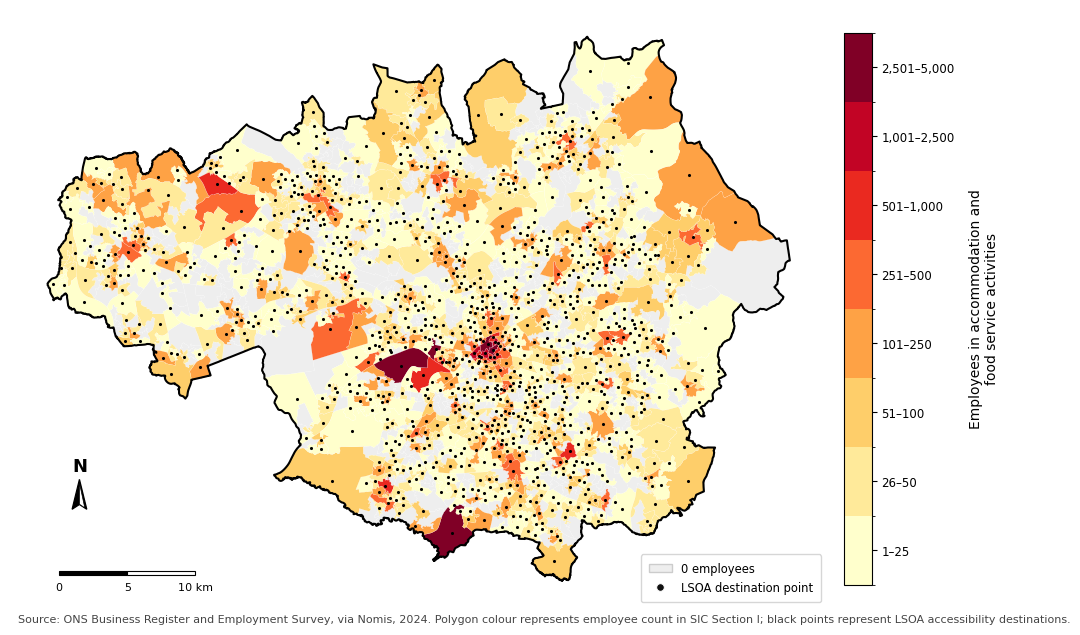

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable

# prepare data
if employment_gm.crs is None:
    raise ValueError("employment_gm has no CRS information.")

if gm_boundary.crs is None:
    raise ValueError("gm_boundary has no CRS information.")

if employment_gm.crs.to_epsg() != 27700:
    employment_gm = employment_gm.to_crs("EPSG:27700")

if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs("EPSG:27700")

employment_gm["HospitalityEmployees"] = pd.to_numeric(
    employment_gm["HospitalityEmployees"],
    errors="coerce"
).fillna(0)

employment_gm["HospitalityEmployees"] = (
    employment_gm["HospitalityEmployees"]
    .clip(lower=0)
    .astype(int)
)

zero_employment = employment_gm[
    employment_gm["HospitalityEmployees"] == 0
].copy()

positive_employment = employment_gm[
    employment_gm["HospitalityEmployees"] > 0
].copy()

# create LSOA destination points
employment_destinations = positive_employment[
    [
        "LSOA21CD",
        "LSOA21NM",
        "HospitalityEmployees",
        "geometry"
    ]
].copy()

employment_destinations["geometry"] = (
    employment_destinations.geometry.representative_point()
)

employment_destinations = employment_destinations.rename(
    columns={
        "LSOA21CD": "id"
    }
)

employment_destinations = (
    employment_destinations
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

# employment classes
class_boundaries = np.array([
    1,
    26,
    51,
    101,
    251,
    501,
    1001,
    2501,
    5001
])

class_labels = [
    "1–25",
    "26–50",
    "51–100",
    "101–250",
    "251–500",
    "501–1,000",
    "1,001–2,500",
    "2,501–5,000"
]

number_of_classes = len(class_labels)

employment_cmap = plt.get_cmap(
    "YlOrRd",
    number_of_classes
)

employment_norm = colors.BoundaryNorm(
    boundaries=class_boundaries,
    ncolors=number_of_classes
)

# create figure
fig, ax = plt.subplots(
    figsize=(11, 11)
)

# plot zero-employment LSOAs
zero_employment.plot(
    ax=ax,
    facecolor="#EEEEEE",
    edgecolor="white",
    linewidth=0.10,
    zorder=1
)

# plot employment polygons
positive_employment.plot(
    column="HospitalityEmployees",
    ax=ax,
    cmap=employment_cmap,
    norm=employment_norm,
    edgecolor="white",
    linewidth=0.10,
    zorder=2
)

# plot destination points
employment_destinations.plot(
    ax=ax,
    markersize=5,
    color="black",
    edgecolor="black",
    linewidth=0,
    alpha=1.0,
    zorder=10
)

# plot Greater Manchester boundary
gm_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    zorder=12
)

# colour bar
colour_mapper = ScalarMappable(
    cmap=employment_cmap,
    norm=employment_norm
)

colour_mapper.set_array([])

class_midpoints = (
    class_boundaries[:-1]
    + class_boundaries[1:]
) / 2

cbar = fig.colorbar(
    colour_mapper,
    ax=ax,
    boundaries=class_boundaries,
    ticks=class_midpoints,
    fraction=0.032,
    pad=0.02,
    shrink=0.76,
    spacing="uniform"
)

cbar.set_ticklabels(
    class_labels
)

cbar.set_label(
    "Employees in accommodation and\n"
    "food service activities",
    fontsize=10,
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=8.5
)

# legend
zero_handle = Patch(
    facecolor="#EEEEEE",
    edgecolor="#CCCCCC",
    label="0 employees"
)

destination_handle = Line2D(
    [0],
    [0],
    marker="o",
    linestyle="none",
    markerfacecolor="#111111",
    markeredgecolor="white",
    markeredgewidth=0.7,
    markersize=5.5,
    label="LSOA destination point"
)

ax.legend(
    handles=[
        zero_handle,
        destination_handle
    ],
    loc="lower right",
    frameon=True,
    fontsize=8.3,
    borderpad=0.7
)

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="black",
        zorder=30
    )

    outer_arrow = np.array([
        [x, y + size],
        [x - size * 0.18, y],
        [x, y + size * 0.16],
        [x + size * 0.18, y]
    ])

    outer_display = axis.transAxes.transform(
        outer_arrow
    )

    outer_data = axis.transData.inverted().transform(
        outer_display
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array([
        [x, y + size * 0.88],
        [x, y + size * 0.17],
        [x + size * 0.13, y + size * 0.05]
    ])

    inner_display = axis.transAxes.transform(
        inner_arrow
    )

    inner_data = axis.transData.inverted().transform(
        inner_display
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

add_north_arrow(ax)

# scale bar
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

map_width = x_max - x_min
map_height = y_max - y_min

x_start = x_min + map_width * 0.06
y_start = y_min + map_height * 0.055

segment_length = 5000
bar_height = map_height * 0.007

# 0–5 km
ax.add_patch(
    Rectangle(
        (x_start, y_start),
        segment_length,
        bar_height,
        facecolor="black",
        edgecolor="black",
        linewidth=0.8,
        zorder=20
    )
)

# 5–10 km
ax.add_patch(
    Rectangle(
        (
            x_start + segment_length,
            y_start
        ),
        segment_length,
        bar_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=20
    )
)

label_y = y_start - map_height * 0.012

ax.text(
    x_start,
    label_y,
    "0",
    ha="center",
    va="top",
    fontsize=8
)

ax.text(
    x_start + segment_length,
    label_y,
    "5",
    ha="center",
    va="top",
    fontsize=8
)

ax.text(
    x_start + segment_length * 2,
    label_y,
    "10 km",
    ha="center",
    va="top",
    fontsize=8
)

ax.text(
    0.01,
    -0.025,
    "Source: ONS Business Register and Employment Survey, "
    "via Nomis, 2024. Polygon colour represents employee count "
    "in SIC Section I; black points represent LSOA accessibility destinations.",
    transform=ax.transAxes,
    fontsize=8.0,
    color="#444444",
    ha="left"
)

ax.set_axis_off()

# save and display map
employment_map_path = os.path.join(
    output_dir,
    "sic_section_i_employees_and_destination_points_2024.png"
)

plt.tight_layout()

plt.savefig(
    employment_map_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# save destination points
employment_destinations_wgs84 = (
    employment_destinations.to_crs("EPSG:4326")
)

employment_destinations_wgs84["longitude"] = (
    employment_destinations_wgs84.geometry.x
)

employment_destinations_wgs84["latitude"] = (
    employment_destinations_wgs84.geometry.y
)

employment_destinations_wgs84.to_file(
    os.path.join(
        output_dir,
        "sic_section_i_destination_points_2024.gpkg"
    ),
    layer="destinations",
    driver="GPKG"
)

employment_destinations_wgs84[
    [
        "id",
        "LSOA21NM",
        "HospitalityEmployees",
        "longitude",
        "latitude"
    ]
].to_csv(
    os.path.join(
        output_dir,
        "sic_section_i_destination_points_2024.csv"
    ),
    index=False
)

Figure 5 presents the employment data used in the accessibility analysis. Polygon colours show the number of accommodation and food service employees in each LSOA, while the overlaid points represent the employment locations used in the accessibility model. Employment is concentrated in Manchester city centre and several major town centres, with lower levels across many suburban and peripheral areas.

### 3.4.4 IMD Deprivation Data

In [ ]:
# file paths
imd_spatial_file = (
    r"D:\final dissertation"
    r"\LSOA_IMD2025_OSGB1936_-7140860978498206463.zip"
)

imd_score_file = (
    r"D:\final dissertation"
    r"\File_5_IoD2025_Scores_for_the_Indices_of_Deprivation.xlsx"
)

output_dir = (
    r"D:\final dissertation\outputs"
)

os.makedirs(
    output_dir,
    exist_ok=True
)

# read spatial IoD data
imd_spatial = gpd.read_file(
    imd_spatial_file
)

if imd_spatial.crs is None:
    raise ValueError(
        "The spatial IoD file has no CRS defined."
    )

if imd_spatial.crs.to_epsg() != 27700:
    imd_spatial = imd_spatial.to_crs(
        "EPSG:27700"
    )

# read IoD 2025 score data
imd_scores = pd.read_excel(
    imd_score_file,
    sheet_name="IoD2025 Scores"
)

# clean column names
imd_scores.columns = (
    imd_scores.columns
    .astype(str)
    .str.strip()
)

# rename all IoD score variables
imd_scores = imd_scores.rename(
    columns={
        "LSOA code (2021)":
            "LSOA21CD",

        "LSOA name (2021)":
            "LSOA21NM_score",

        "Index of Multiple Deprivation (IMD) Score":
            "IMDScore",

        "Income Score (rate)":
            "IncomeScoreRate",

        "Employment Score (rate)":
            "EmploymentScoreRate",

        "Education, Skills and Training Score":
            "EducationSkillsTrainingScore",

        "Health Deprivation and Disability Score":
            "HealthDeprivationDisabilityScore",

        "Crime Score":
            "CrimeScore",

        "Barriers to Housing and Services Score":
            "BarriersHousingServicesScore",

        "Living Environment Score":
            "LivingEnvironmentScore",

        "Income Deprivation Affecting Children Index (IDACI) Score (rate)":
            "IDACIScoreRate",

        "Income Deprivation Affecting Older People (IDAOPI) Score (rate)":
            "IDAOPIScoreRate",

        "Children and Young People Sub-domain Score":
            "ChildrenYoungPeopleScore",

        "Adult Skills Sub-domain Score":
            "AdultSkillsScore",

        "Geographical Barriers Sub-domain Score":
            "GeographicalBarriersScore",

        "Wider Barriers Sub-domain Score":
            "WiderBarriersScore",

        "Indoors Sub-domain Score":
            "IndoorsScore",

        "Outdoors Sub-domain Score":
            "OutdoorsScore"
    }
)

# standardise LSOA codes
imd_spatial[
    "LSOA21CD"
] = (
    imd_spatial[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

imd_scores[
    "LSOA21CD"
] = (
    imd_scores[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

# define all 16 IoD score measures
iod_score_columns = [
    "IMDScore",
    "IncomeScoreRate",
    "EmploymentScoreRate",
    "EducationSkillsTrainingScore",
    "HealthDeprivationDisabilityScore",
    "CrimeScore",
    "BarriersHousingServicesScore",
    "LivingEnvironmentScore",
    "IDACIScoreRate",
    "IDAOPIScoreRate",
    "ChildrenYoungPeopleScore",
    "AdultSkillsScore",
    "GeographicalBarriersScore",
    "WiderBarriersScore",
    "IndoorsScore",
    "OutdoorsScore"
]

# retain required score variables
imd_scores_selected = (
    imd_scores[
        [
            "LSOA21CD",
            "LSOA21NM_score"
        ]
        + iod_score_columns
    ]
    .copy()
)

# convert score variables to numeric
imd_scores_selected[
    iod_score_columns
] = (
    imd_scores_selected[
        iod_score_columns
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

# check duplicate LSOA codes
if (
    imd_scores_selected[
        "LSOA21CD"
    ]
    .duplicated()
    .any()
):
    raise ValueError(
        "Duplicate LSOA codes found in the IoD score file."
    )

if (
    imd_spatial[
        "LSOA21CD"
    ]
    .duplicated()
    .any()
):
    raise ValueError(
        "Duplicate LSOA codes found in the spatial IoD file."
    )

# join all IoD scores to spatial data
imd = (
    imd_spatial
    .merge(
        imd_scores_selected,
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
)

imd = gpd.GeoDataFrame(
    imd,
    geometry="geometry",
    crs=imd_spatial.crs
)

In [ ]:
# ensure Greater Manchester boundary uses British National Grid
if gm_boundary.crs is None:
    raise ValueError(
        "Greater Manchester boundary has no CRS defined."
    )

if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs(
        "EPSG:27700"
    )

# combine Greater Manchester boundary features
gm_boundary_geometry = (
    gm_boundary.geometry.union_all()
)

# select Greater Manchester LSOAs
imd_gm = (
    imd[
        imd.geometry
        .representative_point()
        .within(
            gm_boundary_geometry
        )
    ]
    .copy()
    .reset_index(drop=True)
)

# remove duplicated LSOA name from the score file
if "LSOA21NM_score" in imd_gm.columns:

    imd_gm = imd_gm.drop(
        columns=[
            "LSOA21NM_score"
        ]
    )

# keep spatial identifiers and all IoD score measures
imd_gm = (
    imd_gm[
        [
            "LSOA21CD",
            "LSOA21NM",
            "IMDRank",
            "IMDDecil",
            "IMDScore",
            "IncomeScoreRate",
            "EmploymentScoreRate",
            "EducationSkillsTrainingScore",
            "HealthDeprivationDisabilityScore",
            "CrimeScore",
            "BarriersHousingServicesScore",
            "LivingEnvironmentScore",
            "IDACIScoreRate",
            "IDAOPIScoreRate",
            "ChildrenYoungPeopleScore",
            "AdultSkillsScore",
            "GeographicalBarriersScore",
            "WiderBarriersScore",
            "IndoorsScore",
            "OutdoorsScore",
            "geometry"
        ]
    ]
    .copy()
)

# ensure British National Grid
imd_gm = gpd.GeoDataFrame(
    imd_gm,
    geometry="geometry",
    crs=imd.crs
)

if imd_gm.crs.to_epsg() != 27700:

    imd_gm = imd_gm.to_crs(
        "EPSG:27700"
    )

Income deprivation data were obtained from the IMD 2025 published by the Ministry of Housing, Communities and Local Government. The Income Deprivation domain was selected because it provides a measure of neighbourhood economic disadvantage and is closely aligned with the equity. The data representing the estimated proportion of residents experiencing income deprivation within each LSOA. The dataset was projected to the British National Grid and clipped to the Greater Manchester boundary. The data represents neighbourhood-level conditions and does not capture variation between individuals within an LSOA.

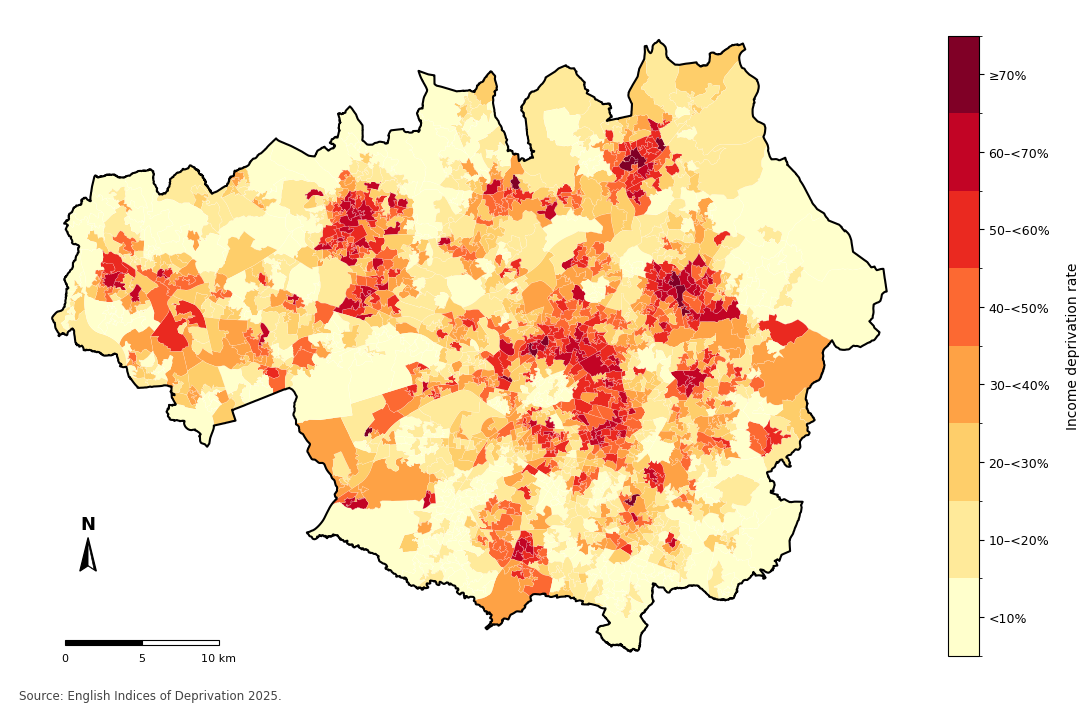

In [ ]:
# ensure British National Grid projection
if imd_gm.crs.to_epsg() != 27700:
    imd_gm = imd_gm.to_crs(
        "EPSG:27700"
    )

if gm_boundary.crs.to_epsg() != 27700:
    gm_boundary = gm_boundary.to_crs(
        "EPSG:27700"
    )

# convert income deprivation rate to percentage
imd_gm[
    "IncomeDeprivationPercent"
] = (
    imd_gm[
        "IncomeScoreRate"
    ] * 100
)

# map classes
income_boundaries = [
    0,
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    85
]

income_labels = [
    "<10%",
    "10–<20%",
    "20–<30%",
    "30–<40%",
    "40–<50%",
    "50–<60%",
    "60–<70%",
    "≥70%"
]

# darker colour indicates greater income deprivation
cmap = plt.get_cmap(
    "YlOrRd",
    len(income_labels)
)

norm = colors.BoundaryNorm(
    boundaries=income_boundaries,
    ncolors=cmap.N
)

# plot income deprivation map
fig, ax = plt.subplots(
    figsize=(11, 11)
)

imd_gm.plot(
    column="IncomeDeprivationPercent",
    ax=ax,
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.10,
    zorder=1
)

gm_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    zorder=3
)

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="black",
        zorder=30
    )

    outer_arrow = np.array(
        [
            [x, y + size],
            [x - size * 0.18, y],
            [x, y + size * 0.16],
            [x + size * 0.18, y]
        ]
    )

    outer_display = (
        axis.transAxes.transform(
            outer_arrow
        )
    )

    outer_data = (
        axis.transData
        .inverted()
        .transform(
            outer_display
        )
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array(
        [
            [x, y + size * 0.88],
            [x, y + size * 0.17],
            [x + size * 0.13, y + size * 0.05]
        ]
    )

    inner_display = (
        axis.transAxes.transform(
            inner_arrow
        )
    )

    inner_data = (
        axis.transData
        .inverted()
        .transform(
            inner_display
        )
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

add_north_arrow(
    ax
)

# scale bar
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

map_width = (
    x_max - x_min
)

map_height = (
    y_max - y_min
)

x_start = (
    x_min
    + map_width * 0.06
)

y_start = (
    y_min
    + map_height * 0.055
)

segment_length = 5000

bar_height = (
    map_height * 0.007
)

# 0–5 km
ax.add_patch(
    Rectangle(
        (
            x_start,
            y_start
        ),
        segment_length,
        bar_height,
        facecolor="black",
        edgecolor="black",
        linewidth=0.8,
        zorder=10
    )
)

# 5–10 km
ax.add_patch(
    Rectangle(
        (
            x_start + segment_length,
            y_start
        ),
        segment_length,
        bar_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=10
    )
)

label_y = (
    y_start
    - map_height * 0.012
)

ax.text(
    x_start,
    label_y,
    "0",
    ha="center",
    va="top",
    fontsize=8
)

ax.text(
    x_start + segment_length,
    label_y,
    "5",
    ha="center",
    va="top",
    fontsize=8
)

ax.text(
    x_start + segment_length * 2,
    label_y,
    "10 km",
    ha="center",
    va="top",
    fontsize=8
)

# colour bar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

tick_positions = [
    5,
    15,
    25,
    35,
    45,
    55,
    65,
    77.5
]

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=income_boundaries,
    ticks=tick_positions,
    fraction=0.032,
    pad=0.02,
    shrink=0.76
)

cbar.ax.set_yticklabels(
    income_labels
)

cbar.set_label(
    "Income deprivation rate",
    fontsize=10,
    labelpad=12
)

cbar.ax.tick_params(
    labelsize=9
)

# map formatting
ax.set_axis_off()

ax.text(
    0.01,
    -0.025,
    "Source: English Indices of Deprivation 2025.",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#444444",
    ha="left"
)

# save map
income_map_path = os.path.join(
    output_dir,
    "income_deprivation_greater_manchester_2025.png"
)

plt.tight_layout()

plt.savefig(
    income_map_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# create LSOA origin points for later modelling
origins_27700 = (
    imd_gm.copy()
)

origins_27700[
    "geometry"
] = (
    origins_27700
    .geometry
    .representative_point()
)

# save processed datasets
imd_gm.to_file(
    os.path.join(
        output_dir,
        "greater_manchester_lsoa_income_deprivation_2025.gpkg"
    ),
    layer="income_deprivation_2025",
    driver="GPKG"
)

origins_27700.to_file(
    os.path.join(
        output_dir,
        "greater_manchester_lsoa_origins.gpkg"
    ),
    layer="origins",
    driver="GPKG"
)

origins_27700.drop(
    columns="geometry"
).to_csv(
    os.path.join(
        output_dir,
        "greater_manchester_lsoa_origins.csv"
    ),
    index=False
)

Figure 6 illustrates the spatial distribution of the Income Score Rate across Greater Manchester LSOAs. Higher levels of income deprivation are concentrated in several inner urban areas and town centres, while lower deprivation rates are more common in suburban and peripheral neighbourhoods.

### 3.4.5 Population Density

Population density data were obtained from the ONS 2021 Census TS006 Population Density dataset. After extracting the Greater Manchester records, population density values were joined to the corresponding LSOAs using the unique LSOA code. The processed dataset was projected to the British National Grid and classified into five categories for mapping.

In [ ]:
# read and prepare population density data
population_density_file = (
    r"D:\final dissertation"
    r"\nomis_population denstiy.xlsx"
)

population_density = (
    pd.read_excel(
        population_density_file,
        sheet_name="Data",
        header=None
    )
    .iloc[8:, :]
    .copy()
)

population_density.columns = [
    "LSOA",
    "PopulationDensity"
]

# keep valid LSOA records
population_density = (
    population_density[
        population_density["LSOA"]
        .astype(str)
        .str.match(r"^E\d{8}\s*:")
    ]
    .copy()
)

population_density[
    ["LSOA21CD", "LSOA21NM"]
] = (
    population_density["LSOA"]
    .str.split(
        " : ",
        n=1,
        expand=True
    )
)

population_density["PopulationDensity"] = (
    pd.to_numeric(
        population_density["PopulationDensity"],
        errors="coerce"
    )
)

population_density = (
    population_density[
        [
            "LSOA21CD",
            "LSOA21NM",
            "PopulationDensity"
        ]
    ]
    .reset_index(drop=True)
)

### 3.4.6 Household Car Availability

Household car availability data were obtained from the ONS 2021 Census TS045 Car or Van Availability dataset. The percentage of households with no car or van was selected as the indicator of car availability. After extracting the Greater Manchester records, the data were joined to the corresponding LSOAs using the unique LSOA code, projected to the British National Grid and classified into five categories for mapping. 

In [ ]:
# read and prepare household car availability data
no_car_file = (
    r"D:\final dissertation"
    r"\TS045_no_car_full_data.xlsx"
)

no_car = (
    pd.read_excel(
        no_car_file,
        sheet_name="Data",
        header=None
    )
    .iloc[9:, :]
    .copy()
)

# column structure in the original TS045 dataset
no_car.columns = [
    "LSOA",
    "TotalHouseholds",
    "TotalHouseholdsPercent",
    "NoCarHouseholds",
    "NoCarHouseholdsPercent",
    "OneCarHouseholds",
    "OneCarHouseholdsPercent",
    "TwoCarHouseholds",
    "TwoCarHouseholdsPercent",
    "ThreePlusCarHouseholds",
    "ThreePlusCarHouseholdsPercent"
]

# keep valid LSOA records
no_car = (
    no_car[
        no_car["LSOA"]
        .astype(str)
        .str.match(r"^E\d{8}\s*:")
    ]
    .copy()
)

# split LSOA code and name
no_car[
    [
        "LSOA21CD",
        "LSOA21NM"
    ]
] = (
    no_car["LSOA"]
    .str.split(
        " : ",
        n=1,
        expand=True
    )
)

# convert all household variables to numeric
numeric_columns = [
    "TotalHouseholds",
    "TotalHouseholdsPercent",
    "NoCarHouseholds",
    "NoCarHouseholdsPercent",
    "OneCarHouseholds",
    "OneCarHouseholdsPercent",
    "TwoCarHouseholds",
    "TwoCarHouseholdsPercent",
    "ThreePlusCarHouseholds",
    "ThreePlusCarHouseholdsPercent"
]

no_car[
    numeric_columns
] = (
    no_car[
        numeric_columns
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

# retain all five groups from the original dataset
no_car = (
    no_car[
        [
            "LSOA21CD",
            "LSOA21NM",

            "TotalHouseholds",
            "TotalHouseholdsPercent",

            "NoCarHouseholds",
            "NoCarHouseholdsPercent",

            "OneCarHouseholds",
            "OneCarHouseholdsPercent",

            "TwoCarHouseholds",
            "TwoCarHouseholdsPercent",

            "ThreePlusCarHouseholds",
            "ThreePlusCarHouseholdsPercent"
        ]
    ]
    .reset_index(drop=True)
)

### 3.4.7 Descriptive Statistics of Study Data

In [ ]:
# combine datasets
data_overview = (
    imd_gm[
        [
            "LSOA21CD",
            "IMDScore",
            "IncomeScoreRate",
            "EmploymentScoreRate",
            "EducationSkillsTrainingScore",
            "HealthDeprivationDisabilityScore",
            "CrimeScore",
            "BarriersHousingServicesScore",
            "LivingEnvironmentScore",
            "IDACIScoreRate",
            "IDAOPIScoreRate",
            "ChildrenYoungPeopleScore",
            "AdultSkillsScore",
            "GeographicalBarriersScore",
            "WiderBarriersScore",
            "IndoorsScore",
            "OutdoorsScore"
        ]
    ]
    .copy()

    .merge(
        population_density[
            [
                "LSOA21CD",
                "PopulationDensity"
            ]
        ],
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )

    .merge(
        no_car[
            [
                "LSOA21CD",
                "TotalHouseholds",
                "NoCarHouseholds",
                "NoCarHouseholdsPercent",
                "OneCarHouseholds",
                "OneCarHouseholdsPercent",
                "TwoCarHouseholds",
                "TwoCarHouseholdsPercent",
                "ThreePlusCarHouseholds",
                "ThreePlusCarHouseholdsPercent"
            ]
        ],
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
)

# variables shown in the table
variables_to_show = [

    (
        "Deprivation characteristics",
        "Index of Multiple Deprivation score",
        "IMDScore"
    ),

    (
        "Deprivation characteristics",
        "Income deprivation score (rate)",
        "IncomeScoreRate"
    ),

    (
        "Deprivation characteristics",
        "Employment deprivation score (rate)",
        "EmploymentScoreRate"
    ),

    (
        "Deprivation characteristics",
        "Education, Skills and Training deprivation score",
        "EducationSkillsTrainingScore"
    ),

    (
        "Deprivation characteristics",
        "Health Deprivation and Disability score",
        "HealthDeprivationDisabilityScore"
    ),

    (
        "Deprivation characteristics",
        "Crime score",
        "CrimeScore"
    ),

    (
        "Deprivation characteristics",
        "Barriers to Housing and Services score",
        "BarriersHousingServicesScore"
    ),

    (
        "Deprivation characteristics",
        "Living Environment score",
        "LivingEnvironmentScore"
    ),

    (
        "Deprivation characteristics",
        "Income Deprivation Affecting Children Index score (rate)",
        "IDACIScoreRate"
    ),

    (
        "Deprivation characteristics",
        "Income Deprivation Affecting Older People Index score (rate)",
        "IDAOPIScoreRate"
    ),

    (
        "Deprivation characteristics",
        "Children and Young People sub-domain score",
        "ChildrenYoungPeopleScore"
    ),

    (
        "Deprivation characteristics",
        "Adult Skills sub-domain score",
        "AdultSkillsScore"
    ),

    (
        "Deprivation characteristics",
        "Geographical Barriers sub-domain score",
        "GeographicalBarriersScore"
    ),

    (
        "Deprivation characteristics",
        "Wider Barriers sub-domain score",
        "WiderBarriersScore"
    ),

    (
        "Deprivation characteristics",
        "Indoors sub-domain score",
        "IndoorsScore"
    ),

    (
        "Deprivation characteristics",
        "Outdoors sub-domain score",
        "OutdoorsScore"
    ),

    (
        "Spatial characteristics",
        "Population density (persons/km²)",
        "PopulationDensity"
    ),

    (
        "Household car availability",
        "Total households (number)",
        "TotalHouseholds"
    ),

    (
        "Household car availability",
        "No cars or vans in household (number)",
        "NoCarHouseholds"
    ),

    (
        "Household car availability",
        "No cars or vans in household (%)",
        "NoCarHouseholdsPercent"
    ),

    (
        "Household car availability",
        "1 car or van in household (number)",
        "OneCarHouseholds"
    ),

    (
        "Household car availability",
        "1 car or van in household (%)",
        "OneCarHouseholdsPercent"
    ),

    (
        "Household car availability",
        "2 cars or vans in household (number)",
        "TwoCarHouseholds"
    ),

    (
        "Household car availability",
        "2 cars or vans in household (%)",
        "TwoCarHouseholdsPercent"
    ),

    (
        "Household car availability",
        "3 or more cars or vans in household (number)",
        "ThreePlusCarHouseholds"
    ),

    (
        "Household car availability",
        "3 or more cars or vans in household (%)",
        "ThreePlusCarHouseholdsPercent"
    )
]

# calculate descriptive statistics
summary_rows = []

for group, label, column in variables_to_show:

    values = pd.to_numeric(
        data_overview[column],
        errors="coerce"
    )

    summary_rows.append(
        {
            "Group": group,
            "Variable": label,
            "Mean": values.mean(),
            "SD": values.std(),
            "Minimum": values.min(),
            "Maximum": values.max()
        }
    )

summary_table = pd.DataFrame(
    summary_rows
)

# display table
table_html = """
<div class="table-container">

<table class="data-table">

<colgroup>
    <col style="width: 52%;">
    <col style="width: 12%;">
    <col style="width: 12%;">
    <col style="width: 12%;">
    <col style="width: 12%;">
</colgroup>

<thead>
<tr>
    <th>Variable</th>
    <th>Mean</th>
    <th>SD</th>
    <th>Minimum</th>
    <th>Maximum</th>
</tr>
</thead>

<tbody>
"""

current_group = None

for _, row in summary_table.iterrows():

    if row["Group"] != current_group:

        current_group = row["Group"]

        table_html += f"""
        <tr class="group-row">
            <td colspan="5">
                {current_group}
            </td>
        </tr>
        """

    table_html += f"""
    <tr>
        <td class="variable">
            {row["Variable"]}
        </td>

        <td>{row["Mean"]:,.2f}</td>
        <td>{row["SD"]:,.2f}</td>
        <td>{row["Minimum"]:,.2f}</td>
        <td>{row["Maximum"]:,.2f}</td>
    </tr>
    """

table_html += """
</tbody>

</table>

</div>
"""

styled_table = f"""
<style>

.table-container {{
    width: 100%;
    max-width: 100%;
    overflow: visible;
    margin-bottom: 12px;
}}

.data-table {{
    width: 100%;
    max-width: 100%;

    border-collapse: collapse;
    table-layout: fixed;

    font-family: "Times New Roman";
    font-size: 12.5px;

    border-top: 1.5px solid black;
    border-bottom: 1.5px solid black;
}}

.data-table th {{
    font-weight: normal;
    text-align: center;

    padding: 4px 6px;

    border-bottom: 1px solid black;
}}

.data-table th:first-child {{
    text-align: left;
}}

.data-table td {{
    border: none;
    padding: 3.5px 6px;
    vertical-align: top;
}}

.data-table td:not(:first-child) {{
    text-align: right;
    white-space: nowrap;
}}

.data-table .variable {{
    text-align: left;
    padding-left: 20px;
    white-space: normal;
}}

.data-table .group-row td {{
    font-weight: bold;
    text-align: left;

    padding-left: 6px;
    padding-top: 8px;
    padding-bottom: 3px;
}}

</style>

{table_html}
"""

display(
    HTML(
        styled_table
    )
)

Table 1 summarises the socioeconomic, spatial and household characteristics in Greater Manchester. The deprivation data include the 16 score measures provided in the IMD 2025. Population density varies across the study area, reflecting differences between the urban core and more peripheral areas. Household car availability also varies across LSOAs. The mean proportion of households with no car or van is 26.16%, while one-car households are the largest category.

In [ ]:
# selected variables for regression analysis
regression_variables = pd.DataFrame(
    [
        {
            "Variable": "Income deprivation",
            "Role": "Independent variable",
            "Source": "IMD 2025",
            "Rationale": (
                "Measures economic disadvantage and allows accessibility "
                "change to be compared between more and less deprived areas."
            )
        },
        {
            "Variable": "Accessibility change",
            "Role": "Dependent variable",
            "Source": "Derived from R5 accessibility results",
            "Rationale": (
                "Measures the effect of the pilot on access to "
                "hospitality employment."
            )
        },
        {
            "Variable": "Baseline accessibility",
            "Role": "Control variable",
            "Source": "Derived from R5 without-pilot results",
            "Rationale": (
                "Accounts for differences in accessibility before the pilot."
            )
        },
        {
            "Variable": "Population density",
            "Role": "Control variable",
            "Source": "ONS Census 2021",
            "Rationale": (
                "Accounts for differences in urban form and "
                "population concentration."
            )
        },
        {
            "Variable": "Households with no car or van (%)",
            "Role": "Control variable",
            "Source": "ONS Census 2021",
            "Rationale": (
                "Provides a comparable measure of potential "
                "public transport dependence."
            )
        },
        {
            "Variable": "Education, Skills and Training deprivation",
            "Role": "Control variable",
            "Source": "IMD 2025",
            "Rationale": (
                "Captures a socioeconomic dimension that may "
                "influence employment accessibility."
            )
        }
    ]
)

# convert table to HTML
table_html = regression_variables.to_html(
    index=False,
    escape=False,
    border=0,
    classes="regression-table"
)

# display formatted table
display(
    HTML(
        f"""
        <style>
        .table-container {{
            width: 100%;
            overflow-x: auto;
            font-family: "Times New Roman", Times, serif;
        }}

        table.regression-table {{
            width: 100%;
            border-collapse: collapse;
            font-size: 12.5px;
            line-height: 1.35;
            border-top: 1.5px solid black;
            border-bottom: 1.5px solid black;
        }}

        table.regression-table thead th {{
            text-align: center !important;
            vertical-align: middle !important;
            font-weight: bold;
            padding: 6px 8px;
            border-bottom: 1px solid black;
        }}

        table.regression-table tbody td {{
            text-align: left;
            vertical-align: top;
            padding: 6px 8px;
            border: none;
        }}

        table.regression-table th:nth-child(1),
        table.regression-table td:nth-child(1) {{
            width: 23%;
        }}

        table.regression-table th:nth-child(2),
        table.regression-table td:nth-child(2) {{
            width: 18%;
        }}

        table.regression-table th:nth-child(3),
        table.regression-table td:nth-child(3) {{
            width: 20%;
        }}

        table.regression-table th:nth-child(4),
        table.regression-table td:nth-child(4) {{
            width: 39%;
        }}
        </style>

        <div class="table-container">
            {table_html}
        </div>
        """
    )
)

Variable,Role,Source,Rationale
Income deprivation,Independent variable,IMD 2025,Measures economic disadvantage and allows accessibility change to be compared between more and less deprived areas.
Accessibility change,Dependent variable,Derived from R5 accessibility results,Measures the effect of the pilot on access to hospitality employment.
Baseline accessibility,Control variable,Derived from R5 without-pilot results,Accounts for differences in accessibility before the pilot.
Population density,Control variable,ONS Census 2021,Accounts for differences in urban form and population concentration.
Households with no car or van (%),Control variable,ONS Census 2021,Provides a comparable measure of potential public transport dependence.
"Education, Skills and Training deprivation",Control variable,IMD 2025,Captures a socioeconomic dimension that may influence employment accessibility.


This study examines whether changes in public transport accessibility differ across areas with different levels of economic disadvantage. Table 2 summarises the variables selected for the regression analysis. Income deprivation was selected as the independent variable, which allows accessibility change to be compared between different deprived areas. Accessibility change was selected as the dependent variable because it measures the effect of the pilot on access to hospitality employment. It will be calculated as the difference between the with-pilot and without-pilot R5 accessibility results. Baseline accessibility as a control variable will be derived from the without-pilot R5 results, as initial accessibility may influence subsequent change. Population density was selected as a control variable to account for differences in urban form and population concentration. The percentage of households with no car or van was selected as a control variable because car availability by the total number of households and provides a comparable measure of potential public transport dependence. Education, Skills and Training deprivation was included as an additional control variable because it captures a socioeconomic dimension that may influence employment accessibility independently of income deprivation. Models with and without this variable will be compared.

# 4 Result

This chapter presents the results of the accessibility, equity and regression analyses. It first examines the spatial distribution of overnight public transport accessibility to hospitality employment under the without-pilot and with-pilot scenarios. The two scenarios are then compared to identify the magnitude and spatial distribution of accessibility change associated with the overnight bus pilot. The analysis examines whether these changes differ across neighbourhoods with different levels of income deprivation. Finally, regression analysis is used to assess whether income deprivation remains associated with the occurrence and magnitude of accessibility change after accounting for relevant neighbourhood characteristics, followed by spatial diagnostics of the regression residuals.

## 4.1 Night-time Accessibility and Pilot Impact

The first stage compares night-time accessibility under the two public transport network scenarios. Accessibility represents the number of hospitality employment opportunities that can be reached from each LSOA within 45 minutes by public transport during the selected overnight departure period. The without-pilot scenario excludes the overnight services, whereas the with-pilot scenario retains these services. All other modelling conditions are held constant, allowing differences between the two scenarios to be attributed to the presence of the pilot services.

### 4.1.1 Accessibility without the Pilot

In [ ]:
from datetime import datetime, timedelta

# model settings
project_dir = Path(
    r"D:\final dissertation"
)

# file path
osm_pbf_path = (
    project_dir
    / "r5_inputs"
    / "greater-manchester-latest.osm.pbf"
)

with_pilot_gtfs_path = (
    project_dir
    / "itm_north_west_gtfs_20251220.zip"
)

# analysis date and departure period
analysis_date = datetime(
    2025,
    12,
    20
)

departure_datetime = datetime(
    2025,
    12,
    20,
    2,
    0
)

departure_time_window = timedelta(
    hours=1
)

# accessibility threshold
accessibility_threshold_minutes = 45

maximum_travel_time = timedelta(
    minutes=accessibility_threshold_minutes
)

# pilot routes
pilot_route_numbers = [
    "V1",
    "36",
    "17",
    "135"
]

# R5 output directories
final_run_dir = (
    project_dir
    / "r5_runs"
    / "final_20251220"
)

without_pilot_dir = (
    final_run_dir
    / "without_pilot"
)

with_pilot_dir = (
    final_run_dir
    / "with_pilot"
)

without_pilot_dir.mkdir(
    parents=True,
    exist_ok=True
)

with_pilot_dir.mkdir(
    parents=True,
    exist_ok=True
)

# without-pilot GTFS
without_pilot_gtfs_path = (
    without_pilot_dir
    / "gtfs_without_pilot_20251220.zip"
)

# routing inputs for the external R5 process
without_pilot_origins_path = (
    without_pilot_dir
    / "origins.gpkg"
)

without_pilot_destinations_path = (
    without_pilot_dir
    / "destinations.gpkg"
)

# without-pilot travel-time matrix
without_pilot_matrix_path = (
    without_pilot_dir
    / "travel_time_matrix_without_pilot_45min.pkl"
)

# check input files
required_input_files = {
    "OSM PBF": osm_pbf_path,
    "With-pilot GTFS": with_pilot_gtfs_path
}

for file_name, file_path in required_input_files.items():

    if not file_path.exists():

        raise FileNotFoundError(
            f"{file_name} was not found:\n"
            f"{file_path}"
        )

    if file_path.stat().st_size == 0:

        raise ValueError(
            f"{file_name} is empty:\n"
            f"{file_path}"
        )

In [ ]:
import tempfile

# create an R5 compatible single day GTFS
target_date = pd.Timestamp(
    "2025-12-20"
)

previous_date = (
    target_date
    - pd.Timedelta(
        days=1
    )
)

synthetic_service_id = (
    "R5_20251220"
)

with_pilot_r5_gtfs_path = (
    with_pilot_dir
    / "gtfs_with_pilot_20251220_normalized.zip"
)

# functions
def gtfs_time_to_seconds(
    value
):

    if pd.isna(
        value
    ):

        return np.nan

    value = str(
        value
    ).strip()

    if not value:

        return np.nan

    try:

        hour, minute, second = (
            value.split(":")
        )

        return (
            int(hour) * 3600
            + int(minute) * 60
            + int(second)
        )

    except Exception:

        return np.nan

def seconds_to_gtfs_time(
    value
):

    if pd.isna(
        value
    ):

        return ""

    value = int(
        round(
            float(
                value
            )
        )
    )

    if (
        value < 0
        or value >= 86400
    ):

        raise ValueError(
            "Converted GTFS time falls outside "
            "00:00:00–23:59:59."
        )

    hour = (
        value
        // 3600
    )

    minute = (
        value % 3600
        // 60
    )

    second = (
        value % 60
    )

    return (
        f"{hour:02d}:"
        f"{minute:02d}:"
        f"{second:02d}"
    )

def get_active_services_for_date(
    calendar,
    calendar_dates,
    service_date
):

    service_date = pd.Timestamp(
        service_date
    )

    active_services = set()

    weekday = (
        service_date
        .day_name()
        .lower()
    )

    if calendar is not None:

        calendar_work = (
            calendar.copy()
        )

        calendar_work[
            "start_date_parsed"
        ] = pd.to_datetime(
            calendar_work[
                "start_date"
            ],
            format="%Y%m%d",
            errors="coerce"
        )

        calendar_work[
            "end_date_parsed"
        ] = pd.to_datetime(
            calendar_work[
                "end_date"
            ],
            format="%Y%m%d",
            errors="coerce"
        )

        active_mask = (
            (
                calendar_work[
                    "start_date_parsed"
                ]
                <= service_date
            )
            &
            (
                calendar_work[
                    "end_date_parsed"
                ]
                >= service_date
            )
            &
            (
                calendar_work[
                    weekday
                ]
                .astype(str)
                == "1"
            )
        )

        active_services.update(
            calendar_work.loc[
                active_mask,
                "service_id"
            ]
            .astype(str)
        )

    if calendar_dates is not None:

        exceptions = (
            calendar_dates.copy()
        )

        exceptions[
            "date_parsed"
        ] = pd.to_datetime(
            exceptions[
                "date"
            ],
            format="%Y%m%d",
            errors="coerce"
        )

        exceptions = (
            exceptions.loc[
                exceptions[
                    "date_parsed"
                ]
                == service_date
            ]
        )

        additions = (
            exceptions.loc[
                exceptions[
                    "exception_type"
                ]
                .astype(str)
                == "1",
                "service_id"
            ]
            .astype(str)
        )

        removals = (
            exceptions.loc[
                exceptions[
                    "exception_type"
                ]
                .astype(str)
                == "2",
                "service_id"
            ]
            .astype(str)
        )

        active_services.update(
            additions
        )

        active_services.difference_update(
            removals
        )

    return active_services

# extract original GTFS
with tempfile.TemporaryDirectory() as temp_dir:

    temp_dir = Path(
        temp_dir
    )

    with zipfile.ZipFile(
        with_pilot_gtfs_path,
        "r"
    ) as source_zip:

        source_zip.extractall(
            temp_dir
        )

    trips_path = (
        temp_dir
        / "trips.txt"
    )

    stop_times_path = (
        temp_dir
        / "stop_times.txt"
    )

    calendar_path = (
        temp_dir
        / "calendar.txt"
    )

    calendar_dates_path = (
        temp_dir
        / "calendar_dates.txt"
    )

    trips = pd.read_csv(
        trips_path,
        dtype=str,
        low_memory=False
    )

    stop_times = pd.read_csv(
        stop_times_path,
        dtype=str,
        low_memory=False
    )

    calendar = (
        pd.read_csv(
            calendar_path,
            dtype=str,
            low_memory=False
        )
        if calendar_path.exists()
        else None
    )

    calendar_dates = (
        pd.read_csv(
            calendar_dates_path,
            dtype=str,
            low_memory=False
        )
        if calendar_dates_path.exists()
        else None
    )

    current_services = (
        get_active_services_for_date(
            calendar,
            calendar_dates,
            target_date
        )
    )

    previous_services = (
        get_active_services_for_date(
            calendar,
            calendar_dates,
            previous_date
        )
    )

    if not current_services:

        raise ValueError(
            "No active GTFS services were found "
            "for 20 December 2025."
        )

    if not previous_services:

        raise ValueError(
            "No active GTFS services were found "
            "for 19 December 2025."
        )

    stop_times_work = (
        stop_times.copy()
    )

    stop_times_work[
        "_arrival_seconds"
    ] = (
        stop_times_work[
            "arrival_time"
        ]
        .apply(
            gtfs_time_to_seconds
        )
    )

    stop_times_work[
        "_departure_seconds"
    ] = (
        stop_times_work[
            "departure_time"
        ]
        .apply(
            gtfs_time_to_seconds
        )
    )

    stop_times_work[
        "_row_min_seconds"
    ] = (
        stop_times_work[
            [
                "_arrival_seconds",
                "_departure_seconds"
            ]
        ]
        .min(
            axis=1,
            skipna=True
        )
    )

    stop_times_work[
        "_row_max_seconds"
    ] = (
        stop_times_work[
            [
                "_arrival_seconds",
                "_departure_seconds"
            ]
        ]
        .max(
            axis=1,
            skipna=True
        )
    )

    current_trips = (
        trips.loc[
            trips[
                "service_id"
            ]
            .astype(str)
            .isin(
                current_services
            )
        ]
        .copy()
    )

    current_trip_ids = set(
        current_trips[
            "trip_id"
        ]
        .astype(str)
    )

    current_stop_times = (
        stop_times_work.loc[
            stop_times_work[
                "trip_id"
            ]
            .astype(str)
            .isin(
                current_trip_ids
            )
        ]
        .copy()
    )

    current_stop_times = (
        current_stop_times.loc[
            (
                current_stop_times[
                    "_row_max_seconds"
                ]
                < 86400
            )
            |
            current_stop_times[
                "_row_max_seconds"
            ]
            .isna()
        ]
        .copy()
    )

    previous_trips = (
        trips.loc[
            trips[
                "service_id"
            ]
            .astype(str)
            .isin(
                previous_services
            )
        ]
        .copy()
    )

    previous_trip_ids = set(
        previous_trips[
            "trip_id"
        ]
        .astype(str)
    )

    previous_stop_times = (
        stop_times_work.loc[
            stop_times_work[
                "trip_id"
            ]
            .astype(str)
            .isin(
                previous_trip_ids
            )
            &
            (
                stop_times_work[
                    "_row_min_seconds"
                ]
                >= 86400
            )
            &
            (
                stop_times_work[
                    "_row_max_seconds"
                ]
                < 172800
            )
        ]
        .copy()
    )

    previous_after_midnight_ids = set(
        previous_stop_times[
            "trip_id"
        ]
        .astype(str)
    )

    previous_trips = (
        previous_trips.loc[
            previous_trips[
                "trip_id"
            ]
            .astype(str)
            .isin(
                previous_after_midnight_ids
            )
        ]
        .copy()
    )

    previous_trip_id_map = {
        trip_id: (
            f"{trip_id}"
            "__R5_PREVDAY_20251220"
        )
        for trip_id
        in previous_after_midnight_ids
    }

    previous_trips[
        "trip_id"
    ] = (
        previous_trips[
            "trip_id"
        ]
        .astype(str)
        .map(
            previous_trip_id_map
        )
    )

    previous_stop_times[
        "trip_id"
    ] = (
        previous_stop_times[
            "trip_id"
        ]
        .astype(str)
        .map(
            previous_trip_id_map
        )
    )

    for seconds_column, time_column in [
        (
            "_arrival_seconds",
            "arrival_time"
        ),
        (
            "_departure_seconds",
            "departure_time"
        )
    ]:

        shifted_seconds = (
            previous_stop_times[
                seconds_column
            ]
            - 86400
        )

        previous_stop_times[
            time_column
        ] = (
            shifted_seconds
            .apply(
                seconds_to_gtfs_time
            )
        )

    previous_stop_times[
        "stop_sequence"
    ] = (
        previous_stop_times
        .groupby(
            "trip_id"
        )
        .cumcount()
        + 1
    )

    previous_stop_times[
        "stop_sequence"
    ] = (
        previous_stop_times[
            "stop_sequence"
        ]
        .astype(str)
    )

    current_trips[
        "service_id"
    ] = synthetic_service_id

    previous_trips[
        "service_id"
    ] = synthetic_service_id

    current_stop_counts = (
        current_stop_times
        .groupby(
            "trip_id"
        )
        .size()
    )

    valid_current_ids = set(
        current_stop_counts.loc[
            current_stop_counts >= 2
        ]
        .index
        .astype(str)
    )

    previous_stop_counts = (
        previous_stop_times
        .groupby(
            "trip_id"
        )
        .size()
    )

    valid_previous_ids = set(
        previous_stop_counts.loc[
            previous_stop_counts >= 2
        ]
        .index
        .astype(str)
    )

    current_trips = (
        current_trips.loc[
            current_trips[
                "trip_id"
            ]
            .astype(str)
            .isin(
                valid_current_ids
            )
        ]
        .copy()
    )

    current_stop_times = (
        current_stop_times.loc[
            current_stop_times[
                "trip_id"
            ]
            .astype(str)
            .isin(
                valid_current_ids
            )
        ]
        .copy()
    )

    previous_trips = (
        previous_trips.loc[
            previous_trips[
                "trip_id"
            ]
            .astype(str)
            .isin(
                valid_previous_ids
            )
        ]
        .copy()
    )

    previous_stop_times = (
        previous_stop_times.loc[
            previous_stop_times[
                "trip_id"
            ]
            .astype(str)
            .isin(
                valid_previous_ids
            )
        ]
        .copy()
    )

    final_trips = pd.concat(
        [
            current_trips,
            previous_trips
        ],
        ignore_index=True
    )

    final_stop_times = pd.concat(
        [
            current_stop_times,
            previous_stop_times
        ],
        ignore_index=True
    )

    temporary_columns = [
        "_arrival_seconds",
        "_departure_seconds",
        "_row_min_seconds",
        "_row_max_seconds"
    ]

    final_stop_times = (
        final_stop_times
        .drop(
            columns=[
                column
                for column
                in temporary_columns
                if column
                in final_stop_times.columns
            ]
        )
    )

    weekday_columns = [
        "monday",
        "tuesday",
        "wednesday",
        "thursday",
        "friday",
        "saturday",
        "sunday"
    ]

    final_calendar = pd.DataFrame(
        {
            "service_id": [
                synthetic_service_id
            ],
            **{
                weekday: [
                    (
                        "1"
                        if weekday
                        == "saturday"
                        else "0"
                    )
                ]
                for weekday
                in weekday_columns
            },
            "start_date": [
                "20251220"
            ],
            "end_date": [
                "20251220"
            ]
        }
    )

    for time_column in [
        "arrival_time",
        "departure_time"
    ]:

        final_seconds = (
            final_stop_times[
                time_column
            ]
            .apply(
                gtfs_time_to_seconds
            )
        )

        if (
            final_seconds
            .dropna()
            >= 86400
        ).any():

            raise ValueError(
                "The normalized GTFS still contains "
                f"24+ times in {time_column}."
            )

        if (
            final_seconds
            .dropna()
            < 0
        ).any():

            raise ValueError(
                "The normalized GTFS contains "
                f"negative times in {time_column}."
            )

    final_trips.to_csv(
        trips_path,
        index=False
    )

    final_stop_times.to_csv(
        stop_times_path,
        index=False
    )

    final_calendar.to_csv(
        calendar_path,
        index=False
    )

    if calendar_dates_path.exists():

        calendar_dates_path.unlink()

    frequencies_path = (
        temp_dir
        / "frequencies.txt"
    )

    if frequencies_path.exists():

        frequencies = pd.read_csv(
            frequencies_path,
            dtype=str,
            low_memory=False
        )

        kept_trip_ids = set(
            final_trips[
                "trip_id"
            ]
            .astype(str)
        )

        frequencies = (
            frequencies.loc[
                frequencies[
                    "trip_id"
                ]
                .astype(str)
                .isin(
                    kept_trip_ids
                )
            ]
            .copy()
        )

        frequencies.to_csv(
            frequencies_path,
            index=False
        )

    feed_info_path = (
        temp_dir
        / "feed_info.txt"
    )

    if feed_info_path.exists():

        feed_info = pd.read_csv(
            feed_info_path,
            dtype=str,
            keep_default_na=False
        )

        if (
            "feed_start_date"
            in feed_info.columns
        ):

            feed_info[
                "feed_start_date"
            ] = "20251220"

        if (
            "feed_end_date"
            in feed_info.columns
        ):

            feed_info[
                "feed_end_date"
            ] = "20251220"

        feed_info.to_csv(
            feed_info_path,
            index=False
        )

    if with_pilot_r5_gtfs_path.exists():

        with_pilot_r5_gtfs_path.unlink()

    with zipfile.ZipFile(
        with_pilot_r5_gtfs_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as output_zip:

        for file_path in temp_dir.rglob("*"):

            if file_path.is_file():

                output_zip.write(
                    file_path,
                    arcname=file_path.relative_to(
                        temp_dir
                    )
                )

# validation
if not with_pilot_r5_gtfs_path.exists():

    raise FileNotFoundError(
        "The normalized with-pilot GTFS "
        "was not created."
    )

In [ ]:
import pandas as pd

# read normalized GTFS
if not with_pilot_r5_gtfs_path.exists():

    raise FileNotFoundError(
        "The normalized with-pilot GTFS was not found:\n"
        f"{with_pilot_r5_gtfs_path}"
    )

def read_normalized_gtfs_table(
    file_name
):

    with zipfile.ZipFile(
        with_pilot_r5_gtfs_path,
        "r"
    ) as gtfs_zip:

        if file_name not in gtfs_zip.namelist():

            raise FileNotFoundError(
                f"{file_name} was not found "
                "in the normalized GTFS."
            )

        with gtfs_zip.open(
            file_name
        ) as file:

            return pd.read_csv(
                file,
                dtype=str,
                low_memory=False
            )

routes_normalized = (
    read_normalized_gtfs_table(
        "routes.txt"
    )
)

trips_normalized = (
    read_normalized_gtfs_table(
        "trips.txt"
    )
)

stop_times_normalized = (
    read_normalized_gtfs_table(
        "stop_times.txt"
    )
)

# standardise route names
routes_normalized[
    "route_short_name"
] = (
    routes_normalized[
        "route_short_name"
    ]
    .astype(str)
    .str.strip()
)

pilot_routes_normalized = (
    routes_normalized.loc[
        routes_normalized[
            "route_short_name"
        ]
        .isin(
            pilot_route_numbers
        ),
        [
            "route_id",
            "route_short_name"
        ]
    ]
    .copy()
)

if set(
    pilot_routes_normalized[
        "route_short_name"
    ]
) != set(
    pilot_route_numbers
):

    raise ValueError(
        "Not all four pilot routes were found "
        "in the normalized GTFS."
    )

# convert GTFS departure times
stop_times_normalized[
    "departure_seconds"
] = (
    stop_times_normalized[
        "departure_time"
    ]
    .apply(
        gtfs_time_to_seconds
    )
)

stop_times_normalized[
    "arrival_seconds"
] = (
    stop_times_normalized[
        "arrival_time"
    ]
    .apply(
        gtfs_time_to_seconds
    )
)

# normalization
for time_column in [
    "departure_seconds",
    "arrival_seconds"
]:

    valid_times = (
        stop_times_normalized[
            time_column
        ]
        .dropna()
    )

    if (
        valid_times >= 86400
    ).any():

        raise ValueError(
            "The normalized GTFS still contains "
            "times at or above 24:00."
        )

    if (
        valid_times < 0
    ).any():

        raise ValueError(
            "The normalized GTFS contains "
            "negative times."
        )

# find first departure of each trip
stop_times_normalized[
    "stop_sequence"
] = pd.to_numeric(
    stop_times_normalized[
        "stop_sequence"
    ],
    errors="coerce"
)

first_departures_normalized = (
    stop_times_normalized[
        [
            "trip_id",
            "stop_sequence",
            "departure_time",
            "departure_seconds"
        ]
    ]
    .dropna(
        subset=[
            "trip_id",
            "stop_sequence",
            "departure_seconds"
        ]
    )
    .sort_values(
        [
            "trip_id",
            "stop_sequence"
        ]
    )
    .groupby(
        "trip_id",
        as_index=False
    )
    .first()
)

# attach route information
pilot_trips_normalized = (
    trips_normalized
    .merge(
        pilot_routes_normalized,
        on="route_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        first_departures_normalized[
            [
                "trip_id",
                "departure_time",
                "departure_seconds"
            ]
        ],
        on="trip_id",
        how="left",
        validate="one_to_one"
    )
)

# identify overnight pilot trips
overnight_start_seconds = (
    0
)

overnight_end_seconds = (
    6 * 3600
)

overnight_pilot_trips = (
    pilot_trips_normalized.loc[
        pilot_trips_normalized[
            "departure_seconds"
        ]
        .between(
            overnight_start_seconds,
            overnight_end_seconds - 1
        )
    ]
    .copy()
)

overnight_pilot_trip_ids = set(
    overnight_pilot_trips[
        "trip_id"
    ]
    .astype(str)
)

if not overnight_pilot_trip_ids:

    raise ValueError(
        "No overnight pilot trips were identified."
    )

# validate the modelling: 02:00–03:00
analysis_window_pilot_trips = (
    overnight_pilot_trips.loc[
        overnight_pilot_trips[
            "departure_seconds"
        ]
        .between(
            2 * 3600,
            3 * 3600 - 1
        )
    ]
    .copy()
)

analysis_window_counts = (
    analysis_window_pilot_trips
    .groupby(
        "route_short_name"
    )
    .size()
    .reindex(
        pilot_route_numbers,
        fill_value=0
    )
)

expected_analysis_window_counts = pd.Series(
    {
        "V1": 2,
        "36": 2,
        "17": 2,
        "135": 2
    }
)

if not analysis_window_counts.equals(
    expected_analysis_window_counts
):

    raise ValueError(
        "The normalized GTFS does not contain "
        "the expected pilot departures during "
        "02:00–03:00."
    )

In [ ]:
import tempfile
import zipfile

# create the normalized without-pilot GTFS
without_pilot_gtfs_path = (
    without_pilot_dir
    / "gtfs_without_pilot_20251220_normalized.zip"
)

# check required inputs
if not with_pilot_r5_gtfs_path.exists():

    raise FileNotFoundError(
        "The normalized with-pilot GTFS was not found:\n"
        f"{with_pilot_r5_gtfs_path}"
    )

if not overnight_pilot_trip_ids:

    raise ValueError(
        "overnight_pilot_trip_ids is empty."
    )

# create without-pilot GTFS
with tempfile.TemporaryDirectory() as temp_dir:

    temp_dir = Path(
        temp_dir
    )

    with zipfile.ZipFile(
        with_pilot_r5_gtfs_path,
        "r"
    ) as source_zip:

        source_zip.extractall(
            temp_dir
        )

    trips_path = (
        temp_dir
        / "trips.txt"
    )

    stop_times_path = (
        temp_dir
        / "stop_times.txt"
    )

    if not trips_path.exists():

        raise FileNotFoundError(
            "trips.txt was not found "
            "in the normalized GTFS."
        )

    if not stop_times_path.exists():

        raise FileNotFoundError(
            "stop_times.txt was not found "
            "in the normalized GTFS."
        )

    trips_without_pilot = pd.read_csv(
        trips_path,
        dtype=str,
        low_memory=False
    )

    stop_times_without_pilot = pd.read_csv(
        stop_times_path,
        dtype=str,
        low_memory=False
    )

    existing_trip_ids = set(
        trips_without_pilot[
            "trip_id"
        ]
        .astype(str)
    )

    trips_to_remove = (
        existing_trip_ids
        &
        set(
            overnight_pilot_trip_ids
        )
    )

    if not trips_to_remove:

        raise ValueError(
            "None of the identified overnight pilot trips "
            "were found in the normalized GTFS."
        )

    trips_without_pilot = (
        trips_without_pilot.loc[
            ~trips_without_pilot[
                "trip_id"
            ]
            .astype(str)
            .isin(
                trips_to_remove
            )
        ]
        .copy()
    )

    stop_times_without_pilot = (
        stop_times_without_pilot.loc[
            ~stop_times_without_pilot[
                "trip_id"
            ]
            .astype(str)
            .isin(
                trips_to_remove
            )
        ]
        .copy()
    )

    frequencies_path = (
        temp_dir
        / "frequencies.txt"
    )

    if frequencies_path.exists():

        frequencies_without_pilot = (
            pd.read_csv(
                frequencies_path,
                dtype=str,
                low_memory=False
            )
        )

        frequencies_without_pilot = (
            frequencies_without_pilot.loc[
                ~frequencies_without_pilot[
                    "trip_id"
                ]
                .astype(str)
                .isin(
                    trips_to_remove
                )
            ]
            .copy()
        )

        frequencies_without_pilot.to_csv(
            frequencies_path,
            index=False
        )

    trips_without_pilot.to_csv(
        trips_path,
        index=False
    )

    stop_times_without_pilot.to_csv(
        stop_times_path,
        index=False
    )

    without_pilot_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    if without_pilot_gtfs_path.exists():

        without_pilot_gtfs_path.unlink()

    with zipfile.ZipFile(
        without_pilot_gtfs_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as output_zip:

        for file_path in temp_dir.rglob("*"):

            if file_path.is_file():

                output_zip.write(
                    file_path,
                    arcname=file_path.relative_to(
                        temp_dir
                    )
                )

# check
if not without_pilot_gtfs_path.exists():

    raise FileNotFoundError(
        "The normalized without-pilot GTFS "
        "was not created."
    )

if without_pilot_gtfs_path.stat().st_size == 0:

    raise ValueError(
        "The normalized without-pilot GTFS "
        "is empty."
    )

In [ ]:
# validate the normalized GTFS scenarios
def read_scenario_gtfs_table(
    gtfs_path,
    file_name
):

    with zipfile.ZipFile(
        gtfs_path,
        "r"
    ) as gtfs_zip:

        if file_name not in gtfs_zip.namelist():

            raise FileNotFoundError(
                f"{file_name} was not found in:\n"
                f"{gtfs_path}"
            )

        with gtfs_zip.open(
            file_name
        ) as file:

            return pd.read_csv(
                file,
                dtype=str,
                low_memory=False
            )

def validate_normalized_times(
    stop_times,
    scenario_name
):

    for time_column in [
        "arrival_time",
        "departure_time"
    ]:

        time_seconds = (
            stop_times[
                time_column
            ]
            .apply(
                gtfs_time_to_seconds
            )
            .dropna()
        )

        if (
            time_seconds >= 86400
        ).any():

            raise ValueError(
                f"{scenario_name} GTFS still contains "
                f"24+ values in {time_column}."
            )

        if (
            time_seconds < 0
        ).any():

            raise ValueError(
                f"{scenario_name} GTFS contains "
                f"negative values in {time_column}."
            )

# load both scenarios
with_routes = read_scenario_gtfs_table(
    with_pilot_r5_gtfs_path,
    "routes.txt"
)

with_trips = read_scenario_gtfs_table(
    with_pilot_r5_gtfs_path,
    "trips.txt"
)

with_stop_times = read_scenario_gtfs_table(
    with_pilot_r5_gtfs_path,
    "stop_times.txt"
)

without_routes = read_scenario_gtfs_table(
    without_pilot_gtfs_path,
    "routes.txt"
)

without_trips = read_scenario_gtfs_table(
    without_pilot_gtfs_path,
    "trips.txt"
)

without_stop_times = read_scenario_gtfs_table(
    without_pilot_gtfs_path,
    "stop_times.txt"
)

# validate normalized times
validate_normalized_times(
    with_stop_times,
    "With-pilot"
)

validate_normalized_times(
    without_stop_times,
    "Without-pilot"
)

# check duplicate trip IDs
if with_trips[
    "trip_id"
].duplicated().any():

    raise ValueError(
        "Duplicate trip IDs were identified "
        "in the with-pilot GTFS."
    )

if without_trips[
    "trip_id"
].duplicated().any():

    raise ValueError(
        "Duplicate trip IDs were identified "
        "in the without-pilot GTFS."
    )

# check orphan stop-time records
with_trip_ids = set(
    with_trips[
        "trip_id"
    ]
    .astype(str)
)

without_trip_ids = set(
    without_trips[
        "trip_id"
    ]
    .astype(str)
)

with_stop_trip_ids = set(
    with_stop_times[
        "trip_id"
    ]
    .astype(str)
)

without_stop_trip_ids = set(
    without_stop_times[
        "trip_id"
    ]
    .astype(str)
)

if not with_stop_trip_ids.issubset(
    with_trip_ids
):

    raise ValueError(
        "Orphan stop-time records were identified "
        "in the with-pilot GTFS."
    )

if not without_stop_trip_ids.issubset(
    without_trip_ids
):

    raise ValueError(
        "Orphan stop-time records were identified "
        "in the without-pilot GTFS."
    )

# overnight pilot trips were removed
removed_trip_ids = (
    with_trip_ids
    - without_trip_ids
)

unexpected_removed_trips = (
    removed_trip_ids
    - set(
        overnight_pilot_trip_ids
    )
)

missing_removals = (
    set(
        overnight_pilot_trip_ids
    )
    - removed_trip_ids
)

if unexpected_removed_trips:

    raise ValueError(
        "Trips other than the identified overnight "
        "pilot trips were removed."
    )

if missing_removals:

    raise ValueError(
        "Some identified overnight pilot trips "
        "remain in the without-pilot GTFS."
    )

# confirm no additional trips were introduced
unexpected_added_trips = (
    without_trip_ids
    - with_trip_ids
)

if unexpected_added_trips:

    raise ValueError(
        "Unexpected trips were identified "
        "in the without-pilot GTFS."
    )

# function to count pilot departures during 02:00–03:00
def count_analysis_window_pilot_trips(
    routes,
    trips,
    stop_times
):

    routes = (
        routes.copy()
    )

    trips = (
        trips.copy()
    )

    stop_times = (
        stop_times.copy()
    )

    routes[
        "route_short_name"
    ] = (
        routes[
            "route_short_name"
        ]
        .astype(str)
        .str.strip()
    )

    pilot_route_table = (
        routes.loc[
            routes[
                "route_short_name"
            ]
            .isin(
                pilot_route_numbers
            ),
            [
                "route_id",
                "route_short_name"
            ]
        ]
        .copy()
    )

    stop_times[
        "stop_sequence"
    ] = pd.to_numeric(
        stop_times[
            "stop_sequence"
        ],
        errors="coerce"
    )

    stop_times[
        "departure_seconds"
    ] = (
        stop_times[
            "departure_time"
        ]
        .apply(
            gtfs_time_to_seconds
        )
    )

    first_departures = (
        stop_times[
            [
                "trip_id",
                "stop_sequence",
                "departure_seconds"
            ]
        ]
        .dropna(
            subset=[
                "trip_id",
                "stop_sequence",
                "departure_seconds"
            ]
        )
        .sort_values(
            [
                "trip_id",
                "stop_sequence"
            ]
        )
        .groupby(
            "trip_id",
            as_index=False
        )
        .first()
    )

    pilot_trips = (
        trips
        .merge(
            pilot_route_table,
            on="route_id",
            how="inner",
            validate="many_to_one"
        )
        .merge(
            first_departures[
                [
                    "trip_id",
                    "departure_seconds"
                ]
            ],
            on="trip_id",
            how="left",
            validate="one_to_one"
        )
    )

    analysis_window = (
        pilot_trips.loc[
            pilot_trips[
                "departure_seconds"
            ]
            .between(
                2 * 3600,
                3 * 3600 - 1
            )
        ]
    )

    return (
        analysis_window
        .groupby(
            "route_short_name"
        )
        .size()
        .reindex(
            pilot_route_numbers,
            fill_value=0
        )
        .astype(int)
    )

# validate 02:00–03:00 pilot service
with_pilot_window_counts = (
    count_analysis_window_pilot_trips(
        with_routes,
        with_trips,
        with_stop_times
    )
)

without_pilot_window_counts = (
    count_analysis_window_pilot_trips(
        without_routes,
        without_trips,
        without_stop_times
    )
)

expected_with_counts = pd.Series(
    {
        "V1": 2,
        "36": 2,
        "17": 2,
        "135": 2
    },
    dtype=int
)

expected_without_counts = pd.Series(
    {
        "V1": 0,
        "36": 0,
        "17": 0,
        "135": 0
    },
    dtype=int
)

if not with_pilot_window_counts.equals(
    expected_with_counts
):

    raise ValueError(
        "The with-pilot GTFS does not contain "
        "the expected pilot service during 02:00–03:00."
    )

if not without_pilot_window_counts.equals(
    expected_without_counts
):

    raise ValueError(
        "Pilot services remain in the without-pilot "
        "GTFS during 02:00–03:00."
    )

In [ ]:
# prepare and save R5 origins and destinations
required_variables = [
    "imd_gm",
    "employment_gm"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:

    raise NameError(
        "Missing required variables: "
        + ", ".join(
            missing_variables
        )
    )

# prepare origins from all Greater Manchester LSOAs
routing_origins = (
    imd_gm[
        [
            "LSOA21CD",
            "geometry"
        ]
    ]
    .copy()
)

if routing_origins.crs is None:

    raise ValueError(
        "The origin CRS is not defined."
    )

if routing_origins.crs.to_epsg() != 27700:

    routing_origins = (
        routing_origins
        .to_crs(
            "EPSG:27700"
        )
    )

routing_origins = (
    routing_origins[
        routing_origins.geometry.notna()
        &
        ~routing_origins.geometry.is_empty
    ]
    .copy()
)

routing_origins[
    "geometry"
] = (
    routing_origins
    .geometry
    .representative_point()
)

routing_origins = (
    routing_origins
    .rename(
        columns={
            "LSOA21CD": "id"
        }
    )
)

routing_origins[
    "id"
] = (
    routing_origins[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# prepare destinations with positive hospitality employment
routing_destinations = (
    employment_gm[
        [
            "LSOA21CD",
            "HospitalityEmployees",
            "geometry"
        ]
    ]
    .copy()
)

if routing_destinations.crs is None:

    raise ValueError(
        "The destination CRS is not defined."
    )

if routing_destinations.crs.to_epsg() != 27700:

    routing_destinations = (
        routing_destinations
        .to_crs(
            "EPSG:27700"
        )
    )

routing_destinations[
    "HospitalityEmployees"
] = pd.to_numeric(
    routing_destinations[
        "HospitalityEmployees"
    ],
    errors="coerce"
).fillna(
    0
)

routing_destinations = (
    routing_destinations[
        routing_destinations.geometry.notna()
        &
        ~routing_destinations.geometry.is_empty
        &
        (
            routing_destinations[
                "HospitalityEmployees"
            ] > 0
        )
    ]
    .copy()
)

routing_destinations[
    "geometry"
] = (
    routing_destinations
    .geometry
    .representative_point()
)

routing_destinations = (
    routing_destinations
    .rename(
        columns={
            "LSOA21CD": "id"
        }
    )
)

routing_destinations[
    "id"
] = (
    routing_destinations[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# check identifiers
if routing_origins[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate origin IDs were identified."
    )

if routing_destinations[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate destination IDs were identified."
    )

# keep copies for later accessibility calculations
model_origins = (
    routing_origins
    .copy()
)

model_destinations = (
    routing_destinations
    .copy()
)

# remove previous routing-input files if present
if without_pilot_origins_path.exists():

    without_pilot_origins_path.unlink()

if without_pilot_destinations_path.exists():

    without_pilot_destinations_path.unlink()

# save routing inputs
routing_origins[
    [
        "id",
        "geometry"
    ]
].to_file(
    without_pilot_origins_path,
    layer="origins",
    driver="GPKG"
)

routing_destinations[
    [
        "id",
        "geometry"
    ]
].to_file(
    without_pilot_destinations_path,
    layer="destinations",
    driver="GPKG"
)

# confirm files were created
if not without_pilot_origins_path.exists():

    raise FileNotFoundError(
        "Origins file was not created."
    )

if not without_pilot_destinations_path.exists():

    raise FileNotFoundError(
        "Destinations file was not created."
    )

In [ ]:
import subprocess
import sys
import textwrap

# run R5 travel-time matrix for the without-pilot scenario
without_pilot_gtfs_path = (
    without_pilot_dir
    / "gtfs_without_pilot_20251220_normalized.zip"
)

without_pilot_r5_script_path = (
    without_pilot_dir
    / "run_without_pilot_r5.py"
)

without_pilot_r5_log_path = (
    without_pilot_dir
    / "run_without_pilot_r5.log"
)

# check required inputs
required_r5_inputs = {
    "OSM PBF": osm_pbf_path,
    "Without-pilot GTFS": without_pilot_gtfs_path,
    "Origins": without_pilot_origins_path,
    "Destinations": without_pilot_destinations_path
}

for input_name, input_path in required_r5_inputs.items():

    if not input_path.exists():

        raise FileNotFoundError(
            f"{input_name} was not found:\n"
            f"{input_path}"
        )

# remove previous matrix to prevent stale results
if without_pilot_matrix_path.exists():

    without_pilot_matrix_path.unlink()

# create isolated R5 execution script
r5_script = f'''
import os
import sys

from pathlib import Path
from datetime import datetime, timedelta

# use a new isolated R5 cache
run_dir = Path(
    r"{without_pilot_dir}"
)

local_app_data = (
    run_dir
    / "local_app_data_normalized_v2"
)

local_app_data.mkdir(
    parents=True,
    exist_ok=True
)

os.environ[
    "LOCALAPPDATA"
] = str(
    local_app_data
)

# set Java heap before importing r5py
sys.argv.extend(
    [
        "--max-memory",
        "12G"
    ]
)

import geopandas as gpd
import pandas as pd
import r5py

osm_pbf_path = Path(
    r"{osm_pbf_path}"
)

gtfs_path = Path(
    r"{without_pilot_gtfs_path}"
)

origins_path = Path(
    r"{without_pilot_origins_path}"
)

destinations_path = Path(
    r"{without_pilot_destinations_path}"
)

matrix_path = Path(
    r"{without_pilot_matrix_path}"
)

# load routing points
origins = gpd.read_file(
    origins_path
)

destinations = gpd.read_file(
    destinations_path
)

# R5 requires geographic coordinates
origins = origins.to_crs(
    "EPSG:4326"
)

destinations = destinations.to_crs(
    "EPSG:4326"
)

origins[
    "id"
] = (
    origins[
        "id"
    ]
    .astype(str)
    .str.strip()
)

destinations[
    "id"
] = (
    destinations[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# construct R5 transport network
transport_network = r5py.TransportNetwork(
    osm_pbf=osm_pbf_path,
    gtfs=[
        gtfs_path
    ]
)

# calculate travel-time matrix
travel_time_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins,
    destinations=destinations,
    departure=datetime(
        2025,
        12,
        20,
        2,
        0
    ),
    departure_time_window=timedelta(
        hours=1
    ),
    transport_modes=[
        r5py.TransportMode.WALK,
        r5py.TransportMode.TRANSIT
    ],
    max_time=timedelta(
        minutes=45
    )
)

# standardise result
travel_time_matrix = pd.DataFrame(
    travel_time_matrix
)

required_columns = {{
    "from_id",
    "to_id",
    "travel_time"
}}

missing_columns = (
    required_columns
    - set(
        travel_time_matrix.columns
    )
)

if missing_columns:

    raise KeyError(
        "Travel-time matrix is missing required columns: "
        + ", ".join(
            sorted(
                missing_columns
            )
        )
    )

if travel_time_matrix.empty:

    raise ValueError(
        "The without-pilot travel-time matrix is empty."
    )

# save matrix
matrix_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

travel_time_matrix.to_pickle(
    matrix_path
)
'''

without_pilot_r5_script_path.write_text(
    textwrap.dedent(
        r5_script
    ),
    encoding="utf-8"
)

# run R5 in an external python process
with open(
    without_pilot_r5_log_path,
    "w",
    encoding="utf-8"
) as log_file:

    result = subprocess.run(
        [
            sys.executable,
            str(
                without_pilot_r5_script_path
            )
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True
    )

# validate matrix output
if not without_pilot_matrix_path.exists():

    raise RuntimeError(
        "The without-pilot R5 run did not produce "
        "a travel-time matrix.\n"
        f"Check the log:\n"
        f"{without_pilot_r5_log_path}"
    )

travel_time_matrix_without_pilot = (
    pd.read_pickle(
        without_pilot_matrix_path
    )
)

if travel_time_matrix_without_pilot.empty:

    raise ValueError(
        "The without-pilot travel-time matrix is empty."
    )

In [ ]:
# load the without-pilot travel-time matrix
if not without_pilot_matrix_path.exists():

    raise FileNotFoundError(
        "Without-pilot travel-time matrix was not found:\n"
        f"{without_pilot_matrix_path}"
    )

travel_time_matrix_without_pilot = (
    pd.read_pickle(
        without_pilot_matrix_path
    )
)

# check required columns
required_matrix_columns = {
    "from_id",
    "to_id",
    "travel_time"
}

missing_matrix_columns = (
    required_matrix_columns
    - set(
        travel_time_matrix_without_pilot.columns
    )
)

if missing_matrix_columns:

    raise KeyError(
        "Travel-time matrix is missing required columns: "
        + ", ".join(
            sorted(
                missing_matrix_columns
            )
        )
    )

if travel_time_matrix_without_pilot.empty:

    raise ValueError(
        "The without-pilot travel-time matrix is empty."
    )

# standardise identifiers
travel_time_matrix_without_pilot[
    "from_id"
] = (
    travel_time_matrix_without_pilot[
        "from_id"
    ]
    .astype(str)
    .str.strip()
)

travel_time_matrix_without_pilot[
    "to_id"
] = (
    travel_time_matrix_without_pilot[
        "to_id"
    ]
    .astype(str)
    .str.strip()
)

# convert travel time to numeric
travel_time_matrix_without_pilot[
    "travel_time"
] = pd.to_numeric(
    travel_time_matrix_without_pilot[
        "travel_time"
    ],
    errors="coerce"
)

travel_time_matrix_without_pilot = (
    travel_time_matrix_without_pilot
    .dropna(
        subset=[
            "from_id",
            "to_id",
            "travel_time"
        ]
    )
    .copy()
)

# retain journeys within the 45-minute threshold
travel_time_matrix_without_pilot = (
    travel_time_matrix_without_pilot.loc[
        travel_time_matrix_without_pilot[
            "travel_time"
        ]
        <= accessibility_threshold_minutes
    ]
    .copy()
)

In [ ]:
# calculate 45-minute accessibility without the pilot
destination_jobs = (
    model_destinations[
        [
            "id",
            "HospitalityEmployees"
        ]
    ]
    .copy()
)

destination_jobs[
    "id"
] = (
    destination_jobs[
        "id"
    ]
    .astype(str)
    .str.strip()
)

destination_jobs[
    "HospitalityEmployees"
] = pd.to_numeric(
    destination_jobs[
        "HospitalityEmployees"
    ],
    errors="coerce"
)

if destination_jobs[
    "HospitalityEmployees"
].isna().any():

    raise ValueError(
        "Missing hospitality employment values "
        "were identified."
    )

if (
    destination_jobs[
        "HospitalityEmployees"
    ] < 0
).any():

    raise ValueError(
        "Negative hospitality employment values "
        "were identified."
    )

if destination_jobs[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate destination IDs were identified."
    )

destination_jobs = (
    destination_jobs
    .rename(
        columns={
            "id": "to_id"
        }
    )
)

# check for duplicate OD pairs
if travel_time_matrix_without_pilot[
    [
        "from_id",
        "to_id"
    ]
].duplicated().any():

    raise ValueError(
        "Duplicate origin-destination pairs "
        "were identified in the travel-time matrix."
    )

# attach hospitality employment to reachable destinations
reachable_jobs_without_pilot = (
    travel_time_matrix_without_pilot
    .merge(
        destination_jobs,
        on="to_id",
        how="left",
        validate="many_to_one"
    )
)

if reachable_jobs_without_pilot[
    "HospitalityEmployees"
].isna().any():

    raise ValueError(
        "Some destination IDs in the travel-time matrix "
        "could not be matched to hospitality employment."
    )

# sum reachable hospitality employment
accessibility_45_without_pilot = (
    reachable_jobs_without_pilot
    .groupby(
        "from_id",
        as_index=False
    )
    .agg(
        Jobs_45min_without_pilot=(
            "HospitalityEmployees",
            "sum"
        )
    )
)

# add origins with no reachable hospitality employment
all_origins = (
    model_origins[
        [
            "id"
        ]
    ]
    .copy()
)

all_origins[
    "id"
] = (
    all_origins[
        "id"
    ]
    .astype(str)
    .str.strip()
)

if all_origins[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate origin IDs were identified."
    )

accessibility_without_pilot = (
    all_origins
    .merge(
        accessibility_45_without_pilot,
        left_on="id",
        right_on="from_id",
        how="left",
        validate="one_to_one"
    )
    .drop(
        columns="from_id"
    )
)

accessibility_without_pilot[
    "Jobs_45min_without_pilot"
] = (
    accessibility_without_pilot[
        "Jobs_45min_without_pilot"
    ]
    .fillna(0)
)

In [ ]:
# join without-pilot accessibility to the LSOA spatial layer
accessibility_without_pilot_gdf = (
    imd_gm[
        [
            "LSOA21CD",
            "LSOA21NM",
            "geometry"
        ]
    ]
    .copy()
)

# standardise LSOA identifiers
accessibility_without_pilot_gdf[
    "LSOA21CD"
] = (
    accessibility_without_pilot_gdf[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

accessibility_without_pilot[
    "id"
] = (
    accessibility_without_pilot[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# check duplicate LSOA IDs
if accessibility_without_pilot_gdf[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the spatial layer."
    )

if accessibility_without_pilot[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the accessibility results."
    )

# join accessibility results
accessibility_without_pilot_gdf = (
    accessibility_without_pilot_gdf
    .merge(
        accessibility_without_pilot,
        left_on="LSOA21CD",
        right_on="id",
        how="left",
        validate="one_to_one"
    )
    .drop(
        columns="id"
    )
)

# check that every LSOA has an accessibility value
if accessibility_without_pilot_gdf[
    "Jobs_45min_without_pilot"
].isna().any():

    raise ValueError(
        "Some Greater Manchester LSOAs "
        "could not be matched to accessibility results."
    )

# check that all model origins are represented
if len(
    accessibility_without_pilot_gdf
) != len(
    model_origins
):

    raise ValueError(
        "The number of spatial LSOAs does not match "
        "the number of model origins."
    )

# ensure British National Grid
if accessibility_without_pilot_gdf.crs is None:

    raise ValueError(
        "The spatial layer CRS is not defined."
    )

if accessibility_without_pilot_gdf.crs.to_epsg() != 27700:

    accessibility_without_pilot_gdf = (
        accessibility_without_pilot_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

In [ ]:
# store summary statistics for accessibility without the pilot
without_pilot_values = pd.to_numeric(
    accessibility_without_pilot_gdf[
        "Jobs_45min_without_pilot"
    ],
    errors="coerce"
)

if without_pilot_values.isna().any():

    raise ValueError(
        "Missing accessibility values were identified "
        "in the without-pilot results."
    )

# store statistics for the final comparison table
without_pilot_summary_stats = {
    "LSOAs": len(
        without_pilot_values
    ),
    "Mean": without_pilot_values.mean(),
    "Median": without_pilot_values.median(),
    "Standard deviation": without_pilot_values.std(),
    "Q1": without_pilot_values.quantile(
        0.25
    ),
    "Q3": without_pilot_values.quantile(
        0.75
    ),
    "Minimum": without_pilot_values.min(),
    "Maximum": without_pilot_values.max(),
    "Zero accessibility": int(
        (
            without_pilot_values
            == 0
        ).sum()
    )
}

In [ ]:
# save without-pilot accessibility results
results_output_dir = (
    project_dir
    / "outputs"
    / "final_20251220"
)

results_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

without_pilot_accessibility_path = (
    results_output_dir
    / "accessibility_without_pilot_45min.gpkg"
)

without_pilot_accessibility_csv_path = (
    results_output_dir
    / "accessibility_without_pilot_45min.csv"
)

# remove previous spatial result if present
if without_pilot_accessibility_path.exists():

    without_pilot_accessibility_path.unlink()

# save spatial result
accessibility_without_pilot_gdf.to_file(
    without_pilot_accessibility_path,
    layer="accessibility_without_pilot",
    driver="GPKG"
)

# save non-spatial result
accessibility_without_pilot_gdf[
    [
        "LSOA21CD",
        "LSOA21NM",
        "Jobs_45min_without_pilot"
    ]
].to_csv(
    without_pilot_accessibility_csv_path,
    index=False
)

# confirm outputs were created
if not without_pilot_accessibility_path.exists():

    raise FileNotFoundError(
        "The without-pilot spatial result "
        "was not created."
    )

if not without_pilot_accessibility_csv_path.exists():

    raise FileNotFoundError(
        "The without-pilot CSV result "
        "was not created."
    )

Night-time public transport accessibility was first calculated for the scenario without the overnight pilot services. The accessibility scores derived from the without-pilot routing results were linked to the corresponding LSOAs and mapped to show the number of hospitality employment opportunities reachable within 45 minutes.

Figure 7 shows that night-time accessibility to hospitality employment is unevenly distributed across Greater Manchester. The highest levels are concentrated in Manchester and the surrounding inner urban area, where several contiguous LSOAs fall within the upper accessibility classes. Accessibility decreases further from the central area, with much of the metropolitan periphery characterised by lower numbers of hospitality employment opportunities reachable within the 45-minute threshold. Some local concentrations of higher accessibility are also visible around other urban centres, but these are smaller and less extensive than the concentration around Manchester.

The figure also shows that low accessibility is not confined to a single part of Greater Manchester. Lower accessibility classes occur across substantial parts of the outer boroughs, indicating considerable variation in the number of employment opportunities that can be reached during the selected overnight period depending on residential location. The central and inner areas form a more continuous zone of relatively high accessibility. 

### 4.1.2 Accessibility with the Pilot

In [ ]:
# prepare routing inputs for the with-pilot scenario
with_pilot_origins_path = (
    with_pilot_dir
    / "origins.gpkg"
)

with_pilot_destinations_path = (
    with_pilot_dir
    / "destinations.gpkg"
)

with_pilot_matrix_path = (
    with_pilot_dir
    / "travel_time_matrix_with_pilot_45min.pkl"
)

# check routing inputs
if model_origins.empty:

    raise ValueError(
        "The model origins are empty."
    )

if model_destinations.empty:

    raise ValueError(
        "The model destinations are empty."
    )

# prepare origin points
with_pilot_origins = (
    model_origins[
        [
            "id",
            "geometry"
        ]
    ]
    .copy()
)

# prepare destination points
with_pilot_destinations = (
    model_destinations[
        [
            "id",
            "geometry"
        ]
    ]
    .copy()
)

# ensure British National Grid
if with_pilot_origins.crs.to_epsg() != 27700:

    with_pilot_origins = (
        with_pilot_origins
        .to_crs(
            "EPSG:27700"
        )
    )

if with_pilot_destinations.crs.to_epsg() != 27700:

    with_pilot_destinations = (
        with_pilot_destinations
        .to_crs(
            "EPSG:27700"
        )
    )

# remove previous files if present
if with_pilot_origins_path.exists():

    with_pilot_origins_path.unlink()

if with_pilot_destinations_path.exists():

    with_pilot_destinations_path.unlink()

# save routing inputs
with_pilot_origins.to_file(
    with_pilot_origins_path,
    layer="origins",
    driver="GPKG"
)

with_pilot_destinations.to_file(
    with_pilot_destinations_path,
    layer="destinations",
    driver="GPKG"
)

# validate saved files
if not with_pilot_origins_path.exists():

    raise FileNotFoundError(
        "The with-pilot origins file "
        "was not created."
    )

if not with_pilot_destinations_path.exists():

    raise FileNotFoundError(
        "The with-pilot destinations file "
        "was not created."
    )

In [ ]:
import subprocess
import sys
import textwrap

# run R5 travel-time matrix for the with-pilot scenario
with_pilot_r5_gtfs_path = (
    with_pilot_dir
    / "gtfs_with_pilot_20251220_normalized.zip"
)

with_pilot_r5_script_path = (
    with_pilot_dir
    / "run_with_pilot_r5.py"
)

with_pilot_r5_log_path = (
    with_pilot_dir
    / "run_with_pilot_r5.log"
)

# check required inputs
required_r5_inputs = {
    "OSM PBF": osm_pbf_path,
    "With-pilot GTFS": with_pilot_r5_gtfs_path,
    "Origins": with_pilot_origins_path,
    "Destinations": with_pilot_destinations_path
}

for input_name, input_path in required_r5_inputs.items():

    if not input_path.exists():

        raise FileNotFoundError(
            f"{input_name} was not found:\n"
            f"{input_path}"
        )

# remove previous matrix to prevent stale results
if with_pilot_matrix_path.exists():

    with_pilot_matrix_path.unlink()

# create isolated R5 execution script
r5_script = f'''
import os
import sys

from pathlib import Path
from datetime import datetime, timedelta

# use a new isolated R5 cache
run_dir = Path(
    r"{with_pilot_dir}"
)

local_app_data = (
    run_dir
    / "local_app_data_normalized_v2"
)

local_app_data.mkdir(
    parents=True,
    exist_ok=True
)

os.environ[
    "LOCALAPPDATA"
] = str(
    local_app_data
)

# set Java heap before importing r5py
sys.argv.extend(
    [
        "--max-memory",
        "12G"
    ]
)

import geopandas as gpd
import pandas as pd
import r5py

osm_pbf_path = Path(
    r"{osm_pbf_path}"
)

gtfs_path = Path(
    r"{with_pilot_r5_gtfs_path}"
)

origins_path = Path(
    r"{with_pilot_origins_path}"
)

destinations_path = Path(
    r"{with_pilot_destinations_path}"
)

matrix_path = Path(
    r"{with_pilot_matrix_path}"
)

# load routing points
origins = gpd.read_file(
    origins_path
)

destinations = gpd.read_file(
    destinations_path
)

# R5 requires geographic coordinates
origins = origins.to_crs(
    "EPSG:4326"
)

destinations = destinations.to_crs(
    "EPSG:4326"
)

origins[
    "id"
] = (
    origins[
        "id"
    ]
    .astype(str)
    .str.strip()
)

destinations[
    "id"
] = (
    destinations[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# construct R5 transport network
transport_network = r5py.TransportNetwork(
    osm_pbf=osm_pbf_path,
    gtfs=[
        gtfs_path
    ]
)

# calculate travel-time matrix
travel_time_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins,
    destinations=destinations,
    departure=datetime(
        2025,
        12,
        20,
        2,
        0
    ),
    departure_time_window=timedelta(
        hours=1
    ),
    transport_modes=[
        r5py.TransportMode.WALK,
        r5py.TransportMode.TRANSIT
    ],
    max_time=timedelta(
        minutes=45
    )
)

# standardise result
travel_time_matrix = pd.DataFrame(
    travel_time_matrix
)

required_columns = {{
    "from_id",
    "to_id",
    "travel_time"
}}

missing_columns = (
    required_columns
    - set(
        travel_time_matrix.columns
    )
)

if missing_columns:

    raise KeyError(
        "Travel-time matrix is missing required columns: "
        + ", ".join(
            sorted(
                missing_columns
            )
        )
    )

if travel_time_matrix.empty:

    raise ValueError(
        "The with-pilot travel-time matrix is empty."
    )

# save matrix
matrix_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

travel_time_matrix.to_pickle(
    matrix_path
)
'''

with_pilot_r5_script_path.write_text(
    textwrap.dedent(
        r5_script
    ),
    encoding="utf-8"
)

# run R5 in an external Python process
with open(
    with_pilot_r5_log_path,
    "w",
    encoding="utf-8"
) as log_file:

    result = subprocess.run(
        [
            sys.executable,
            str(
                with_pilot_r5_script_path
            )
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True
    )

# validate matrix output
if not with_pilot_matrix_path.exists():

    raise RuntimeError(
        "The with-pilot R5 run did not produce "
        "a travel-time matrix.\n"
        f"Check the log:\n"
        f"{with_pilot_r5_log_path}"
    )

travel_time_matrix_with_pilot = (
    pd.read_pickle(
        with_pilot_matrix_path
    )
)

if travel_time_matrix_with_pilot.empty:

    raise ValueError(
        "The with-pilot travel-time matrix is empty."
    )

In [ ]:
# load the with-pilot travel-time matrix
if not with_pilot_matrix_path.exists():

    raise FileNotFoundError(
        "With-pilot travel-time matrix was not found:\n"
        f"{with_pilot_matrix_path}"
    )

travel_time_matrix_with_pilot = (
    pd.read_pickle(
        with_pilot_matrix_path
    )
)

# check required columns
required_matrix_columns = {
    "from_id",
    "to_id",
    "travel_time"
}

missing_matrix_columns = (
    required_matrix_columns
    - set(
        travel_time_matrix_with_pilot.columns
    )
)

if missing_matrix_columns:

    raise KeyError(
        "Travel-time matrix is missing required columns: "
        + ", ".join(
            sorted(
                missing_matrix_columns
            )
        )
    )

if travel_time_matrix_with_pilot.empty:

    raise ValueError(
        "The with-pilot travel-time matrix is empty."
    )

# standardise identifiers
travel_time_matrix_with_pilot[
    "from_id"
] = (
    travel_time_matrix_with_pilot[
        "from_id"
    ]
    .astype(str)
    .str.strip()
)

travel_time_matrix_with_pilot[
    "to_id"
] = (
    travel_time_matrix_with_pilot[
        "to_id"
    ]
    .astype(str)
    .str.strip()
)

# convert travel time to numeric
travel_time_matrix_with_pilot[
    "travel_time"
] = pd.to_numeric(
    travel_time_matrix_with_pilot[
        "travel_time"
    ],
    errors="coerce"
)

travel_time_matrix_with_pilot = (
    travel_time_matrix_with_pilot
    .dropna(
        subset=[
            "from_id",
            "to_id",
            "travel_time"
        ]
    )
    .copy()
)

# retain journeys within the 45-minute threshold
travel_time_matrix_with_pilot = (
    travel_time_matrix_with_pilot.loc[
        travel_time_matrix_with_pilot[
            "travel_time"
        ]
        <= accessibility_threshold_minutes
    ]
    .copy()
)

In [ ]:
# calculate 45-minute accessibility with the pilot
destination_jobs = (
    model_destinations[
        [
            "id",
            "HospitalityEmployees"
        ]
    ]
    .copy()
)

destination_jobs[
    "id"
] = (
    destination_jobs[
        "id"
    ]
    .astype(str)
    .str.strip()
)

destination_jobs[
    "HospitalityEmployees"
] = pd.to_numeric(
    destination_jobs[
        "HospitalityEmployees"
    ],
    errors="coerce"
)

if destination_jobs[
    "HospitalityEmployees"
].isna().any():

    raise ValueError(
        "Missing hospitality employment values "
        "were identified."
    )

if (
    destination_jobs[
        "HospitalityEmployees"
    ] < 0
).any():

    raise ValueError(
        "Negative hospitality employment values "
        "were identified."
    )

if destination_jobs[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate destination IDs were identified."
    )

destination_jobs = (
    destination_jobs
    .rename(
        columns={
            "id": "to_id"
        }
    )
)

# check for duplicate OD pairs
if travel_time_matrix_with_pilot[
    [
        "from_id",
        "to_id"
    ]
].duplicated().any():

    raise ValueError(
        "Duplicate origin-destination pairs "
        "were identified in the travel-time matrix."
    )

# attach hospitality employment to reachable destinations
reachable_jobs_with_pilot = (
    travel_time_matrix_with_pilot
    .merge(
        destination_jobs,
        on="to_id",
        how="left",
        validate="many_to_one"
    )
)

if reachable_jobs_with_pilot[
    "HospitalityEmployees"
].isna().any():

    raise ValueError(
        "Some destination IDs in the travel-time matrix "
        "could not be matched to hospitality employment."
    )

# sum reachable hospitality employment by origin
accessibility_45_with_pilot = (
    reachable_jobs_with_pilot
    .groupby(
        "from_id",
        as_index=False
    )
    .agg(
        Jobs_45min_with_pilot=(
            "HospitalityEmployees",
            "sum"
        )
    )
)

# add origins with no reachable hospitality employment
all_origins = (
    model_origins[
        [
            "id"
        ]
    ]
    .copy()
)

all_origins[
    "id"
] = (
    all_origins[
        "id"
    ]
    .astype(str)
    .str.strip()
)

if all_origins[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate origin IDs were identified."
    )

accessibility_with_pilot = (
    all_origins
    .merge(
        accessibility_45_with_pilot,
        left_on="id",
        right_on="from_id",
        how="left",
        validate="one_to_one"
    )
    .drop(
        columns="from_id"
    )
)

accessibility_with_pilot[
    "Jobs_45min_with_pilot"
] = (
    accessibility_with_pilot[
        "Jobs_45min_with_pilot"
    ]
    .fillna(0)
)

In [ ]:
# join with-pilot accessibility to the LSOA spatial layer
accessibility_with_pilot_gdf = (
    imd_gm[
        [
            "LSOA21CD",
            "LSOA21NM",
            "geometry"
        ]
    ]
    .copy()
)

# standardise LSOA identifiers
accessibility_with_pilot_gdf[
    "LSOA21CD"
] = (
    accessibility_with_pilot_gdf[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

accessibility_with_pilot[
    "id"
] = (
    accessibility_with_pilot[
        "id"
    ]
    .astype(str)
    .str.strip()
)

# check duplicate LSOA IDs
if accessibility_with_pilot_gdf[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the spatial layer."
    )

if accessibility_with_pilot[
    "id"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the accessibility results."
    )

# join accessibility results
accessibility_with_pilot_gdf = (
    accessibility_with_pilot_gdf
    .merge(
        accessibility_with_pilot,
        left_on="LSOA21CD",
        right_on="id",
        how="left",
        validate="one_to_one"
    )
    .drop(
        columns="id"
    )
)

# check that every LSOA has an accessibility value
if accessibility_with_pilot_gdf[
    "Jobs_45min_with_pilot"
].isna().any():

    raise ValueError(
        "Some Greater Manchester LSOAs "
        "could not be matched to accessibility results."
    )

# check that all model origins are represented
if len(
    accessibility_with_pilot_gdf
) != len(
    model_origins
):

    raise ValueError(
        "The number of spatial LSOAs does not match "
        "the number of model origins."
    )

# ensure British National Grid
if accessibility_with_pilot_gdf.crs is None:

    raise ValueError(
        "The spatial layer CRS is not defined."
    )

if accessibility_with_pilot_gdf.crs.to_epsg() != 27700:

    accessibility_with_pilot_gdf = (
        accessibility_with_pilot_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

In [ ]:
# store summary statistics for accessibility with the pilot
with_pilot_values = pd.to_numeric(
    accessibility_with_pilot_gdf[
        "Jobs_45min_with_pilot"
    ],
    errors="coerce"
)

if with_pilot_values.isna().any():

    raise ValueError(
        "Missing accessibility values were identified "
        "in the with-pilot results."
    )

# store statistics for the comparison table
with_pilot_summary_stats = {
    "LSOAs": len(
        with_pilot_values
    ),
    "Mean": with_pilot_values.mean(),
    "Median": with_pilot_values.median(),
    "Standard deviation": with_pilot_values.std(),
    "Q1": with_pilot_values.quantile(
        0.25
    ),
    "Q3": with_pilot_values.quantile(
        0.75
    ),
    "Minimum": with_pilot_values.min(),
    "Maximum": with_pilot_values.max(),
    "Zero accessibility": int(
        (
            with_pilot_values
            == 0
        ).sum()
    )
}

In [ ]:
# save with-pilot accessibility results
with_pilot_accessibility_path = (
    results_output_dir
    / "accessibility_with_pilot_45min.gpkg"
)

with_pilot_accessibility_csv_path = (
    results_output_dir
    / "accessibility_with_pilot_45min.csv"
)

# remove previous spatial result if present
if with_pilot_accessibility_path.exists():

    with_pilot_accessibility_path.unlink()

# save spatial result
accessibility_with_pilot_gdf.to_file(
    with_pilot_accessibility_path,
    layer="accessibility_with_pilot",
    driver="GPKG"
)

# save non-spatial result
accessibility_with_pilot_gdf[
    [
        "LSOA21CD",
        "LSOA21NM",
        "Jobs_45min_with_pilot"
    ]
].to_csv(
    with_pilot_accessibility_csv_path,
    index=False
)

# confirm outputs were created
if not with_pilot_accessibility_path.exists():

    raise FileNotFoundError(
        "The with-pilot spatial result "
        "was not created."
    )

if not with_pilot_accessibility_csv_path.exists():

    raise FileNotFoundError(
        "The with-pilot CSV result "
        "was not created."
    )

In [ ]:
# create classification for both accessibility maps
without_pilot_map_column = (
    "Jobs_45min_without_pilot"
)

with_pilot_map_column = (
    "Jobs_45min_with_pilot"
)

common_class_column = (
    "AccessibilityClass_45min"
)

# combine positive accessibility values
combined_positive_values = pd.concat(
    [
        accessibility_without_pilot_gdf[
            without_pilot_map_column
        ],
        accessibility_with_pilot_gdf[
            with_pilot_map_column
        ]
    ],
    ignore_index=True
)

combined_positive_values = pd.to_numeric(
    combined_positive_values,
    errors="coerce"
)

combined_positive_values = (
    combined_positive_values.loc[
        combined_positive_values > 0
    ]
    .dropna()
)

if combined_positive_values.empty:

    raise ValueError(
        "No positive accessibility values were found."
    )

# create five quantile classes
common_accessibility_boundaries = (
    combined_positive_values
    .quantile(
        [
            0.00,
            0.20,
            0.40,
            0.60,
            0.80,
            1.00
        ]
    )
    .to_numpy()
)

common_accessibility_boundaries = np.unique(
    common_accessibility_boundaries
)

if len(
    common_accessibility_boundaries
) < 3:

    raise ValueError(
        "There are insufficient unique accessibility "
        "values to create common map classes."
    )

# prepare map layers
without_pilot_map_gdf = (
    accessibility_without_pilot_gdf
    .copy()
)

with_pilot_map_gdf = (
    accessibility_with_pilot_gdf
    .copy()
)

# initialise zero-accessibility class
without_pilot_map_gdf[
    common_class_column
] = 0

with_pilot_map_gdf[
    common_class_column
] = 0

# classify positive values using identical boundaries
without_positive_mask = (
    without_pilot_map_gdf[
        without_pilot_map_column
    ] > 0
)

with_positive_mask = (
    with_pilot_map_gdf[
        with_pilot_map_column
    ] > 0
)

without_pilot_map_gdf.loc[
    without_positive_mask,
    common_class_column
] = (
    pd.cut(
        without_pilot_map_gdf.loc[
            without_positive_mask,
            without_pilot_map_column
        ],
        bins=common_accessibility_boundaries,
        labels=False,
        include_lowest=True,
        duplicates="drop"
    )
    + 1
)

with_pilot_map_gdf.loc[
    with_positive_mask,
    common_class_column
] = (
    pd.cut(
        with_pilot_map_gdf.loc[
            with_positive_mask,
            with_pilot_map_column
        ],
        bins=common_accessibility_boundaries,
        labels=False,
        include_lowest=True,
        duplicates="drop"
    )
    + 1
)

without_pilot_map_gdf[
    common_class_column
] = (
    without_pilot_map_gdf[
        common_class_column
    ]
    .astype("Int64")
)

with_pilot_map_gdf[
    common_class_column
] = (
    with_pilot_map_gdf[
        common_class_column
    ]
    .astype("Int64")
)

# create common legend labels from the pooled distribution
combined_classified = pd.DataFrame(
    {
        "Accessibility": (
            combined_positive_values
            .reset_index(
                drop=True
            )
        )
    }
)

combined_classified[
    "Class"
] = (
    pd.cut(
        combined_classified[
            "Accessibility"
        ],
        bins=common_accessibility_boundaries,
        labels=False,
        include_lowest=True,
        duplicates="drop"
    )
    + 1
)

common_accessibility_labels = {
    0: "0"
}

for class_value in sorted(
    combined_classified[
        "Class"
    ]
    .dropna()
    .astype(int)
    .unique()
):

    class_values = (
        combined_classified.loc[
            combined_classified[
                "Class"
            ] == class_value,
            "Accessibility"
        ]
    )

    lower_value = int(
        np.floor(
            class_values.min()
        )
    )

    upper_value = int(
        np.ceil(
            class_values.max()
        )
    )

    common_accessibility_labels[
        class_value
    ] = (
        f"{lower_value:,}–"
        f"{upper_value:,}"
    )

Night-time public transport accessibility was then calculated for the with-pilot scenario, while the modelling date and the remaining network conditions were kept consistent with the without-pilot scenario. Accessibility was also measured as the number of hospitality employment opportunities reachable from each LSOA within 45 minutes. 

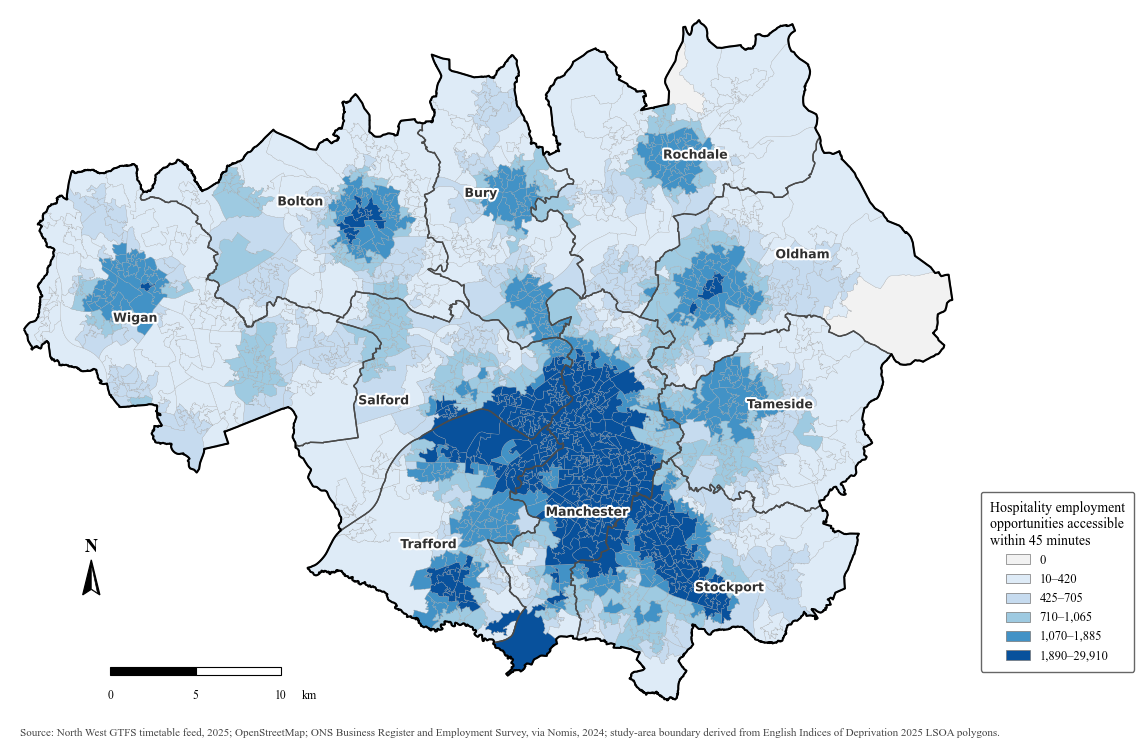

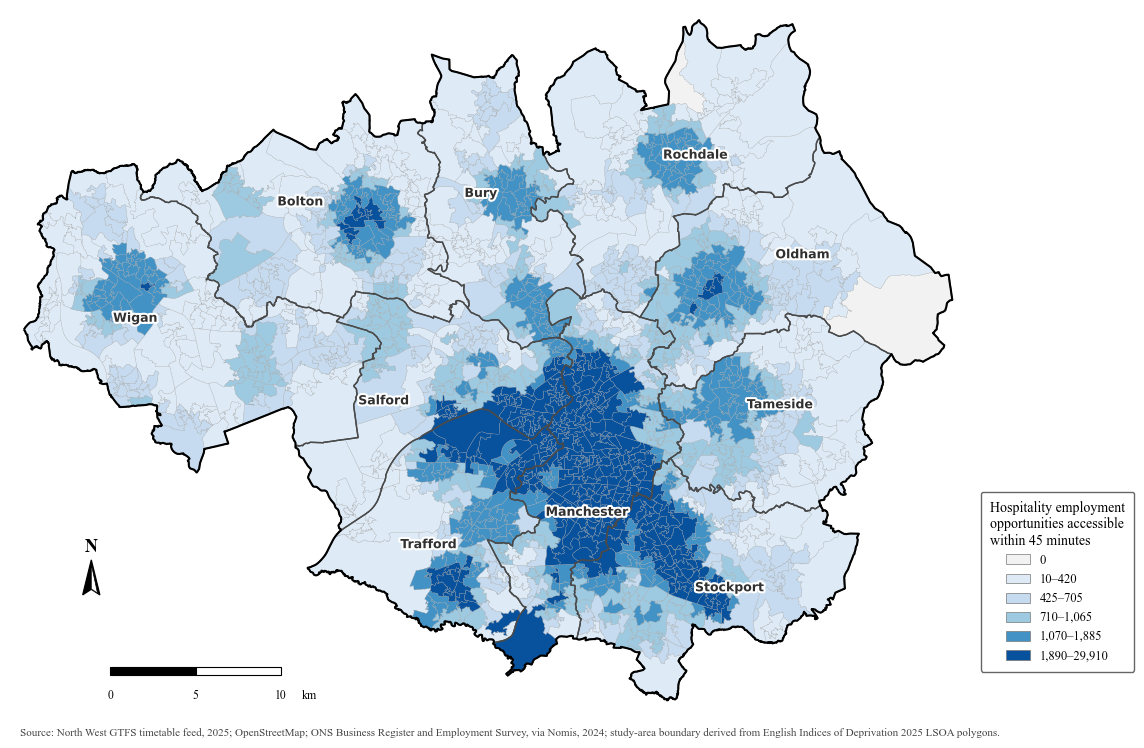

In [ ]:
# check required objects
required_objects = [
    "accessibility_without_pilot_gdf",
    "accessibility_with_pilot_gdf",
    "imd_gm",
    "results_output_dir"
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise NameError(
        "The following required objects are missing: "
        f"{missing_objects}"
    )

# output paths
results_output_dir = Path(
    results_output_dir
)

results_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

without_pilot_map_path = (
    results_output_dir
    / "night_accessibility_without_pilot_45min.png"
)

with_pilot_map_path = (
    results_output_dir
    / "night_accessibility_with_pilot_45min.png"
)

# accessibility columns
without_column = (
    "Jobs_45min_without_pilot"
)

with_column = (
    "Jobs_45min_with_pilot"
)

# prepare accessibility map layers
without_map_gdf = (
    accessibility_without_pilot_gdf
    .copy()
)

with_map_gdf = (
    accessibility_with_pilot_gdf
    .copy()
)

for gdf, column in [
    (
        without_map_gdf,
        without_column
    ),
    (
        with_map_gdf,
        with_column
    )
]:

    if column not in gdf.columns:

        raise KeyError(
            f"{column} was not found "
            "in the accessibility data."
        )

    gdf[
        column
    ] = pd.to_numeric(
        gdf[
            column
        ],
        errors="coerce"
    )

    if gdf[
        column
    ].isna().any():

        raise ValueError(
            f"Missing values were identified "
            f"in {column}."
        )

    if gdf.crs is None:

        raise ValueError(
            "Accessibility map CRS is not defined."
        )

# ensure British National Grid
if without_map_gdf.crs.to_epsg() != 27700:

    without_map_gdf = (
        without_map_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

if with_map_gdf.crs.to_epsg() != 27700:

    with_map_gdf = (
        with_map_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

# recreate metropolitan borough boundaries
if "LSOA21NM" not in imd_gm.columns:

    raise KeyError(
        "LSOA21NM was not found in imd_gm."
    )

if imd_gm.crs is None:

    raise ValueError(
        "imd_gm CRS is not defined."
    )

borough_boundaries = (
    imd_gm[
        [
            "LSOA21NM",
            "geometry"
        ]
    ]
    .copy()
)

if borough_boundaries.crs.to_epsg() != 27700:

    borough_boundaries = (
        borough_boundaries
        .to_crs(
            "EPSG:27700"
        )
    )

# extract borough name from LSOA name
borough_boundaries[
    "Borough"
] = (
    borough_boundaries[
        "LSOA21NM"
    ]
    .astype(str)
    .str.extract(
        r"^(.+?)\s+\d{3}[A-Z]$"
    )[0]
)

if borough_boundaries[
    "Borough"
].isna().any():

    raise ValueError(
        "Some borough names could not be "
        "extracted from LSOA21NM."
    )

# dissolve LSOAs into metropolitan boroughs
borough_boundaries = (
    borough_boundaries[
        [
            "Borough",
            "geometry"
        ]
    ]
    .dissolve(
        by="Borough"
    )
    .reset_index()
)

# create borough label points
borough_label_points = (
    borough_boundaries[
        [
            "Borough",
            "geometry"
        ]
    ]
    .copy()
)

borough_label_points[
    "geometry"
] = (
    borough_label_points
    .representative_point()
)

# borough label offsets
borough_offsets = {
    "Manchester":
        (
            0,
            -1800
        ),

    "Salford":
        (
            -1800,
            600
        ),

    "Trafford":
        (
            -800,
            -1100
        ),

    "Stockport":
        (
            1200,
            -500
        ),

    "Tameside":
        (
            1000,
            500
        ),

    "Oldham":
        (
            700,
            500
        ),

    "Rochdale":
        (
            700,
            800
        ),

    "Bury":
        (
            0,
            500
        ),

    "Bolton":
        (
            -500,
            500
        ),

    "Wigan":
        (
            -300,
            0
        )
}

# borough label function
def add_borough_labels(
    axis,
    label_gdf
):

    for _, row in label_gdf.iterrows():

        borough_name = (
            row[
                "Borough"
            ]
        )

        x_offset, y_offset = (
            borough_offsets.get(
                borough_name,
                (
                    0,
                    0
                )
            )
        )

        label = axis.text(
            row.geometry.x + x_offset,
            row.geometry.y + y_offset,
            borough_name,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color="#303030",
            zorder=20
        )

        label.set_path_effects(
            [
                path_effects.Stroke(
                    linewidth=3,
                    foreground="white"
                ),
                path_effects.Normal()
            ]
        )

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        family="Times New Roman",
        color="black",
        zorder=30
    )

    outer_arrow = np.array(
        [
            [
                x,
                y + size
            ],
            [
                x - size * 0.18,
                y
            ],
            [
                x,
                y + size * 0.16
            ],
            [
                x + size * 0.18,
                y
            ]
        ]
    )

    outer_display = (
        axis.transAxes
        .transform(
            outer_arrow
        )
    )

    outer_data = (
        axis.transData
        .inverted()
        .transform(
            outer_display
        )
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array(
        [
            [
                x,
                y + size * 0.88
            ],
            [
                x,
                y + size * 0.17
            ],
            [
                x + size * 0.13,
                y + size * 0.05
            ]
        ]
    )

    inner_display = (
        axis.transAxes
        .transform(
            inner_arrow
        )
    )

    inner_data = (
        axis.transData
        .inverted()
        .transform(
            inner_display
        )
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

# scale bar
def add_scale_bar(
    axis
):

    xmin, xmax = (
        axis.get_xlim()
    )

    ymin, ymax = (
        axis.get_ylim()
    )

    map_width = (
        xmax - xmin
    )

    map_height = (
        ymax - ymin
    )

    scale_x = (
        xmin
        + 0.105 * map_width
    )

    scale_y = (
        ymin
        + 0.050 * map_height
    )

    segment_length = (
        5000
    )

    bar_height = (
        480
    )

    for segment, colour in enumerate(
        [
            "black",
            "white"
        ]
    ):

        axis.add_patch(
            Rectangle(
                (
                    scale_x
                    + segment
                    * segment_length,
                    scale_y
                ),
                segment_length,
                bar_height,
                facecolor=colour,
                edgecolor="black",
                linewidth=0.8,
                zorder=25
            )
        )

    for distance, position in zip(
        [
            0,
            5,
            10
        ],
        [
            scale_x,
            scale_x + 5000,
            scale_x + 10000
        ]
    ):

        axis.text(
            position,
            scale_y - 850,
            str(
                distance
            ),
            ha="center",
            va="top",
            fontsize=8.5,
            family="Times New Roman",
            color="black",
            zorder=25
        )

    axis.text(
        scale_x + 11200,
        scale_y - 850,
        "km",
        ha="left",
        va="top",
        fontsize=8.5,
        family="Times New Roman",
        color="black",
        zorder=25
    )

# create accessibility classification
pooled_accessibility_values = pd.concat(
    [
        without_map_gdf[
            without_column
        ],
        with_map_gdf[
            with_column
        ]
    ],
    ignore_index=True
)

positive_pooled_values = (
    pooled_accessibility_values[
        pooled_accessibility_values > 0
    ]
)

if positive_pooled_values.empty:

    raise ValueError(
        "No positive accessibility values "
        "were identified."
    )

# five quantile classes for positive accessibility
common_accessibility_boundaries = (
    positive_pooled_values
    .quantile(
        [
            0.00,
            0.20,
            0.40,
            0.60,
            0.80,
            1.00
        ]
    )
    .to_numpy()
)

common_accessibility_boundaries = (
    np.unique(
        common_accessibility_boundaries
    )
)

if len(
    common_accessibility_boundaries
) < 3:

    raise ValueError(
        "There are insufficient unique "
        "accessibility values to create classes."
    )


# assign accessibility classes
def assign_accessibility_classes(
    gdf,
    value_column
):

    result = (
        gdf.copy()
    )

    result[
        "Accessibility_class"
    ] = 0

    positive_mask = (
        result[
            value_column
        ] > 0
    )

    result.loc[
        positive_mask,
        "Accessibility_class"
    ] = (
        pd.cut(
            result.loc[
                positive_mask,
                value_column
            ],
            bins=common_accessibility_boundaries,
            labels=False,
            include_lowest=True,
            duplicates="drop"
        )
        + 1
    )

    result[
        "Accessibility_class"
    ] = (
        result[
            "Accessibility_class"
        ]
        .astype(
            "Int64"
        )
    )

    return result


without_map_gdf = (
    assign_accessibility_classes(
        without_map_gdf,
        without_column
    )
)

with_map_gdf = (
    assign_accessibility_classes(
        with_map_gdf,
        with_column
    )
)

# colour scheme
accessibility_colours = [
    "#F2F2F2",
    "#DEEBF7",
    "#C6DBEF",
    "#9ECAE1",
    "#4292C6",
    "#08519C"
]

# create legend labels
common_accessibility_labels = {
    0:
        "0"
}

number_positive_classes = (
    len(
        common_accessibility_boundaries
    )
    - 1
)

pooled_class_df = pd.DataFrame(
    {
        "Accessibility":
            positive_pooled_values
    }
)

pooled_class_df[
    "Class"
] = (
    pd.cut(
        pooled_class_df[
            "Accessibility"
        ],
        bins=common_accessibility_boundaries,
        labels=False,
        include_lowest=True,
        duplicates="drop"
    )
    + 1
)

for class_value in range(
    1,
    number_positive_classes + 1
):

    class_values = (
        pooled_class_df.loc[
            pooled_class_df[
                "Class"
            ] == class_value,
            "Accessibility"
        ]
    )

    if class_values.empty:

        continue

    class_minimum = int(
        round(
            class_values.min()
        )
    )

    class_maximum = int(
        round(
            class_values.max()
        )
    )

    common_accessibility_labels[
        class_value
    ] = (
        f"{class_minimum:,}–"
        f"{class_maximum:,}"
    )

# classes appearing in either scenario
common_classes = sorted(
    set(
        without_map_gdf[
            "Accessibility_class"
        ]
        .dropna()
        .astype(int)
        .unique()
    )
    |
    set(
        with_map_gdf[
            "Accessibility_class"
        ]
        .dropna()
        .astype(int)
        .unique()
    )
)

# check colour availability
if max(
    common_classes
) >= len(
    accessibility_colours
):

    raise ValueError(
        "More accessibility classes were created "
        "than available map colours."
    )

# legend handles
legend_handles = [
    Patch(
        facecolor=accessibility_colours[
            class_value
        ],
        edgecolor="#777777",
        linewidth=0.5,
        label=common_accessibility_labels[
            class_value
        ]
    )
    for class_value
    in common_classes
]

# map extent
xmin, ymin, xmax, ymax = (
    without_map_gdf.total_bounds
)

x_margin = (
    xmax - xmin
) * 0.015

y_margin = (
    ymax - ymin
) * 0.015

common_xlim = (
    xmin - x_margin,
    xmax + x_margin
)

common_ylim = (
    ymin - y_margin,
    ymax + y_margin
)

# map styling
lsoa_boundary_colour = (
    "#A0A0A0"
)

lsoa_boundary_width = (
    0.18
)

borough_boundary_colour = (
    "#4A4A4A"
)

borough_boundary_width = (
    1.0
)

external_boundary_width = (
    1.50
)

# source information
source_note = (
    "Source: North West GTFS timetable feed, 2025; OpenStreetMap; "
    "ONS Business Register and Employment Survey, via Nomis, 2024; "
    "study-area boundary derived from English Indices of Deprivation 2025 LSOA polygons."
)

# map function
def plot_accessibility_map(
    map_gdf,
    output_path
):

    fig, ax = plt.subplots(
        figsize=(
            12.5,
            10
        )
    )

    # accessibility classes
    for class_value in common_classes:

        class_layer = (
            map_gdf.loc[
                map_gdf[
                    "Accessibility_class"
                ] == class_value
            ]
        )

        if class_layer.empty:

            continue

        class_layer.plot(
            ax=ax,
            facecolor=accessibility_colours[
                class_value
            ],
            edgecolor=lsoa_boundary_colour,
            linewidth=lsoa_boundary_width,
            zorder=1
        )

    # borough boundaries
    borough_boundaries.boundary.plot(
        ax=ax,
        color=borough_boundary_colour,
        linewidth=borough_boundary_width,
        zorder=5
    )

    # Greater Manchester external boundary
    map_gdf.dissolve().boundary.plot(
        ax=ax,
        color="black",
        linewidth=external_boundary_width,
        zorder=6
    )

    # map extent
    ax.set_xlim(
        common_xlim
    )

    ax.set_ylim(
        common_ylim
    )

    ax.set_aspect(
        "equal"
    )

    # borough labels
    add_borough_labels(
        axis=ax,
        label_gdf=borough_label_points
    )

    # north arrow
    add_north_arrow(
        axis=ax
    )

    # scale bar
    add_scale_bar(
        axis=ax
    )

    # legend
    legend = ax.legend(
        handles=legend_handles,
        title=(
            "Hospitality employment\n"
            "opportunities accessible\n"
            "within 45 minutes"
        ),
        loc="lower left",
        bbox_to_anchor=(
            1.015,
            0.055
        ),
        borderaxespad=0,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="#666666",
        fontsize=9,
        title_fontsize=10,
        labelspacing=0.55,
        borderpad=0.75,
        handlelength=1.9,
        handleheight=0.85,
        prop={
            "family":
                "Times New Roman",

            "size":
                9
        }
    )

    legend.get_title().set_fontweight(
        "normal"
    )

    legend.get_title().set_fontfamily(
        "Times New Roman"
    )

    # source
    ax.text(
        0.01,
        -0.025,
        source_note,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8.0,
        family="Times New Roman",
        color="#444444"
    )

    ax.set_axis_off()

    # layout
    fig.subplots_adjust(
        left=0.025,
        right=0.79,
        top=0.97,
        bottom=0.070
    )

    # save and display
    fig.savefig(
        output_path,
        dpi=600,
        facecolor="white",
        bbox_inches="tight"
    )

    plt.show()

    plt.close(
        fig
    )

# without-pilot map
plot_accessibility_map(
    without_map_gdf,
    without_pilot_map_path
)

# with-pilot map
plot_accessibility_map(
    with_map_gdf,
    with_pilot_map_path
)

Figure 8 shows that the overall spatial pattern of accessibility with the pilot remains similar to that observed without the pilot. Higher accessibility continues to be concentrated in Manchester and the surrounding inner urban area, while lower accessibility remains more common across the outer parts of Greater Manchester. The broad metropolitan pattern is largely unchanged by the four overnight pilot services.

Although the overall spatial structure remains similar, some LSOAs move to higher accessibility classes when the pilot services are included. These differences are difficult to distinguish from the two accessibility figures. The most LSOAs remain in the same class under both scenarios. The limited visual difference between Figure 7 and Figure 8 should not be interpreted as an absence of accessibility improvement. It indicates that the effects of the pilot are spatially concentrated rather than distributed across Greater Manchester. 

### 4.1.3 Accessibility Change

The effect of the overnight bus pilot was assessed by comparing the accessibility score for each LSOA under the with-pilot and without-pilot scenarios. Since the same analysis date, departure period, origins, destinations and 45-minute travel-time threshold were applied to both scenarios, the difference between the two accessibility scores represents the change associated with the inclusion of the four pilot services. The resulting accessibility change was examined using both descriptive statistics and spatial analysis.

In [ ]:
# create LSOA-level accessibility change dataset
accessibility_change_gdf = (
    accessibility_without_pilot_gdf[
        [
            "LSOA21CD",
            "LSOA21NM",
            "Jobs_45min_without_pilot",
            "geometry"
        ]
    ]
    .merge(
        accessibility_with_pilot_gdf[
            [
                "LSOA21CD",
                "Jobs_45min_with_pilot"
            ]
        ],
        on="LSOA21CD",
        how="inner",
        validate="one_to_one"
    )
    .copy()
)

# calculate absolute accessibility change
accessibility_change_gdf[
    "Accessibility_change"
] = (
    accessibility_change_gdf[
        "Jobs_45min_with_pilot"
    ]
    -
    accessibility_change_gdf[
        "Jobs_45min_without_pilot"
    ]
)

# calculate percentage accessibility change
undefined_percentage = (
    (
        accessibility_change_gdf[
            "Jobs_45min_without_pilot"
        ] == 0
    )
    &
    (
        accessibility_change_gdf[
            "Jobs_45min_with_pilot"
        ] > 0
    )
)

if undefined_percentage.any():

    raise ValueError(
        "Percentage accessibility change is undefined "
        "where without-pilot accessibility is zero "
        "and with-pilot accessibility is positive."
    )

accessibility_change_gdf[
    "Accessibility_change_percent"
] = 0.0

positive_baseline = (
    accessibility_change_gdf[
        "Jobs_45min_without_pilot"
    ] > 0
)

accessibility_change_gdf.loc[
    positive_baseline,
    "Accessibility_change_percent"
] = (
    accessibility_change_gdf.loc[
        positive_baseline,
        "Accessibility_change"
    ]
    /
    accessibility_change_gdf.loc[
        positive_baseline,
        "Jobs_45min_without_pilot"
    ]
    * 100
)

# validate LSOA coverage
if len(
    accessibility_change_gdf
) != len(
    accessibility_without_pilot_gdf
):

    raise ValueError(
        "The accessibility comparison does not "
        "contain all Greater Manchester LSOAs."
    )

# check duplicate LSOA IDs
if accessibility_change_gdf[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the accessibility change dataset."
    )

# check missing values
required_change_columns = [
    "Jobs_45min_without_pilot",
    "Jobs_45min_with_pilot",
    "Accessibility_change",
    "Accessibility_change_percent"
]

if accessibility_change_gdf[
    required_change_columns
].isna().any().any():

    raise ValueError(
        "Missing accessibility values were identified "
        "in the scenario comparison."
    )

# classify direction of change
accessibility_change_gdf[
    "Change_category"
] = "No change"

accessibility_change_gdf.loc[
    accessibility_change_gdf[
        "Accessibility_change"
    ] > 0,
    "Change_category"
] = "Increase"

accessibility_change_gdf.loc[
    accessibility_change_gdf[
        "Accessibility_change"
    ] < 0,
    "Change_category"
] = "Decrease"

# ensure British National Grid
if accessibility_change_gdf.crs is None:

    raise ValueError(
        "The accessibility change layer CRS "
        "is not defined."
    )

if accessibility_change_gdf.crs.to_epsg() != 27700:

    accessibility_change_gdf = (
        accessibility_change_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

In [ ]:
# store summary statistics for percentage accessibility change
accessibility_change_values = pd.to_numeric(
    accessibility_change_gdf[
        "Accessibility_change_percent"
    ],
    errors="coerce"
)

if accessibility_change_values.isna().any():

    raise ValueError(
        "Missing accessibility change values "
        "were identified."
    )

# store statistics for the comparison table
accessibility_change_summary_stats = {
    "LSOAs": len(
        accessibility_change_values
    ),
    "Mean": accessibility_change_values.mean(),
    "Median": accessibility_change_values.median(),
    "Standard deviation": accessibility_change_values.std(),
    "Q1": accessibility_change_values.quantile(
        0.25
    ),
    "Q3": accessibility_change_values.quantile(
        0.75
    ),
    "Minimum": accessibility_change_values.min(),
    "Maximum": accessibility_change_values.max(),
    "Positive change": int(
        (
            accessibility_change_values
            > 0
        ).sum()
    ),
    "No change": int(
        (
            accessibility_change_values
            == 0
        ).sum()
    ),
    "Negative change": int(
        (
            accessibility_change_values
            < 0
        ).sum()
    )
}

# score statistics for LSOAs with positive change
positive_change_values = (
    accessibility_change_values.loc[
        accessibility_change_values > 0
    ]
)

positive_change_summary_stats = {
    "Count": len(
        positive_change_values
    ),
    "Mean": positive_change_values.mean(),
    "Median": positive_change_values.median(),
    "Standard deviation": positive_change_values.std(),
    "Minimum": positive_change_values.min(),
    "Maximum": positive_change_values.max()
}

In [ ]:
# create the comparison table
total_lsoas = len(
    accessibility_change_gdf
)

positive_change_count = (
    accessibility_change_summary_stats[
        "Positive change"
    ]
)

no_change_count = (
    accessibility_change_summary_stats[
        "No change"
    ]
)

positive_change_percentage = (
    positive_change_count
    / total_lsoas
    * 100
)

no_change_percentage = (
    no_change_count
    / total_lsoas
    * 100
)

mean_positive_change = (
    positive_change_summary_stats[
        "Mean"
    ]
)

# create concise comparison table
accessibility_comparison_table = pd.DataFrame(
    {
        "Statistic": [
            "Mean",
            "Median",
            "Standard deviation",
            "Minimum",
            "Maximum",
            "Zero-access LSOAs",
            "LSOAs with positive change",
            "LSOAs with no change",
            "Mean percentage change among affected LSOAs"
        ],

        "Without pilot": [
            without_pilot_summary_stats[
                "Mean"
            ],
            without_pilot_summary_stats[
                "Median"
            ],
            without_pilot_summary_stats[
                "Standard deviation"
            ],
            without_pilot_summary_stats[
                "Minimum"
            ],
            without_pilot_summary_stats[
                "Maximum"
            ],
            without_pilot_summary_stats[
                "Zero accessibility"
            ],
            "—",
            "—",
            "—"
        ],

        "With pilot": [
            with_pilot_summary_stats[
                "Mean"
            ],
            with_pilot_summary_stats[
                "Median"
            ],
            with_pilot_summary_stats[
                "Standard deviation"
            ],
            with_pilot_summary_stats[
                "Minimum"
            ],
            with_pilot_summary_stats[
                "Maximum"
            ],
            with_pilot_summary_stats[
                "Zero accessibility"
            ],
            "—",
            "—",
            "—"
        ],

        "Percentage change (%)": [
            accessibility_change_summary_stats[
                "Mean"
            ],
            accessibility_change_summary_stats[
                "Median"
            ],
            accessibility_change_summary_stats[
                "Standard deviation"
            ],
            accessibility_change_summary_stats[
                "Minimum"
            ],
            accessibility_change_summary_stats[
                "Maximum"
            ],
            "—",
            (
                f"{positive_change_count:,} "
                f"({positive_change_percentage:.1f}%)"
            ),
            (
                f"{no_change_count:,} "
                f"({no_change_percentage:.1f}%)"
            ),
            mean_positive_change
        ]
    }
)

# numerical values
numeric_statistics = [
    "Mean",
    "Median",
    "Standard deviation",
    "Minimum",
    "Maximum",
    "Mean percentage change among affected LSOAs"
]

count_statistics = [
    "Zero-access LSOAs"
]

for column in [
    "Without pilot",
    "With pilot",
    "Percentage change (%)"
]:

    for index in accessibility_comparison_table.index:

        statistic = (
            accessibility_comparison_table.loc[
                index,
                "Statistic"
            ]
        )

        value = (
            accessibility_comparison_table.loc[
                index,
                column
            ]
        )

        if value == "—":

            continue

        if statistic in numeric_statistics:

            accessibility_comparison_table.loc[
                index,
                column
            ] = (
                f"{float(value):,.1f}"
            )

        elif statistic in count_statistics:

            accessibility_comparison_table.loc[
                index,
                column
            ] = (
                f"{int(value):,}"
            )

# display the comparison table
styled_accessibility_comparison_table = (
    accessibility_comparison_table
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family": "Times New Roman, serif",
            "font-size": "12pt",
            "padding": "10px 16px",
            "border": "none",
            "vertical-align": "middle"
        }
    )
    .set_properties(
        subset=[
            "Statistic"
        ],
        **{
            "text-align": "left"
        }
    )
    .set_properties(
        subset=[
            "Without pilot",
            "With pilot",
            "Percentage change (%)"
        ],
        **{
            "text-align": "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("border-top", "2px solid black"),
                    ("border-bottom", "2px solid black"),
                    ("width", "100%"),
                    ("margin", "0 auto")
                ]
            },
            {
                "selector": "thead th",
                "props": [
                    ("background-color", "#E8E8E8"),
                    ("font-family", "Times New Roman, serif"),
                    ("font-size", "12pt"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "12px 16px"),
                    ("border-bottom", "1.5px solid black"),
                    ("border-left", "none"),
                    ("border-right", "none")
                ]
            },
            {
                "selector": "thead th:first-child",
                "props": [
                    ("text-align", "left")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#F3F3F3")
                ]
            },
            {
                "selector": "tbody tr:nth-child(odd)",
                "props": [
                    ("background-color", "white")
                ]
            },
            {
                "selector": "tbody td",
                "props": [
                    ("border-left", "none"),
                    ("border-right", "none"),
                    ("border-top", "none"),
                    ("border-bottom", "none")
                ]
            },
            {
                "selector": "tbody tr:last-child td",
                "props": [
                    ("padding-bottom", "12px")
                ]
            }
        ]
    )
)

display(
    styled_accessibility_comparison_table
)

Statistic,Without pilot,With pilot,Percentage change (%)
Mean,"2,613.5","2,629.8",0.7
Median,865.0,867.5,0.0
Standard deviation,"5,295.7","5,326.7",7.4
Minimum,0.0,0.0,0.0
Maximum,"29,560.0","29,910.0",179.1
Zero-access LSOAs,2,2,—
LSOAs with positive change,—,—,63 (3.7%)
LSOAs with no change,—,—,"1,639 (96.3%)"
Mean percentage change among affected LSOAs,—,—,19.4


Table 4 shows that the overall accessibility effect of the pilot was relatively small when averaged across all 1,702 LSOAs. Mean accessibility increased from 2,613.5 hospitality employment opportunities in the without-pilot scenario to 2,629.8 with the pilot, representing an average increase of 16.3 opportunities. However, the median accessibility change was zero, while the standard deviation of change was 165.6 and the maximum increase reached 4,625 opportunities. This combination of a zero median, large dispersion and high maximum indicates that accessibility improvements were unevenly distributed and concentrated in a small number of LSOAs rather than occurring across Greater Manchester.

The limited metropolitan-wide average conceals a much larger difference between affected and unaffected areas. Only 63 LSOAs, equivalent to 3.7% of all LSOAs in Greater Manchester, recorded a positive accessibility change, while 1,639 LSOAs, or 96.3%, recorded no change. Among the 63 affected LSOAs, the mean increase was 440.0 accessible hospitality employment opportunities. These results show that the accessibility effect of the pilot was highly concentrated. The intervention produced no measurable improvement across most of Greater Manchester, but larger increases occurred within the small number of neighbourhoods that were affected.

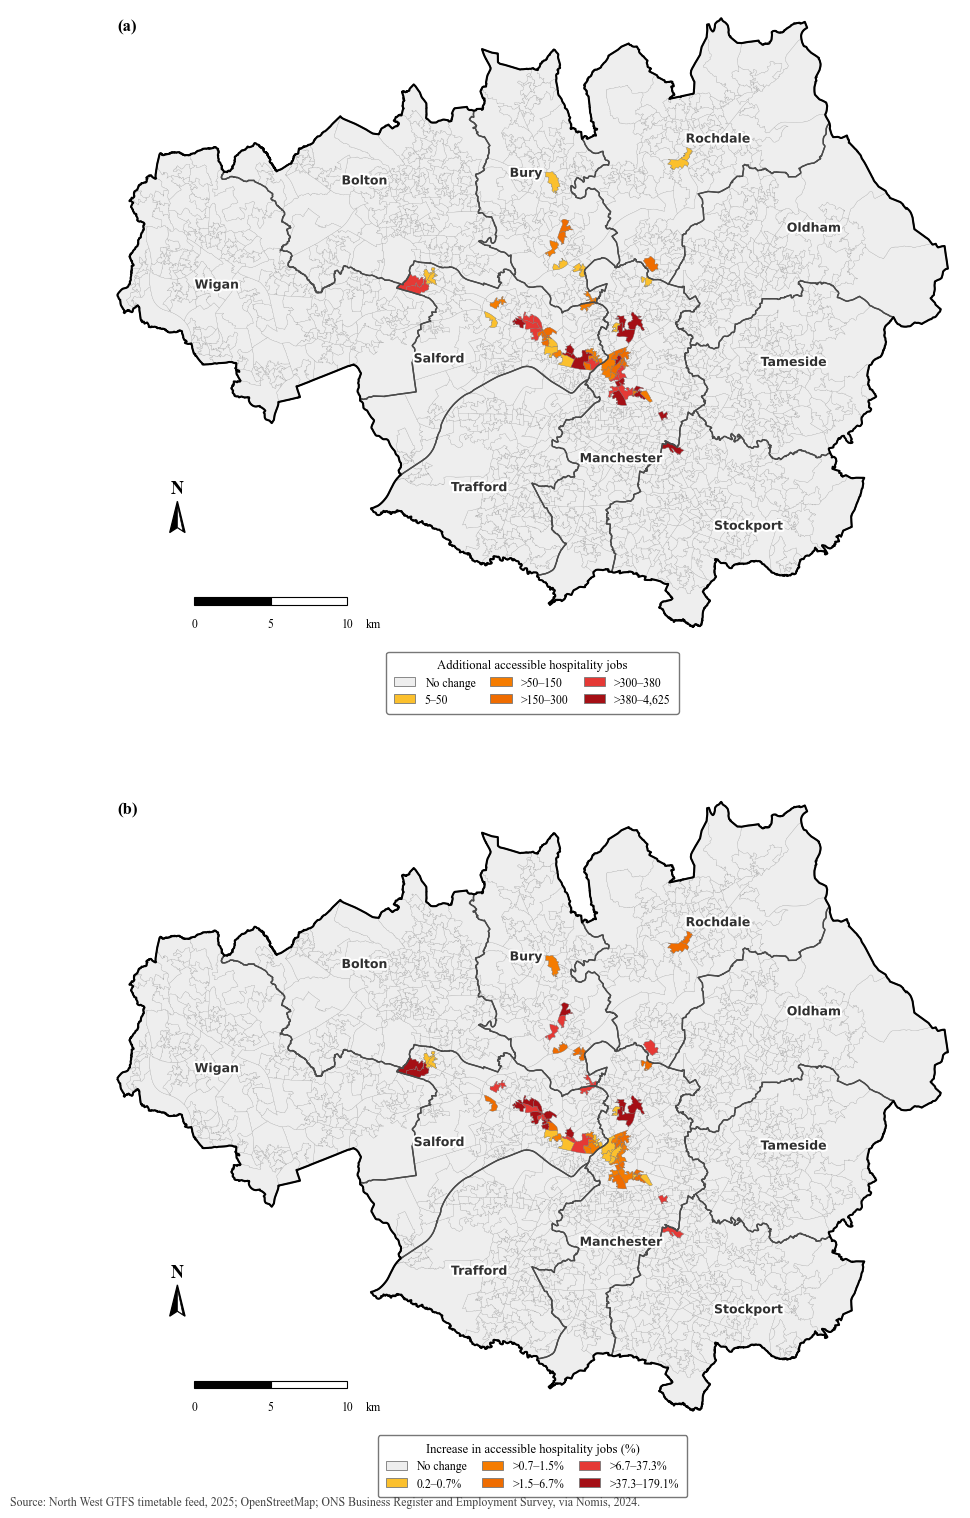

In [ ]:
# output path
accessibility_change_map_path = (
    results_output_dir
    / "night_accessibility_change_absolute_percentage_45min.png"
)

# columns
absolute_change_column = (
    "Accessibility_change"
)

baseline_column = (
    "Jobs_45min_without_pilot"
)

percentage_change_column = (
    "Accessibility_change_percent"
)

absolute_class_column = (
    "Absolute_change_class"
)

percentage_class_column = (
    "Percentage_change_class"
)

# prepare spatial layer
accessibility_change_map_gdf = (
    accessibility_change_gdf
    .copy()
)

required_columns = [
    absolute_change_column,
    baseline_column
]

missing_columns = [
    column
    for column in required_columns
    if column not in accessibility_change_map_gdf.columns
]

if missing_columns:

    raise KeyError(
        "The following required columns are missing: "
        f"{missing_columns}"
    )

for column in required_columns:

    accessibility_change_map_gdf[
        column
    ] = pd.to_numeric(
        accessibility_change_map_gdf[
            column
        ],
        errors="coerce"
    )

if accessibility_change_map_gdf[
    required_columns
].isna().any().any():

    raise ValueError(
        "Missing accessibility values were identified."
    )

if (
    accessibility_change_map_gdf[
        absolute_change_column
    ] < 0
).any():

    raise ValueError(
        "Negative accessibility changes were identified."
    )

if (
    accessibility_change_map_gdf[
        baseline_column
    ] < 0
).any():

    raise ValueError(
        "Negative baseline accessibility values were identified."
    )

# ensure British National Grid
if accessibility_change_map_gdf.crs is None:

    raise ValueError(
        "The accessibility change layer CRS is not defined."
    )

if accessibility_change_map_gdf.crs.to_epsg() != 27700:

    accessibility_change_map_gdf = (
        accessibility_change_map_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

if borough_boundaries.crs.to_epsg() != 27700:

    borough_boundaries = (
        borough_boundaries
        .to_crs(
            "EPSG:27700"
        )
    )

# calculate percentage accessibility change
positive_baseline_mask = (
    accessibility_change_map_gdf[
        baseline_column
    ] > 0
)

zero_baseline_mask = (
    accessibility_change_map_gdf[
        baseline_column
    ] == 0
)

undefined_percentage_mask = (
    zero_baseline_mask
    &
    (
        accessibility_change_map_gdf[
            absolute_change_column
        ] > 0
    )
)

if undefined_percentage_mask.any():

    raise ValueError(
        "At least one LSOA has zero without-pilot "
        "accessibility and a positive accessibility change. "
        "Percentage change is undefined."
    )

accessibility_change_map_gdf[
    percentage_change_column
] = 0.0

accessibility_change_map_gdf.loc[
    positive_baseline_mask,
    percentage_change_column
] = (
    accessibility_change_map_gdf.loc[
        positive_baseline_mask,
        absolute_change_column
    ]
    /
    accessibility_change_map_gdf.loc[
        positive_baseline_mask,
        baseline_column
    ]
    * 100
)

# function for quantile classification
def create_change_classes(
    gdf,
    value_column,
    class_column
):

    positive_values = (
        gdf.loc[
            gdf[
                value_column
            ] > 0,
            value_column
        ]
    )

    if positive_values.empty:

        raise ValueError(
            f"No positive values were found in {value_column}."
        )

    boundaries = (
        positive_values
        .quantile(
            [
                0.00,
                0.20,
                0.40,
                0.60,
                0.80,
                1.00
            ]
        )
        .to_numpy()
    )

    boundaries = np.unique(
        boundaries
    )

    if len(
        boundaries
    ) < 3:

        raise ValueError(
            f"Insufficient unique values in {value_column} "
            "to create quantile classes."
        )

    result = (
        gdf.copy()
    )

    result[
        class_column
    ] = 0

    positive_mask = (
        result[
            value_column
        ] > 0
    )

    result.loc[
        positive_mask,
        class_column
    ] = (
        pd.cut(
            result.loc[
                positive_mask,
                value_column
            ],
            bins=boundaries,
            labels=False,
            include_lowest=True,
            duplicates="drop"
        )
        + 1
    )

    result[
        class_column
    ] = (
        result[
            class_column
        ]
        .astype(
            "Int64"
        )
    )

    return (
        result,
        boundaries,
        positive_values
    )

# absolute-change classes
(
    accessibility_change_map_gdf,
    absolute_boundaries,
    positive_absolute_values
) = create_change_classes(
    gdf=accessibility_change_map_gdf,
    value_column=absolute_change_column,
    class_column=absolute_class_column
)

# percentage-change classes
(
    accessibility_change_map_gdf,
    percentage_boundaries,
    positive_percentage_values
) = create_change_classes(
    gdf=accessibility_change_map_gdf,
    value_column=percentage_change_column,
    class_column=percentage_class_column
)

# colours
change_colours = [
    "#EEEEEE",
    "#FBC02D",
    "#F57C00",
    "#EF6C00",
    "#E53935",
    "#A50F15"
]

# create legend labels from class boundaries
def format_absolute_boundary(
    value
):

    if np.isclose(
        value,
        round(value)
    ):

        return (
            f"{int(round(value)):,}"
        )

    return (
        f"{value:,.1f}"
    )

def format_percentage_boundary(
    value
):

    return (
        f"{value:.1f}"
    )

def create_boundary_labels(
    boundaries,
    percentage=False
):

    labels = {
        0:
            "No change"
    }

    number_classes = (
        len(
            boundaries
        )
        - 1
    )

    for class_index in range(
        number_classes
    ):

        class_value = (
            class_index
            + 1
        )

        lower_bound = (
            boundaries[
                class_index
            ]
        )

        upper_bound = (
            boundaries[
                class_index + 1
            ]
        )

        if percentage:

            lower_text = (
                format_percentage_boundary(
                    lower_bound
                )
            )

            upper_text = (
                format_percentage_boundary(
                    upper_bound
                )
            )

            if class_index == 0:

                labels[
                    class_value
                ] = (
                    f"{lower_text}–"
                    f"{upper_text}%"
                )

            else:

                labels[
                    class_value
                ] = (
                    f">{lower_text}–"
                    f"{upper_text}%"
                )

        else:

            lower_text = (
                format_absolute_boundary(
                    lower_bound
                )
            )

            upper_text = (
                format_absolute_boundary(
                    upper_bound
                )
            )

            if class_index == 0:

                labels[
                    class_value
                ] = (
                    f"{lower_text}–"
                    f"{upper_text}"
                )

            else:

                labels[
                    class_value
                ] = (
                    f">{lower_text}–"
                    f"{upper_text}"
                )

    return labels

# absolute-change legend labels
absolute_labels = (
    create_boundary_labels(
        boundaries=absolute_boundaries,
        percentage=False
    )
)

# percentage-change legend labels
percentage_labels = (
    create_boundary_labels(
        boundaries=percentage_boundaries,
        percentage=True
    )
)

# classes present
absolute_classes = sorted(
    accessibility_change_map_gdf[
        absolute_class_column
    ]
    .dropna()
    .astype(int)
    .unique()
)

percentage_classes = sorted(
    accessibility_change_map_gdf[
        percentage_class_column
    ]
    .dropna()
    .astype(int)
    .unique()
)

if max(
    absolute_classes
) >= len(
    change_colours
):

    raise ValueError(
        "There are more absolute-change classes "
        "than available colours."
    )

if max(
    percentage_classes
) >= len(
    change_colours
):

    raise ValueError(
        "There are more percentage-change classes "
        "than available colours."
    )

# legend handles
absolute_legend_handles = [
    Patch(
        facecolor=change_colours[
            class_value
        ],
        edgecolor="#777777",
        linewidth=0.6,
        label=absolute_labels[
            class_value
        ]
    )
    for class_value
    in absolute_classes
]

percentage_legend_handles = [
    Patch(
        facecolor=change_colours[
            class_value
        ],
        edgecolor="#777777",
        linewidth=0.6,
        label=percentage_labels[
            class_value
        ]
    )
    for class_value
    in percentage_classes
]

# map extent
xmin, ymin, xmax, ymax = (
    accessibility_change_map_gdf
    .total_bounds
)

x_margin = (
    xmax - xmin
) * 0.015

y_margin = (
    ymax - ymin
) * 0.015

common_xlim = (
    xmin - x_margin,
    xmax + x_margin
)

common_ylim = (
    ymin - y_margin,
    ymax + y_margin
)

# Greater Manchester external boundary
gm_change_boundary = (
    accessibility_change_map_gdf[
        [
            "geometry"
        ]
    ]
    .dissolve()
)

# map boundary styling
lsoa_boundary_colour = (
    "#A0A0A0"
)

lsoa_boundary_width = (
    0.18
)

borough_boundary_colour = (
    "#4A4A4A"
)

borough_boundary_width = (
    1.0
)

external_boundary_width = (
    1.50
)

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        family="Times New Roman",
        color="black",
        zorder=30
    )

    outer_arrow = np.array(
        [
            [
                x,
                y + size
            ],
            [
                x - size * 0.18,
                y
            ],
            [
                x,
                y + size * 0.16
            ],
            [
                x + size * 0.18,
                y
            ]
        ]
    )

    outer_display = (
        axis.transAxes
        .transform(
            outer_arrow
        )
    )

    outer_data = (
        axis.transData
        .inverted()
        .transform(
            outer_display
        )
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array(
        [
            [
                x,
                y + size * 0.88
            ],
            [
                x,
                y + size * 0.17
            ],
            [
                x + size * 0.13,
                y + size * 0.05
            ]
        ]
    )

    inner_display = (
        axis.transAxes
        .transform(
            inner_arrow
        )
    )

    inner_data = (
        axis.transData
        .inverted()
        .transform(
            inner_display
        )
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )


# scale bar
def add_scale_bar(
    axis
):

    xmin_map, xmax_map = (
        axis.get_xlim()
    )

    ymin_map, ymax_map = (
        axis.get_ylim()
    )

    map_width = (
        xmax_map
        - xmin_map
    )

    map_height = (
        ymax_map
        - ymin_map
    )

    scale_x = (
        xmin_map
        + 0.105 * map_width
    )

    scale_y = (
        ymin_map
        + 0.050 * map_height
    )

    segment_length = (
        5000
    )

    bar_height = (
        480
    )

    for segment, colour in enumerate(
        [
            "black",
            "white"
        ]
    ):

        axis.add_patch(
            Rectangle(
                (
                    scale_x
                    + segment
                    * segment_length,
                    scale_y
                ),
                segment_length,
                bar_height,
                facecolor=colour,
                edgecolor="black",
                linewidth=0.8,
                zorder=25
            )
        )

    for distance, position in zip(
        [
            0,
            5,
            10
        ],
        [
            scale_x,
            scale_x + 5000,
            scale_x + 10000
        ]
    ):

        axis.text(
            position,
            scale_y - 850,
            str(
                distance
            ),
            ha="center",
            va="top",
            fontsize=8.5,
            family="Times New Roman",
            zorder=25
        )

    axis.text(
        scale_x + 11200,
        scale_y - 850,
        "km",
        ha="left",
        va="top",
        fontsize=8.5,
        family="Times New Roman",
        zorder=25
    )

# map function
def plot_change_panel(
    axis,
    class_column,
    classes,
    legend_handles,
    legend_title,
    panel_label
):

    accessibility_change_map_gdf.plot(
        ax=axis,
        facecolor=change_colours[
            0
        ],
        edgecolor=lsoa_boundary_colour,
        linewidth=lsoa_boundary_width,
        zorder=1
    )

    for class_value in classes:

        if class_value == 0:

            continue

        class_layer = (
            accessibility_change_map_gdf.loc[
                accessibility_change_map_gdf[
                    class_column
                ] == class_value
            ]
        )

        if class_layer.empty:

            continue

        class_layer.plot(
            ax=axis,
            facecolor=change_colours[
                class_value
            ],
            edgecolor="#777777",
            linewidth=0.22,
            zorder=4
        )

    borough_boundaries.boundary.plot(
        ax=axis,
        color=borough_boundary_colour,
        linewidth=borough_boundary_width,
        zorder=6
    )

    gm_change_boundary.boundary.plot(
        ax=axis,
        color="black",
        linewidth=external_boundary_width,
        zorder=7
    )

    axis.set_xlim(
        common_xlim
    )

    axis.set_ylim(
        common_ylim
    )

    axis.set_aspect(
        "equal"
    )

    add_borough_labels(
        axis=axis,
        label_gdf=borough_label_points
    )

    add_north_arrow(
        axis=axis
    )

    add_scale_bar(
        axis=axis
    )

    axis.text(
        0.015,
        0.985,
        panel_label,
        transform=axis.transAxes,
        ha="left",
        va="top",
        fontsize=12,
        fontweight="bold",
        family="Times New Roman"
    )

    legend = axis.legend(
        handles=legend_handles,
        title=legend_title,
        loc="upper center",
        bbox_to_anchor=(
            0.50,
            -0.025
        ),
        ncol=3,
        borderaxespad=0,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="#777777",
        fontsize=8.5,
        title_fontsize=9.2,
        labelspacing=0.45,
        columnspacing=1.25,
        borderpad=0.65,
        handlelength=1.8,
        handleheight=0.80,
        prop={
            "family":
                "Times New Roman",

            "size":
                8.5
        }
    )

    legend.get_title().set_fontweight(
        "normal"
    )

    legend.get_title().set_fontfamily(
        "Times New Roman"
    )

    legend.get_title().set_ha(
        "center"
    )

    axis.set_axis_off()

# create figure
fig, axes = plt.subplots(
    2,
    1,
    figsize=(
        11,
        15.5
    )
)

# absolute accessibility change
plot_change_panel(
    axis=axes[
        0
    ],
    class_column=absolute_class_column,
    classes=absolute_classes,
    legend_handles=absolute_legend_handles,
    legend_title=(
        "Additional accessible hospitality jobs"
    ),
    panel_label="(a)"
)

# percentage accessibility change
plot_change_panel(
    axis=axes[
        1
    ],
    class_column=percentage_class_column,
    classes=percentage_classes,
    legend_handles=percentage_legend_handles,
    legend_title=(
        "Increase in accessible hospitality jobs (%)"
    ),
    panel_label="(b)"
)

# source information
source_note = (
    "Source: North West GTFS timetable feed, 2025; OpenStreetMap; "
    "ONS Business Register and Employment Survey, via Nomis, 2024."
)

fig.text(
    0.025,
    0.018,
    source_note,
    ha="left",
    va="bottom",
    fontsize=8.5,
    family="Times New Roman",
    color="#444444"
)

# layout
fig.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.985,
    bottom=0.075,
    hspace=0.25
)

# save and display
fig.savefig(
    accessibility_change_map_path,
    dpi=600,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

plt.close(
    fig
)

In [ ]:
# save accessibility change results
accessibility_change_output_path = (
    results_output_dir
    / "accessibility_change_45min.gpkg"
)

accessibility_change_csv_path = (
    results_output_dir
    / "accessibility_change_45min.csv"
)

# remove previous spatial output if present
if accessibility_change_output_path.exists():

    accessibility_change_output_path.unlink()

# save spatial result
accessibility_change_gdf.to_file(
    accessibility_change_output_path,
    layer="accessibility_change",
    driver="GPKG"
)

# save non-spatial result
accessibility_change_gdf[
    [
        "LSOA21CD",
        "LSOA21NM",
        "Jobs_45min_without_pilot",
        "Jobs_45min_with_pilot",
        "Accessibility_change",
        "Change_category"
    ]
].to_csv(
    accessibility_change_csv_path,
    index=False
)

# confirm outputs were created
if not accessibility_change_output_path.exists():

    raise FileNotFoundError(
        "The accessibility change GPKG "
        "was not created."
    )

if not accessibility_change_csv_path.exists():

    raise FileNotFoundError(
        "The accessibility change CSV "
        "was not created."
    )

Figure 9 illustrates the spatial distribution of accessibility change associated with the pilot. Most LSOAs recorded no change, while positive changes were concentrated in a relatively small number of areas. The largest increases occurred in and around central Manchester and in several areas extending north and west from the centre. Smaller clusters of improvement were also visible elsewhere across the network. Among the affected LSOAs, the scale of change varied considerably, ranging from fewer than 50 to more than 4,000 additional accessible hospitality employment opportunities.

The spatial pattern confirms that the accessibility improvement was concentrated rather than widespread across Greater Manchester. This also explains why the with-pilot and without-pilot accessibility maps appear broadly similar. Most LSOAs experienced no change, while larger improvements were confined to a small number of locations. 

## 4.2 Distributional Equity Analysis

The equity analysis examines whether the accessibility changes associated with the overnight bus pilot differed across neighbourhoods with different levels of income deprivation. The 1,702 LSOAs were divided into five income deprivation quintiles, from Q1 (least deprived) to Q5 (most deprived). Accessibility change was compared across these groups using descriptive and statistical analysis.

### 4.2.1 Accessibility Change by Income Deprivation

In [ ]:
# check required income-deprivation variable
if "IncomeScoreRate" not in imd_gm.columns:

    raise KeyError(
        "IncomeScoreRate was not found in imd_gm."
    )

# prepare income deprivation data
income_deprivation = (
    imd_gm[
        [
            "LSOA21CD",
            "IncomeScoreRate"
        ]
    ]
    .copy()
)

income_deprivation[
    "LSOA21CD"
] = (
    income_deprivation[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

income_deprivation[
    "IncomeScoreRate"
] = pd.to_numeric(
    income_deprivation[
        "IncomeScoreRate"
    ],
    errors="coerce"
)

if income_deprivation[
    "IncomeScoreRate"
].isna().any():

    raise ValueError(
        "Missing Income Deprivation values "
        "were identified."
    )

if income_deprivation[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the Income Deprivation data."
    )

# convert income score Rate to percentage
income_deprivation[
    "IncomeDeprivationPercent"
] = (
    income_deprivation[
        "IncomeScoreRate"
    ]
    * 100
)

# join accessibility change and income deprivation
equity_df = (
    accessibility_change_gdf[
        [
            "LSOA21CD",
            "LSOA21NM",
            "Jobs_45min_without_pilot",
            "Jobs_45min_with_pilot",
            "Accessibility_change",
            "Accessibility_change_percent",
            "geometry"
        ]
    ]

    .merge(
        income_deprivation,
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
    .copy()
)

# validate join
if equity_df[
    "IncomeScoreRate"
].isna().any():

    raise ValueError(
        "Some LSOAs could not be matched "
        "to Income Deprivation data."
    )

if len(
    equity_df
) != len(
    accessibility_change_gdf
):

    raise ValueError(
        "The equity dataset does not contain "
        "all study-area LSOAs."
    )

# create binary indicator for accessibility increase
equity_df[
    "Positive_change"
] = (
    equity_df[
        "Accessibility_change_percent"
    ] > 0
).astype(int)

# create Income Deprivation quintiles
income_quintile_labels = [
    "Q1",
    "Q2",
    "Q3",
    "Q4",
    "Q5"
]

equity_df[
    "IncomeQuintile"
] = pd.qcut(
    equity_df[
        "IncomeScoreRate"
    ],
    q=5,
    labels=income_quintile_labels
)

equity_df[
    "IncomeQuintile"
] = pd.Categorical(
    equity_df[
        "IncomeQuintile"
    ],
    categories=income_quintile_labels,
    ordered=True
)

# create numeric quintile code
equity_df[
    "IncomeQuintileCode"
] = (
    equity_df[
        "IncomeQuintile"
    ]
    .cat.codes
    + 1
)

In [ ]:
# summarise accessibility change by income deprivation quintile
equity_quintile_summary = (
    equity_df
    .groupby(
        "IncomeQuintile",
        observed=False
    )
    .agg(
        LSOAs=(
            "LSOA21CD",
            "count"
        ),

        Mean_change=(
            "Accessibility_change_percent",
            "mean"
        ),

        Median_change=(
            "Accessibility_change_percent",
            "median"
        ),

        Positive_change_LSOAs=(
            "Positive_change",
            "sum"
        )
    )
    .reset_index()
)

# calculate percentage of LSOAs with positive change
equity_quintile_summary[
    "Positive_change_percent"
] = (
    equity_quintile_summary[
        "Positive_change_LSOAs"
    ]
    /
    equity_quintile_summary[
        "LSOAs"
    ]
    * 100
)

# calculate mean change among affected LSOAs
positive_change_by_quintile = (
    equity_df.loc[
        equity_df[
            "Accessibility_change_percent"
        ] > 0
    ]
    .groupby(
        "IncomeQuintile",
        observed=False
    )
    .agg(
        Mean_change_affected=(
            "Accessibility_change_percent",
            "mean"
        )
    )
    .reset_index()
)

# merge affected-LSOA statistics
equity_quintile_summary = (
    equity_quintile_summary
    .merge(
        positive_change_by_quintile,
        on="IncomeQuintile",
        how="left",
        validate="one_to_one"
    )
)

# create concise table for display
equity_quintile_table = pd.DataFrame(
    {
        "Income deprivation quintile": (
            equity_quintile_summary[
                "IncomeQuintile"
            ]
            .astype(str)
        ),

        "LSOAs": (
            equity_quintile_summary[
                "LSOAs"
            ]
            .astype(int)
        ),

        "Mean percentage change": (
            equity_quintile_summary[
                "Mean_change"
            ]
            .round(1)
        ),

        "Median percentage change": (
            equity_quintile_summary[
                "Median_change"
            ]
            .round(1)
        ),

        "LSOAs with positive change": [
            (
                f"{int(count):,} "
                f"({percentage:.1f}%)"
            )
            for count, percentage
            in zip(
                equity_quintile_summary[
                    "Positive_change_LSOAs"
                ],
                equity_quintile_summary[
                    "Positive_change_percent"
                ]
            )
        ],

        "Mean percentage change among affected LSOAs": (
            equity_quintile_summary[
                "Mean_change_affected"
            ]
            .round(1)
        )
    }
)

# format numerical columns
for column in [
    "Mean percentage change",
    "Median percentage change",
    "Mean percentage change among affected LSOAs"
]:

    equity_quintile_table[
        column
    ] = (
        equity_quintile_table[
            column
        ]
        .map(
            lambda value:
            f"{value:,.1f}"
        )
    )

# display table
styled_equity_quintile_table = (
    equity_quintile_table
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family":
                "Times New Roman, serif",

            "font-size":
                "12pt",

            "padding":
                "10px 12px",

            "border":
                "none",

            "vertical-align":
                "middle"
        }
    )
    .set_properties(
        subset=[
            "Income deprivation quintile"
        ],
        **{
            "text-align":
                "left"
        }
    )
    .set_properties(
        subset=[
            "LSOAs",
            "Mean percentage change",
            "Median percentage change",
            "LSOAs with positive change",
            "Mean percentage change among affected LSOAs"
        ],
        **{
            "text-align":
                "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector":
                    "table",

                "props": [
                    (
                        "border-collapse",
                        "collapse"
                    ),
                    (
                        "border-top",
                        "2px solid black"
                    ),
                    (
                        "border-bottom",
                        "2px solid black"
                    ),
                    (
                        "width",
                        "100%"
                    ),
                    (
                        "margin",
                        "0 auto"
                    )
                ]
            },

            {
                "selector":
                    "thead th",

                "props": [
                    (
                        "background-color",
                        "#E8E8E8"
                    ),
                    (
                        "font-family",
                        "Times New Roman, serif"
                    ),
                    (
                        "font-size",
                        "12pt"
                    ),
                    (
                        "font-weight",
                        "bold"
                    ),
                    (
                        "text-align",
                        "center"
                    ),
                    (
                        "padding",
                        "12px 12px"
                    ),
                    (
                        "border-bottom",
                        "1.5px solid black"
                    ),
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    )
                ]
            },

            {
                "selector":
                    "thead th:first-child",

                "props": [
                    (
                        "text-align",
                        "left"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(even)",

                "props": [
                    (
                        "background-color",
                        "#F3F3F3"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(odd)",

                "props": [
                    (
                        "background-color",
                        "white"
                    )
                ]
            },

            {
                "selector":
                    "tbody td",

                "props": [
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    ),
                    (
                        "border-top",
                        "none"
                    ),
                    (
                        "border-bottom",
                        "none"
                    )
                ]
            }
        ]
    )
)

display(
    styled_equity_quintile_table
)

Income deprivation quintile,LSOAs,Mean percentage change,Median percentage change,LSOAs with positive change,Mean percentage change among affected LSOAs
Q1 (least deprived),343,0.3,0.0,14 (4.1%),7.5
Q2,339,0.8,0.0,14 (4.1%),18.6
Q3,342,0.3,0.0,10 (2.9%),11.2
Q4,337,0.5,0.0,8 (2.4%),21.9
Q5 (most deprived),341,1.7,0.0,17 (5.0%),33.5


Table 5 compares accessibility change across the five income deprivation quintiles. The proportion of LSOAs recording a positive change varied between 2.4% and 5.0%. The highest proportion was found in Q5, where 17 LSOAs, or 5.0%, experienced an increase in accessibility. Q1 and Q2 each recorded positive changes in 4.1% of LSOAs, compared with 2.9% in Q3 and 2.4% in Q4.

The mean accessibility changes also varied across the quintiles. Q5 recorded the largest mean increase across all LSOAs at 31.4 accessible hospitality employment opportunities, followed by Q4 at 16.3. The corresponding values were 9.1 in Q1, 12.8 in Q2 and 11.9 in Q3. However, these averages include the large number of LSOAs that experienced no change.

Among LSOAs with a positive accessibility change, the size of the improvement was greater in the more deprived groups. The mean increase among affected LSOAs was 222.1 opportunities in Q1 and 311.1 in Q2, compared with 407.0 in Q3, 685.6 in Q4 and 629.4 in Q5. Nevertheless, the proportion of LSOAs benefiting from the pilot did not increase consistently with deprivation. Q4 had the lowest proportion of affected LSOAs despite recording the largest mean increase among those that were affected.

The descriptive results do not show a simple relationship between income deprivation and accessibility change. The most deprived quintile recorded both the highest overall mean change and the highest proportion of LSOAs with a positive change, but the pattern across the intermediate quintiles was uneven.

### 4.2.2 Statistical Comparison

In [ ]:
from scipy.stats import kruskal

# prepare quintile groups
quintile_groups = []

for quintile in income_quintile_labels:

    group_values = (
        equity_df.loc[
            equity_df[
                "IncomeQuintile"
            ] == quintile,
            "Accessibility_change_percent"
        ]
        .dropna()
        .to_numpy()
    )

    if len(group_values) == 0:

        raise ValueError(
            f"No observations were found for {quintile}."
        )

    quintile_groups.append(
        group_values
    )

# kruskal–wallis test
kw_statistic, kw_p_value = kruskal(
    *quintile_groups
)

# epsilon-squared
n_total = sum(
    len(group)
    for group in quintile_groups
)

n_groups = len(
    quintile_groups
)

epsilon_squared = (
    kw_statistic
    - n_groups
    + 1
) / (
    n_total
    - n_groups
)

epsilon_squared = max(
    0,
    epsilon_squared
)

# store results
kruskal_wallis_results = pd.DataFrame(
    {
        "Statistic": [
            "Kruskal–Wallis H",
            "Degrees of freedom",
            "p-value",
            "Epsilon-squared"
        ],

        "Value": [
            f"{kw_statistic:.3f}",
            f"{n_groups - 1}",
            (
                f"{kw_p_value:.4f}"
                if kw_p_value >= 0.0001
                else "<0.0001"
            ),
            f"{epsilon_squared:.4f}"
        ]
    }
)

# display table
styled_kruskal_wallis_results = (
    kruskal_wallis_results
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family": "Times New Roman, serif",
            "font-size": "12pt",
            "padding": "9px 14px",
            "border": "none"
        }
    )
    .set_properties(
        subset=[
            "Statistic"
        ],
        **{
            "text-align": "left"
        }
    )
    .set_properties(
        subset=[
            "Value"
        ],
        **{
            "text-align": "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector": "table",
                "props": [
                    (
                        "border-collapse",
                        "collapse"
                    ),
                    (
                        "border-top",
                        "2px solid black"
                    ),
                    (
                        "border-bottom",
                        "2px solid black"
                    ),
                    (
                        "width",
                        "55%"
                    )
                ]
            },

            {
                "selector": "thead th",
                "props": [
                    (
                        "background-color",
                        "#E8E8E8"
                    ),
                    (
                        "font-weight",
                        "bold"
                    ),
                    (
                        "text-align",
                        "center"
                    ),
                    (
                        "padding",
                        "10px 14px"
                    ),
                    (
                        "border-bottom",
                        "1.5px solid black"
                    )
                ]
            },

            {
                "selector": "thead th:first-child",
                "props": [
                    (
                        "text-align",
                        "left"
                    )
                ]
            },

            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    (
                        "background-color",
                        "#F3F3F3"
                    )
                ]
            }
        ]
    )
)

display(
    styled_kruskal_wallis_results
)

Statistic,Value
Kruskal–Wallis H,4.178
Degrees of freedom,4
p-value,0.3824
Epsilon-squared,0.0001


As shown in Table 6, the Kruskal–Wallis test was used to examine whether accessibility change differed across the five income deprivation quintiles. The test found no significant difference between the groups, H(4)=4.215, p=0.378. The estimated effect size was also negligible, with an epsilon-squared value of 0.0001.

Although some variation in mean accessibility changes and in the proportion of LSOAs experiencing a positive change, these differences were not consistent to indicate a systematic difference between deprivation groups. The higher values observed in Q5 did not form part of a clear gradient across the five quintiles.

The results provide no statistical evidence that accessibility change differed systematically according to income deprivation. This suggests that the descriptive differences observed between the groups cannot be attributed to a clear deprivation gradient. The following regression analysis examines whether income deprivation is associated with accessibility change after accounting for other neighbourhood characteristics. 

## 4.3 Regression Analysis

The descriptive analyses accessibility changed and whether these changes differed across income deprivation quintiles. Regression analysis was used to examine whether neighbourhood characteristics were associated with the accessibility changes after other relevant characteristics were taken into account. The first examined whether an LSOA experienced any positive accessibility change. The second examined the magnitude of change among the LSOAs that were affected by the pilot.

### 4.3.1 Probability of Accessibility Increase

The binary logistic regression was used to examine whether neighbourhood characteristics were associated with the probability that an LSOA experienced a positive accessibility change. Income deprivation was the main explanatory variable. Population density, the proportion of households with no car or van, and baseline accessibility were added sequentially to show how the estimated association with income deprivation changed after accounting for different neighbourhood characteristics. The sequence was used as a modelling strategy rather than implying a causal ordering between the control variables.

In [ ]:
# prepare regression dataset
regression_df = (
    equity_df[
        [
            "LSOA21CD",
            "LSOA21NM",
            "Accessibility_change",
            "Accessibility_change_percent",
            "Positive_change",
            "IncomeScoreRate",
            "Jobs_45min_without_pilot",
            "geometry"
        ]
    ]
    .copy()
)

# add population density
population_density_regression = (
    population_density[
        [
            "LSOA21CD",
            "PopulationDensity"
        ]
    ]
    .copy()
)

population_density_regression[
    "LSOA21CD"
] = (
    population_density_regression[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

population_density_regression[
    "PopulationDensity"
] = pd.to_numeric(
    population_density_regression[
        "PopulationDensity"
    ],
    errors="coerce"
)

if population_density_regression[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the population density data."
    )

regression_df = (
    regression_df
    .merge(
        population_density_regression,
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
)

if regression_df[
    "PopulationDensity"
].isna().any():

    raise ValueError(
        "Some LSOAs could not be matched "
        "to population density data."
    )

# rescale continuous variables for regression
regression_df[
    "IncomeDeprivation_10pct"
] = (
    regression_df[
        "IncomeScoreRate"
    ]
    * 10
)

regression_df[
    "PopulationDensity_1000"
] = (
    regression_df[
        "PopulationDensity"
    ]
    / 1000
)

# log percentage accessibility change for affected LSOAs
regression_df[
    "Log_Accessibility_change"
] = np.nan

positive_change_mask = (
    regression_df[
        "Accessibility_change_percent"
    ] > 0
)

regression_df.loc[
    positive_change_mask,
    "Log_Accessibility_change"
] = np.log(
    regression_df.loc[
        positive_change_mask,
        "Accessibility_change_percent"
    ]
)

# validate regression outcomes
if regression_df[
    [
        "Accessibility_change",
        "Accessibility_change_percent",
        "Positive_change",
        "IncomeScoreRate",
        "Jobs_45min_without_pilot",
        "PopulationDensity"
    ]
].isna().any().any():

    raise ValueError(
        "Missing values were identified "
        "in the core regression variables."
    )

In [ ]:
# add remaining regression control variables
no_car_regression = (
    no_car[
        [
            "LSOA21CD",
            "NoCarHouseholdsPercent"
        ]
    ]
    .copy()
)

no_car_regression[
    "LSOA21CD"
] = (
    no_car_regression[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

no_car_regression[
    "NoCarHouseholdsPercent"
] = pd.to_numeric(
    no_car_regression[
        "NoCarHouseholdsPercent"
    ],
    errors="coerce"
)

if no_car_regression[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the no-car household data."
    )

# prepare education, skills and training deprivation
education_regression = (
    imd_gm[
        [
            "LSOA21CD",
            "EducationSkillsTrainingScore"
        ]
    ]
    .copy()
)

education_regression[
    "LSOA21CD"
] = (
    education_regression[
        "LSOA21CD"
    ]
    .astype(str)
    .str.strip()
)

education_regression[
    "EducationSkillsTrainingScore"
] = pd.to_numeric(
    education_regression[
        "EducationSkillsTrainingScore"
    ],
    errors="coerce"
)

if education_regression[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the education deprivation data."
    )

# merge control variables
regression_df = (
    regression_df
    .merge(
        no_car_regression,
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
    .merge(
        education_regression,
        on="LSOA21CD",
        how="left",
        validate="one_to_one"
    )
)

# rescale no-car household percentage
regression_df[
    "NoCarHouseholds_10pct"
] = (
    regression_df[
        "NoCarHouseholdsPercent"
    ]
    / 10
)

# validate complete regression dataset
required_regression_columns = [
    "Accessibility_change",
    "Accessibility_change_percent",
    "Positive_change",
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationSkillsTrainingScore",
    "Jobs_45min_without_pilot"
]

if regression_df[
    required_regression_columns
].isna().any().any():

    missing_columns = (
        regression_df[
            required_regression_columns
        ]
        .isna()
        .sum()
    )

    missing_columns = (
        missing_columns[
            missing_columns > 0
        ]
    )

    raise ValueError(
        "Missing values were identified in the "
        "regression dataset:\n"
        f"{missing_columns}"
    )

if regression_df[
    "LSOA21CD"
].duplicated().any():

    raise ValueError(
        "Duplicate LSOA IDs were identified "
        "in the regression dataset."
    )

In [ ]:
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from IPython.display import (
    display,
    HTML
)

# check regression dataframe
if "regression_df" not in globals():

    raise NameError(
        "regression_df has not been defined."
    )

# required source variables
required_columns = [
    "Positive_change",
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationSkillsTrainingScore",
    "Jobs_45min_without_pilot"
]

missing_required_columns = [
    column
    for column in required_columns
    if column not in regression_df.columns
]

if missing_required_columns:

    raise KeyError(
        "The following required source columns "
        "are missing from regression_df: "
        f"{missing_required_columns}"
    )

# convert source variables to numeric
numeric_columns = [
    "Positive_change",
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationSkillsTrainingScore",
    "Jobs_45min_without_pilot"
]

for column in numeric_columns:

    regression_df[
        column
    ] = pd.to_numeric(
        regression_df[
            column
        ],
        errors="coerce"
    )

if regression_df[
    numeric_columns
].isna().any().any():

    raise ValueError(
        "Missing or non-numeric values were identified "
        "among the regression variables."
    )

# log-transform baseline accessibility
if (
    regression_df[
        "Jobs_45min_without_pilot"
    ] < 0
).any():

    raise ValueError(
        "Baseline accessibility contains "
        "negative values."
    )

regression_df[
    "Log_Baseline_accessibility"
] = np.log1p(
    regression_df[
        "Jobs_45min_without_pilot"
    ]
)

# standardise education, skills and training deprivation
education_mean = (
    regression_df[
        "EducationSkillsTrainingScore"
    ]
    .mean()
)

education_std = (
    regression_df[
        "EducationSkillsTrainingScore"
    ]
    .std()
)

if (
    pd.isna(
        education_std
    )
    or education_std == 0
):

    raise ValueError(
        "Education deprivation has zero "
        "or undefined variance."
    )

regression_df[
    "EducationDeprivation_z"
] = (
    (
        regression_df[
            "EducationSkillsTrainingScore"
        ]
        - education_mean
    )
    / education_std
)

# predictor diagnostics
diagnostic_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationDeprivation_z",
    "Log_Baseline_accessibility"
]

diagnostic_labels = {
    "IncomeDeprivation_10pct":
        "Income deprivation",

    "PopulationDensity_1000":
        "Population density",

    "NoCarHouseholds_10pct":
        "No-car households",

    "EducationDeprivation_z":
        "Education deprivation",

    "Log_Baseline_accessibility":
        "Baseline accessibility"
}

# validate diagnostic variables
if regression_df[
    diagnostic_predictors
].isna().any().any():

    raise ValueError(
        "Missing values were identified "
        "among regression predictors."
    )

if not np.isfinite(
    regression_df[
        diagnostic_predictors
    ].to_numpy(
        dtype=float
    )
).all():

    raise ValueError(
        "Non-finite values were identified "
        "among regression predictors."
    )

# pearson correlations with income deprivation
predictor_correlation = (
    regression_df[
        diagnostic_predictors
    ]
    .corr(
        method="pearson"
    )
)

income_correlations = (
    predictor_correlation[
        "IncomeDeprivation_10pct"
    ]
)

# logistic regression outcome
logit_y = (
    regression_df[
        "Positive_change"
    ]
    .astype(int)
)

# model 0
model0_predictors = [
    "IncomeDeprivation_10pct"
]

X_model0 = sm.add_constant(
    regression_df[
        model0_predictors
    ].astype(float),
    has_constant="add"
)

logit_model0 = sm.Logit(
    logit_y,
    X_model0
)

logit_result0 = logit_model0.fit(
    disp=False,
    maxiter=200,
    cov_type="HC3"
)

if not logit_result0.mle_retvals.get(
    "converged",
    False
):

    raise RuntimeError(
        "Logistic regression Model 0 "
        "did not converge."
    )

# model 1
model1_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000"
]

X_model1 = sm.add_constant(
    regression_df[
        model1_predictors
    ].astype(float),
    has_constant="add"
)

logit_model1 = sm.Logit(
    logit_y,
    X_model1
)

logit_result1 = logit_model1.fit(
    disp=False,
    maxiter=200,
    cov_type="HC3"
)

if not logit_result1.mle_retvals.get(
    "converged",
    False
):

    raise RuntimeError(
        "Logistic regression Model 1 "
        "did not converge."
    )

# model 2
model2_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct"
]

X_model2 = sm.add_constant(
    regression_df[
        model2_predictors
    ].astype(float),
    has_constant="add"
)

logit_model2 = sm.Logit(
    logit_y,
    X_model2
)

logit_result2 = logit_model2.fit(
    disp=False,
    maxiter=200,
    cov_type="HC3"
)

if not logit_result2.mle_retvals.get(
    "converged",
    False
):

    raise RuntimeError(
        "Logistic regression Model 2 "
        "did not converge."
    )

# model 3
model3_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "Log_Baseline_accessibility"
]

X_model3 = sm.add_constant(
    regression_df[
        model3_predictors
    ].astype(float),
    has_constant="add"
)

logit_model3 = sm.Logit(
    logit_y,
    X_model3
)

logit_result3 = logit_model3.fit(
    disp=False,
    maxiter=200,
    cov_type="HC3"
)

if not logit_result3.mle_retvals.get(
    "converged",
    False
):

    raise RuntimeError(
        "Logistic regression Model 3 "
        "did not converge."
    )

# sensitivity model
sensitivity_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "Log_Baseline_accessibility",
    "EducationDeprivation_z"
]

X_sensitivity = sm.add_constant(
    regression_df[
        sensitivity_predictors
    ].astype(float),
    has_constant="add"
)

sensitivity_model = sm.Logit(
    logit_y,
    X_sensitivity
)

sensitivity_result = sensitivity_model.fit(
    disp=False,
    maxiter=200,
    cov_type="HC3"
)

if not sensitivity_result.mle_retvals.get(
    "converged",
    False
):

    raise RuntimeError(
        "The sensitivity logistic regression "
        "did not converge."
    )

# VIF for adjusted model 3
model3_vif_data = (
    regression_df[
        model3_predictors
    ]
    .astype(float)
    .copy()
)

model3_vif_data = sm.add_constant(
    model3_vif_data,
    has_constant="add"
)

model3_vif_values = {}

for column_index, predictor in enumerate(
    model3_predictors,
    start=1
):

    model3_vif_values[
        predictor
    ] = variance_inflation_factor(
        model3_vif_data.values,
        column_index
    )

# VIF for sensitivity specification
sensitivity_vif_data = (
    regression_df[
        sensitivity_predictors
    ]
    .astype(float)
    .copy()
)

sensitivity_vif_data = sm.add_constant(
    sensitivity_vif_data,
    has_constant="add"
)

sensitivity_vif_values = {}

for column_index, predictor in enumerate(
    sensitivity_predictors,
    start=1
):

    sensitivity_vif_values[
        predictor
    ] = variance_inflation_factor(
        sensitivity_vif_data.values,
        column_index
    )

# format p-values
def format_p_value(
    p_value
):

    if p_value < 0.001:

        return "p<0.001"

    return f"p={p_value:.3f}"

# format logistic regression estimates
def format_logit_estimate(
    result,
    predictor
):

    confidence_interval = (
        result
        .conf_int()
        .loc[
            predictor
        ]
    )

    odds_ratio = np.exp(
        result.params[
            predictor
        ]
    )

    ci_lower = np.exp(
        confidence_interval.iloc[
            0
        ]
    )

    ci_upper = np.exp(
        confidence_interval.iloc[
            1
        ]
    )

    p_value = (
        result.pvalues[
            predictor
        ]
    )

    return (
        f"{odds_ratio:.2f} "
        f"({ci_lower:.2f}–{ci_upper:.2f}); "
        f"{format_p_value(p_value)}"
    )

# combine model 3 and sensitivity VIF values
def format_combined_vif(
    predictor
):

    vif_list = []

    if predictor in model3_vif_values:

        vif_list.append(
            model3_vif_values[
                predictor
            ]
        )

    if predictor in sensitivity_vif_values:

        vif_list.append(
            sensitivity_vif_values[
                predictor
            ]
        )

    if len(vif_list) == 0:

        return "—"

    if len(vif_list) == 1:

        return (
            f"{vif_list[0]:.2f}"
        )

    vif_min = min(
        vif_list
    )

    vif_max = max(
        vif_list
    )

    if np.isclose(
        vif_min,
        vif_max,
        atol=0.005
    ):

        return (
            f"{vif_min:.2f}"
        )

    return (
        f"{vif_min:.2f}–"
        f"{vif_max:.2f}"
    )

# create combined regression table
table_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "Log_Baseline_accessibility",
    "EducationDeprivation_z"
]

combined_rows = []

for predictor in table_predictors:

    if predictor == "IncomeDeprivation_10pct":

        correlation_display = "—"

    else:

        correlation_display = (
            f"{income_correlations[predictor]:.3f}"
        )

    vif_display = (
        format_combined_vif(
            predictor
        )
    )

    if predictor in model0_predictors:

        model0_display = (
            format_logit_estimate(
                logit_result0,
                predictor
            )
        )

    else:

        model0_display = "—"

    if predictor in model1_predictors:

        model1_display = (
            format_logit_estimate(
                logit_result1,
                predictor
            )
        )

    else:

        model1_display = "—"

    if predictor in model2_predictors:

        model2_display = (
            format_logit_estimate(
                logit_result2,
                predictor
            )
        )

    else:

        model2_display = "—"

    if predictor in model3_predictors:

        model3_display = (
            format_logit_estimate(
                logit_result3,
                predictor
            )
        )

    else:

        model3_display = "—"

    if predictor in sensitivity_predictors:

        sensitivity_display = (
            format_logit_estimate(
                sensitivity_result,
                predictor
            )
        )

    else:

        sensitivity_display = "—"

    combined_rows.append(
        {
            "Predictor":
                diagnostic_labels[
                    predictor
                ],

            "Correlation with income (r)":
                correlation_display,

            "VIF":
                vif_display,

            "Model 0":
                model0_display,

            "Model 1":
                model1_display,

            "Model 2":
                model2_display,

            "Model 3":
                model3_display,

            "Sensitivity":
                sensitivity_display
        }
    )

logit_combined_table = pd.DataFrame(
    combined_rows
)

# model-fit statistics
model_statistics = pd.DataFrame(
    [
        {
            "Predictor":
                "McFadden pseudo-R²",

            "Correlation with income (r)":
                "—",

            "VIF":
                "—",

            "Model 0":
                f"{logit_result0.prsquared:.3f}",

            "Model 1":
                f"{logit_result1.prsquared:.3f}",

            "Model 2":
                f"{logit_result2.prsquared:.3f}",

            "Model 3":
                f"{logit_result3.prsquared:.3f}",

            "Sensitivity":
                f"{sensitivity_result.prsquared:.3f}"
        }
    ]
)

logit_combined_table = pd.concat(
    [
        logit_combined_table,
        model_statistics
    ],
    ignore_index=True
)

# regression table
styled_logit_combined_table = (
    logit_combined_table
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family":
                "Times New Roman, serif",

            "font-size":
                "10pt",

            "padding":
                "8px 6px",

            "border":
                "none",

            "vertical-align":
                "middle"
        }
    )
    .set_properties(
        subset=[
            "Predictor"
        ],
        **{
            "text-align":
                "left"
        }
    )
    .set_properties(
        subset=[
            "Correlation with income (r)",
            "VIF",
            "Model 0",
            "Model 1",
            "Model 2",
            "Model 3",
            "Sensitivity"
        ],
        **{
            "text-align":
                "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector":
                    "table",

                "props": [
                    (
                        "border-collapse",
                        "collapse"
                    ),
                    (
                        "border-top",
                        "2px solid black"
                    ),
                    (
                        "border-bottom",
                        "2px solid black"
                    ),
                    (
                        "width",
                        "100%"
                    ),
                    (
                        "margin",
                        "0 auto"
                    )
                ]
            },
            {
                "selector":
                    "thead th",

                "props": [
                    (
                        "background-color",
                        "#E8E8E8"
                    ),
                    (
                        "font-family",
                        "Times New Roman, serif"
                    ),
                    (
                        "font-size",
                        "10pt"
                    ),
                    (
                        "font-weight",
                        "bold"
                    ),
                    (
                        "text-align",
                        "center"
                    ),
                    (
                        "padding",
                        "9px 6px"
                    ),
                    (
                        "border-bottom",
                        "1.5px solid black"
                    ),
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    )
                ]
            },
            {
                "selector":
                    "thead th:first-child",

                "props": [
                    (
                        "text-align",
                        "left"
                    )
                ]
            },
            {
                "selector":
                    "tbody tr:nth-child(even)",

                "props": [
                    (
                        "background-color",
                        "#F3F3F3"
                    )
                ]
            },
            {
                "selector":
                    "tbody tr:nth-child(odd)",

                "props": [
                    (
                        "background-color",
                        "white"
                    )
                ]
            },
            {
                "selector":
                    "tbody td",

                "props": [
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    ),
                    (
                        "border-top",
                        "none"
                    ),
                    (
                        "border-bottom",
                        "none"
                    )
                ]
            }
        ]
    )
)

display(
    styled_logit_combined_table
)

display(
    HTML(
        table_note
    )
)

Predictor,Correlation with income (r),VIF,Model 0,Model 1,Model 2,Model 3,Sensitivity
Income deprivation,—,2.32–6.70,1.02 (0.88–1.19); p=0.768,0.96 (0.82–1.13); p=0.646,0.77 (0.67–0.89); p<0.001,0.87 (0.73–1.02); p=0.086,0.97 (0.73–1.28); p=0.805
Population density,0.287,1.51,—,1.13 (1.07–1.19); p<0.001,1.00 (0.95–1.06); p=0.925,0.97 (0.91–1.03); p=0.307,0.97 (0.91–1.03); p=0.332
No-car households,0.709,2.96–3.08,—,—,2.20 (1.81–2.69); p<0.001,1.72 (1.36–2.19); p<0.001,1.80 (1.40–2.31); p<0.001
Baseline accessibility,0.122,1.79–1.90,—,—,—,1.52 (1.17–1.98); p=0.002,1.45 (1.11–1.89); p=0.006
Education deprivation,0.912,6.39,—,—,—,—,0.75 (0.41–1.38); p=0.355
McFadden pseudo-R²,—,—,0.000,0.031,0.159,0.176,0.178


The binary logistic regression was used to examine whether neighbourhood characteristics were associated with the probability that an LSOA experienced a positive accessibility change. Income deprivation was treated as the main explanatory variable. Population density, no-car households and baseline accessibility were then added to examine how the estimated association with income deprivation changed after accounting for different neighbourhood characteristics. Model 0 included income deprivation only.

Model 1 added population density, Model 2 added no-car households, and Model 3 controlled for baseline accessibility under the without-pilot scenario. A separate sensitivity specification added Education, Skills and Training deprivation to Model 3 to test whether the estimated association with income deprivation remained stable after additional socioeconomic adjustment. It was included only in the sensitivity model because of its high correlation with income deprivation (r=0.912), which could make the independent associations of the two deprivation measures difficult to distinguish if both were treated as core predictors.

Potential multicollinearity was examined using correlations and variance inflation factors. Income deprivation was correlated with no-car households at , while its correlations with population density and baseline accessibility were weaker. VIF values in the main Model 3 specification were low, with a maximum of 2.96, indicating no substantial multicollinearity among the variables included in the main model. Income deprivation and Education, Skills and Training deprivation were more strongly correlated. When education deprivation was added in the sensitivity specification, the VIF values for income and education deprivation increased to 6.70 and 6.39. The sensitivity model was used to assess the robustness of the results to additional socioeconomic adjustment rather than to distinguish precisely between the independent effects of the two closely related deprivation measures.

Table 7 reports the logistic regression estimates as odds ratios. Income deprivation and no-car households were scaled so that the reported odds ratios represent a 10-percentage-point increase. Population density was expressed per additional 1,000 persons per square kilometre. Baseline accessibility was log-transformed, while education deprivation was standardised.

Model 0 showed no evidence of an unadjusted association between income deprivation and the probability of accessibility improvement. The odds ratio was 1.02, with a 95% confidence interval of 0.88 to 1.19. The McFadden pseudo- was 0, indicating that income deprivation provided very little improvement in model fit.

Model 1 added population density to account for differences in population concentration and urban form. Population density was positively associated with the probability of accessibility improvement. The estimate for income deprivation changed from 1.02 to 0.96 and remained non-significant. The McFadden pseudo- increased to 0.031. This indicates population density had little effect on the estimated association between income deprivation and accessibility change.

Model 2 added the proportion of households without access to a car or van. The odds ratio for income deprivation decreased to 0.77, indicating that a 10-percentage-point increase in income deprivation was associated with approximately 23% lower odds of a positive accessibility change after accounting for population density and car availability. No-car households showed a strong positive association, with a 10-percentage-point increase corresponding to an odds ratio of 2.20, or approximately 120% higher odds of an accessibility increase. The association for population density weakened from an odds ratio of 1.13 in Model 1 to 1.00 in Model 2. McFadden’s pseudo-R2 also increased from 0.031 to 0.159, showing that the inclusion of car availability improved model fit and altered the estimated association between income deprivation and accessibility change.

Model 3 additionally controlled for baseline accessibility. After this variable was included, the odds ratio for income deprivation increased from 0.77 to 0.87 and was no longer significant at the 5% level, suggesting that part of the negative association observed in Model 2 was related to differences in existing accessibility between LSOAs. No-car households remained positively and associated with accessibility improvement, although the odds ratio decreased from 2.20 to 1.72, meaning that a 10-percentage-point increase in no-car households was associated with approximately 72% higher odds of a positive accessibility change after the three controls was included. Baseline accessibility was also positively associated with improvement, while population density remained non-significant. McFadden’s pseudo-R2 increased to 0.176. Across the model sequence, the association between income deprivation and accessibility improvement was not stable, whereas the association with no-car households remained positive in the adjusted model.

The sensitivity model retained all variables from Model 3 and additionally included Education, Skills and Training deprivation. The odds ratio for income deprivation increased from 0.87 to 0.97 and remained non-significant, while education deprivation was also not significant. The higher VIF values and wider confidence intervals for the two deprivation measures reflect their strong correlation and suggest that their independent associations are difficult to distinguish when included together. The other results were largely unchanged, with no-car households remaining positively associated with accessibility improvement, baseline accessibility remaining significant, and population density remaining non-significant. McFadden’s pseudo-R2 increased from 0.176 in Model 3 to 0.178 in the sensitivity model, indicating little improvement in model fit after education deprivation was added.

The regression results provide limited evidence that income deprivation independently determined whether an LSOA experienced an accessibility increase. The association with income deprivation varied across the model specifications and was not significant in the adjusted model. The additional inclusion of education deprivation did not improve model fit and introduced greater overlap between the two deprivation measures. No-car households showed the most consistent association with the probability of improvement, while baseline accessibility was also significant in the adjusted specifications.

### 4.3.2 Magnitude of Accessibility Change

In [ ]:
# magnitude of percentage accessibility change
magnitude_df = (
    regression_df[
        regression_df[
            "Accessibility_change_percent"
        ] > 0
    ]
    .copy()
)

required_magnitude_columns = [
    "Accessibility_change_percent",
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationDeprivation_z"
]

missing_magnitude_columns = [
    column
    for column in required_magnitude_columns
    if column not in magnitude_df.columns
]

if missing_magnitude_columns:

    raise KeyError(
        "Missing variables for magnitude regression: "
        f"{missing_magnitude_columns}"
    )

# check missing values
if magnitude_df[
    required_magnitude_columns
].isna().any().any():

    raise ValueError(
        "Missing values were identified "
        "in the magnitude regression sample."
    )

# check finite values
if not np.isfinite(
    magnitude_df[
        required_magnitude_columns
    ].to_numpy(
        dtype=float
    )
).all():

    raise ValueError(
        "Non-finite values were identified "
        "in the magnitude regression sample."
    )

# log-transform positive percentage accessibility change
magnitude_df[
    "Log_Accessibility_change"
] = np.log(
    magnitude_df[
        "Accessibility_change_percent"
    ].astype(float)
)

magnitude_y = (
    magnitude_df[
        "Log_Accessibility_change"
    ]
    .astype(float)
)

# model 0
mag_model0_predictors = [
    "IncomeDeprivation_10pct"
]

X_mag_model0 = sm.add_constant(
    magnitude_df[
        mag_model0_predictors
    ].astype(float),
    has_constant="add"
)

mag_model0 = sm.OLS(
    magnitude_y,
    X_mag_model0
)

mag_result0 = mag_model0.fit(
    cov_type="HC3"
)

# model 1
mag_model1_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000"
]

X_mag_model1 = sm.add_constant(
    magnitude_df[
        mag_model1_predictors
    ].astype(float),
    has_constant="add"
)

mag_model1 = sm.OLS(
    magnitude_y,
    X_mag_model1
)

mag_result1 = mag_model1.fit(
    cov_type="HC3"
)

# model 2
mag_model2_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct"
]

X_mag_model2 = sm.add_constant(
    magnitude_df[
        mag_model2_predictors
    ].astype(float),
    has_constant="add"
)

mag_model2 = sm.OLS(
    magnitude_y,
    X_mag_model2
)

mag_result2 = mag_model2.fit(
    cov_type="HC3"
)

# adjusted magnitude model used for later diagnostics
mag_main_result = mag_result2

# sensitivity model
mag_sensitivity_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationDeprivation_z"
]

X_mag_sensitivity = sm.add_constant(
    magnitude_df[
        mag_sensitivity_predictors
    ].astype(float),
    has_constant="add"
)

mag_sensitivity_model = sm.OLS(
    magnitude_y,
    X_mag_sensitivity
)

mag_sensitivity_result = (
    mag_sensitivity_model.fit(
        cov_type="HC3"
    )
)

# VIF for model 2
mag_model2_vif_data = (
    magnitude_df[
        mag_model2_predictors
    ]
    .astype(float)
    .copy()
)

mag_model2_vif_data = sm.add_constant(
    mag_model2_vif_data,
    has_constant="add"
)

mag_model2_vif_values = {}

for column_index, predictor in enumerate(
    mag_model2_predictors,
    start=1
):

    mag_model2_vif_values[
        predictor
    ] = variance_inflation_factor(
        mag_model2_vif_data.values,
        column_index
    )

# VIF for sensitivity model
mag_sensitivity_vif_data = (
    magnitude_df[
        mag_sensitivity_predictors
    ]
    .astype(float)
    .copy()
)

mag_sensitivity_vif_data = sm.add_constant(
    mag_sensitivity_vif_data,
    has_constant="add"
)

mag_sensitivity_vif_values = {}

for column_index, predictor in enumerate(
    mag_sensitivity_predictors,
    start=1
):

    mag_sensitivity_vif_values[
        predictor
    ] = variance_inflation_factor(
        mag_sensitivity_vif_data.values,
        column_index
    )

# format p-values
def format_mag_p_value(
    p_value
):

    if p_value < 0.001:

        return "p<0.001"

    return f"p={p_value:.3f}"

# convert log-model coefficients to percentage effects
def format_magnitude_effect(
    result,
    predictor
):

    beta = (
        result.params[
            predictor
        ]
    )

    confidence_interval = (
        result
        .conf_int()
        .loc[
            predictor
        ]
    )

    ci_lower_beta = (
        confidence_interval.iloc[
            0
        ]
    )

    ci_upper_beta = (
        confidence_interval.iloc[
            1
        ]
    )

    effect_percent = (
        100
        * (
            np.exp(beta)
            - 1
        )
    )

    ci_lower_percent = (
        100
        * (
            np.exp(
                ci_lower_beta
            )
            - 1
        )
    )

    ci_upper_percent = (
        100
        * (
            np.exp(
                ci_upper_beta
            )
            - 1
        )
    )

    p_value = (
        result.pvalues[
            predictor
        ]
    )

    return (
        f"{effect_percent:.1f}% "
        f"({ci_lower_percent:.1f}–"
        f"{ci_upper_percent:.1f}); "
        f"{format_mag_p_value(p_value)}"
    )

# combine model 2 and sensitivity VIF values
def format_mag_combined_vif(
    predictor
):

    vif_list = []

    if predictor in mag_model2_vif_values:

        vif_list.append(
            mag_model2_vif_values[
                predictor
            ]
        )

    if predictor in mag_sensitivity_vif_values:

        vif_list.append(
            mag_sensitivity_vif_values[
                predictor
            ]
        )

    if len(vif_list) == 0:

        return "—"

    if len(vif_list) == 1:

        return (
            f"{vif_list[0]:.2f}"
        )

    vif_min = min(
        vif_list
    )

    vif_max = max(
        vif_list
    )

    if np.isclose(
        vif_min,
        vif_max,
        atol=0.005
    ):

        return (
            f"{vif_min:.2f}"
        )

    return (
        f"{vif_min:.2f}–"
        f"{vif_max:.2f}"
    )

# predictor labels
magnitude_labels = {

    "IncomeDeprivation_10pct":
        "Income deprivation",

    "PopulationDensity_1000":
        "Population density",

    "NoCarHouseholds_10pct":
        "No-car households",

    "EducationDeprivation_z":
        "Education deprivation"
}

# create combined results table
magnitude_table_predictors = [
    "IncomeDeprivation_10pct",
    "PopulationDensity_1000",
    "NoCarHouseholds_10pct",
    "EducationDeprivation_z"
]

magnitude_rows = []

for predictor in magnitude_table_predictors:

    vif_display = (
        format_mag_combined_vif(
            predictor
        )
    )

    if predictor in mag_model0_predictors:

        model0_display = (
            format_magnitude_effect(
                mag_result0,
                predictor
            )
        )

    else:

        model0_display = "—"

    if predictor in mag_model1_predictors:

        model1_display = (
            format_magnitude_effect(
                mag_result1,
                predictor
            )
        )

    else:

        model1_display = "—"

    if predictor in mag_model2_predictors:

        model2_display = (
            format_magnitude_effect(
                mag_result2,
                predictor
            )
        )

    else:

        model2_display = "—"

    if predictor in mag_sensitivity_predictors:

        sensitivity_display = (
            format_magnitude_effect(
                mag_sensitivity_result,
                predictor
            )
        )

    else:

        sensitivity_display = "—"

    magnitude_rows.append(
        {
            "Predictor":
                magnitude_labels[
                    predictor
                ],

            "VIF":
                vif_display,

            "Model 0":
                model0_display,

            "Model 1":
                model1_display,

            "Model 2":
                model2_display,

            "Sensitivity":
                sensitivity_display
        }
    )

magnitude_results_table = pd.DataFrame(
    magnitude_rows
)

# add adjusted R-squared
magnitude_statistics = pd.DataFrame(
    [
        {
            "Predictor":
                "Adjusted R²",

            "VIF":
                "—",

            "Model 0":
                f"{mag_result0.rsquared_adj:.3f}",

            "Model 1":
                f"{mag_result1.rsquared_adj:.3f}",

            "Model 2":
                f"{mag_result2.rsquared_adj:.3f}",

            "Sensitivity":
                f"{mag_sensitivity_result.rsquared_adj:.3f}"
        }
    ]
)

magnitude_results_table = pd.concat(
    [
        magnitude_results_table,
        magnitude_statistics
    ],
    ignore_index=True
)

# results table
styled_magnitude_table = (
    magnitude_results_table
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family":
                "Times New Roman, serif",

            "font-size":
                "10pt",

            "padding":
                "8px 6px",

            "border":
                "none",

            "vertical-align":
                "middle"
        }
    )
    .set_properties(
        subset=[
            "Predictor"
        ],
        **{
            "text-align":
                "left"
        }
    )
    .set_properties(
        subset=[
            "VIF",
            "Model 0",
            "Model 1",
            "Model 2",
            "Sensitivity"
        ],
        **{
            "text-align":
                "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector":
                    "table",

                "props": [
                    (
                        "border-collapse",
                        "collapse"
                    ),
                    (
                        "border-top",
                        "2px solid black"
                    ),
                    (
                        "border-bottom",
                        "2px solid black"
                    ),
                    (
                        "width",
                        "100%"
                    ),
                    (
                        "margin",
                        "0 auto"
                    )
                ]
            },

            {
                "selector":
                    "thead th",

                "props": [
                    (
                        "background-color",
                        "#E8E8E8"
                    ),
                    (
                        "font-family",
                        "Times New Roman, serif"
                    ),
                    (
                        "font-size",
                        "10pt"
                    ),
                    (
                        "font-weight",
                        "bold"
                    ),
                    (
                        "text-align",
                        "center"
                    ),
                    (
                        "padding",
                        "9px 6px"
                    ),
                    (
                        "border-bottom",
                        "1.5px solid black"
                    ),
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    )
                ]
            },

            {
                "selector":
                    "thead th:first-child",

                "props": [
                    (
                        "text-align",
                        "left"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(even)",

                "props": [
                    (
                        "background-color",
                        "#F3F3F3"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(odd)",

                "props": [
                    (
                        "background-color",
                        "white"
                    )
                ]
            },

            {
                "selector":
                    "tbody td",

                "props": [
                    (
                        "border-left",
                        "none"
                    ),
                    (
                        "border-right",
                        "none"
                    ),
                    (
                        "border-top",
                        "none"
                    ),
                    (
                        "border-bottom",
                        "none"
                    )
                ]
            }
        ]
    )
)

display(
    styled_magnitude_table
)

Predictor,VIF,Model 0,Model 1,Model 2,Sensitivity
Income deprivation,1.02–4.28,21.0% (-4.8–53.7); p=0.118,15.4% (-7.8–44.4); p=0.211,14.9% (-8.5–44.3); p=0.233,-15.4% (-52.3–50.0); p=0.567
Population density,1.18,—,-18.1% (-25.8–-9.7); p<0.001,-11.9% (-23.2–1.2); p=0.073,-11.9% (-23.8–1.7); p=0.085
No-car households,1.16–1.18,—,—,-31.0% (-44.6–-14.0); p<0.001,-32.7% (-46.4–-15.4); p<0.001
Education deprivation,4.24,—,—,—,107.3% (-43.2–657.3); p=0.270
Adjusted R²,—,0.032,0.170,0.292,0.320


Table 8 presents the OLS regression results for the magnitude of accessibility change among the 63 LSOAs that experienced a positive improvement. Because accessibility change was strongly right-skewed, the dependent variable was log-transformed before estimation, and the coefficients were transformed back into percentage changes for interpretation. The analysis examines whether income deprivation, population density, car availability, baseline accessibility and education deprivation were associated with the size of the accessibility improvement among the affected LSOAs.

Model 0 included income deprivatio. Income deprivation showed little association with the magnitude of accessibility improvement. A 10-percentage-point increase in income deprivation was associated with an estimated 0.9% increase in accessibility change, but the estimate was not statistically significant (p=0.932). The adjusted R2 was −0.016, indicating that income deprivation alone provided very limited explanatory value for differences in the size of accessibility improvements.

Model 1 added population density. The estimated effect of income deprivation remained close to zero at 0.4% (p=0.972), while a rise of 1,000 persons per square kilometre in population density was associated with a 2.1% reduction in accessibility change (p=0.687). Neither predictor was significant. The adjusted R2 decreased to −0.030, indicating that the addition of population density did not improve the explanatory performance of the model.

Model 2 additionally included the proportion of households without access to a car or van. Income deprivation remained non-significant, with an estimated effect of 0.6%, while population density was associated with a 6.0% reduction in accessibility change but also remained non-significant. No-car households, however, showed a positive association. A 10-percentage-point increase in the proportion of no-car households was associated with approximately 22.5% greater accessibility improvement (95%CI=2.1%–46.9%, p=0.029). The adjusted R2 increased to 0.021. This suggests that car availability provided some additional information about variation in the magnitude of improvement at this stage of the model.

Model 3 controlled for baseline accessibility under the without-pilot scenario. After baseline accessibility was included, the estimated effect of no-car households decreased from 22.5% to 4.5% and was no longer significant (p=0.810). Income deprivation remained non-significant, with an estimated effect of 4.4% (p=0.689), while population density was associated with a 7.6% reduction in accessibility change (p=0.163). Baseline accessibility had a positive estimated effect of 31.9%, but the confidence interval was wide and the association was not significant (p=0.219). The adjusted R2 increased to 0.042, which was the highest value among the main model specifications.

The change between Models 2 and 3 is relevant for the interpretation of no-car households. Although no-car households were associated with larger accessibility improvements in Model 2, this relationship was reduced once baseline accessibility was taken into account. This indicates that the association observed in Model 2 was not robust to differences in existing accessibility. No-car households did not remain significantly associated with the magnitude of change in the fully adjusted model.

The sensitivity model added Education, Skills and Training deprivation while retaining income deprivation and all Model 3 controls. Income deprivation remained close to zero at 0.1% (p=0.999), while education deprivation was associated with an estimated 11.5% increase in accessibility change but was also non-significant (p=0.882). The remaining estimates were similar to Model 3, with no-car households, population density and baseline accessibility all remaining non-significant. The inclusion of education deprivation increased the VIF values for income and education deprivation to 4.63 and 5.33, reflecting the overlap between the two socioeconomic measures. Adjusted R2 also decreased from 0.042 in Model 3 to 0.027 in the sensitivity model, indicating that education deprivation added little explanatory value once the other variables were included.

The magnitude models provide limited evidence that the selected neighbourhood characteristics explain differences in the size of accessibility improvements among affected LSOAs. Income deprivation was not statistically significant in any specification, and population density also remained non-significant throughout. 

### 4.3.3 Spatial Diagnostics

In [ ]:
# check required regression objects
required_objects = [
    "regression_df",
    "magnitude_df",
    "logit_result3",
    "mag_main_result"
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise NameError(
        "The following required objects are missing: "
        f"{missing_objects}"
    )

# prepare spatial samples
logistic_spatial_gdf = (
    regression_df
    .copy()
    .reset_index(
        drop=True
    )
)

magnitude_spatial_gdf = (
    magnitude_df
    .copy()
    .reset_index(
        drop=True
    )
)

# check geometry
if "geometry" not in logistic_spatial_gdf.columns:

    raise KeyError(
        "geometry was not found in regression_df."
    )

if "geometry" not in magnitude_spatial_gdf.columns:

    raise KeyError(
        "geometry was not found in magnitude_df."
    )

# check CRS
if logistic_spatial_gdf.crs is None:

    raise ValueError(
        "regression_df has no CRS."
    )

if magnitude_spatial_gdf.crs is None:

    raise ValueError(
        "magnitude_df has no CRS."
    )

# ensure British National Grid
if logistic_spatial_gdf.crs.to_epsg() != 27700:

    logistic_spatial_gdf = (
        logistic_spatial_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

if magnitude_spatial_gdf.crs.to_epsg() != 27700:

    magnitude_spatial_gdf = (
        magnitude_spatial_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

# extract residuals from the main models
logistic_residuals = np.asarray(
    logit_result3.resid_pearson,
    dtype=float
)

magnitude_residuals = np.asarray(
    mag_main_result.resid,
    dtype=float
)

# validate residual sample sizes
if len(
    logistic_residuals
) != len(
    logistic_spatial_gdf
):

    raise ValueError(
        "Logistic residuals do not match "
        "the logistic spatial sample."
    )

if len(
    magnitude_residuals
) != len(
    magnitude_spatial_gdf
):

    raise ValueError(
        "Magnitude residuals do not match "
        "the magnitude spatial sample."
    )

# queen-contiguity neighbours
def build_queen_neighbours(
    gdf
):

    spatial_index = (
        gdf.sindex
    )

    neighbour_lists = []

    for row_index, geometry in enumerate(
        gdf.geometry
    ):

        neighbours = list(
            spatial_index.query(
                geometry,
                predicate="touches"
            )
        )

        neighbours = [
            int(neighbour)
            for neighbour in neighbours
            if int(neighbour) != row_index
        ]

        neighbour_lists.append(
            sorted(
                set(
                    neighbours
                )
            )
        )

    return neighbour_lists

logistic_neighbours = (
    build_queen_neighbours(
        logistic_spatial_gdf
    )
)

magnitude_neighbours = (
    build_queen_neighbours(
        magnitude_spatial_gdf
    )
)

# connectivity diagnostics
def calculate_connectivity(
    neighbour_lists
):

    number_observations = len(
        neighbour_lists
    )

    islands = sum(
        len(
            neighbours
        ) == 0
        for neighbours in neighbour_lists
    )

    visited = set()

    components = []

    for start_node in range(
        number_observations
    ):

        if start_node in visited:

            continue

        stack = [
            start_node
        ]

        component = []

        while stack:

            node = stack.pop()

            if node in visited:

                continue

            visited.add(
                node
            )

            component.append(
                node
            )

            for neighbour in neighbour_lists[
                node
            ]:

                if neighbour not in visited:

                    stack.append(
                        neighbour
                    )

        components.append(
            component
        )

    largest_component = max(
        (
            len(
                component
            )
            for component in components
        ),
        default=0
    )

    largest_component_percent = (
        largest_component
        / number_observations
        * 100
        if number_observations > 0
        else np.nan
    )

    return {
        "Islands":
            islands,

        "Connected_components":
            len(
                components
            ),

        "Largest_component_percent":
            largest_component_percent
    }

logistic_connectivity = (
    calculate_connectivity(
        logistic_neighbours
    )
)

magnitude_connectivity = (
    calculate_connectivity(
        magnitude_neighbours
    )
)

def calculate_morans_i(
    values,
    neighbour_lists,
    permutations=999,
    random_seed=42
):

    values = np.asarray(
        values,
        dtype=float
    )

    n = len(
        values
    )

    centred_values = (
        values
        - values.mean()
    )

    denominator = np.sum(
        centred_values ** 2
    )

    if denominator == 0:

        raise ValueError(
            "Residuals have zero variance."
        )

    def moran_statistic(
        current_values
    ):

        centred = (
            current_values
            - current_values.mean()
        )

        numerator = 0.0

        weight_sum = 0.0

        for i, neighbours in enumerate(
            neighbour_lists
        ):

            if len(
                neighbours
            ) == 0:

                continue

            row_weight = (
                1.0
                / len(
                    neighbours
                )
            )

            for neighbour in neighbours:

                numerator += (
                    row_weight
                    * centred[
                        i
                    ]
                    * centred[
                        neighbour
                    ]
                )

                weight_sum += (
                    row_weight
                )

        if weight_sum == 0:

            return np.nan

        return (
            n
            / weight_sum
            * numerator
            / np.sum(
                centred ** 2
            )
        )

    observed_i = (
        moran_statistic(
            values
        )
    )

    expected_i = (
        -1
        / (
            n - 1
        )
    )

    rng = np.random.default_rng(
        random_seed
    )

    permutation_values = np.empty(
        permutations,
        dtype=float
    )

    for permutation in range(
        permutations
    ):

        permutation_values[
            permutation
        ] = moran_statistic(
            rng.permutation(
                values
            )
        )

    observed_distance = abs(
        observed_i
        - expected_i
    )

    permutation_distance = np.abs(
        permutation_values
        - expected_i
    )

    p_value = (
        (
            np.sum(
                permutation_distance
                >= observed_distance
            )
            + 1
        )
        /
        (
            permutations
            + 1
        )
    )

    return {
        "Moran_I":
            observed_i,

        "Expected_I":
            expected_i,

        "p_value":
            p_value
    }

logistic_moran = (
    calculate_morans_i(
        logistic_residuals,
        logistic_neighbours,
        permutations=999,
        random_seed=42
    )
)

magnitude_moran = (
    calculate_morans_i(
        magnitude_residuals,
        magnitude_neighbours,
        permutations=999,
        random_seed=42
    )
)

# local Moran's I
def calculate_local_morans_i(
    values,
    neighbour_lists,
    permutations=999,
    random_seed=42,
    alpha=0.05
):

    values = np.asarray(
        values,
        dtype=float
    )

    if np.std(
        values
    ) == 0:

        raise ValueError(
            "Residuals have zero variance."
        )

    z_values = (
        values
        - values.mean()
    ) / values.std()

    rng = np.random.default_rng(
        random_seed
    )

    results = []

    for i, neighbours in enumerate(
        neighbour_lists
    ):

        if len(
            neighbours
        ) == 0:

            results.append(
                {
                    "Local_Moran_I":
                        np.nan,

                    "LISA_p_value":
                        np.nan,

                    "LISA_cluster":
                        "Island"
                }
            )

            continue

        spatial_lag = np.mean(
            z_values[
                neighbours
            ]
        )

        observed_local_i = (
            z_values[
                i
            ]
            * spatial_lag
        )

        available_values = np.delete(
            z_values,
            i
        )

        permutation_local_i = np.empty(
            permutations,
            dtype=float
        )

        neighbour_count = len(
            neighbours
        )

        for permutation in range(
            permutations
        ):

            sampled_values = (
                rng.choice(
                    available_values,
                    size=neighbour_count,
                    replace=False
                )
            )

            permutation_local_i[
                permutation
            ] = (
                z_values[
                    i
                ]
                * sampled_values.mean()
            )

        local_p_value = (
            (
                np.sum(
                    np.abs(
                        permutation_local_i
                    )
                    >= abs(
                        observed_local_i
                    )
                )
                + 1
            )
            /
            (
                permutations
                + 1
            )
        )

        if local_p_value > alpha:

            cluster = (
                "Not significant"
            )

        elif (
            z_values[
                i
            ] > 0
            and spatial_lag > 0
        ):

            cluster = (
                "High–High"
            )

        elif (
            z_values[
                i
            ] < 0
            and spatial_lag < 0
        ):

            cluster = (
                "Low–Low"
            )

        elif (
            z_values[
                i
            ] > 0
            and spatial_lag < 0
        ):

            cluster = (
                "High–Low"
            )

        else:

            cluster = (
                "Low–High"
            )

        results.append(
            {
                "Local_Moran_I":
                    observed_local_i,

                "LISA_p_value":
                    local_p_value,

                "LISA_cluster":
                    cluster
            }
        )

    return pd.DataFrame(
        results
    )

# calculate LISA
logistic_lisa_results = (
    calculate_local_morans_i(
        logistic_residuals,
        logistic_neighbours,
        permutations=999,
        random_seed=42,
        alpha=0.05
    )
)

magnitude_lisa_results = (
    calculate_local_morans_i(
        magnitude_residuals,
        magnitude_neighbours,
        permutations=999,
        random_seed=42,
        alpha=0.05
    )
)

# attach LISA results to spatial GeoDataFrames
logistic_lisa_gdf = (
    logistic_spatial_gdf
    .copy()
)

logistic_lisa_gdf[
    "Local_Moran_I"
] = (
    logistic_lisa_results[
        "Local_Moran_I"
    ]
)

logistic_lisa_gdf[
    "LISA_p_value"
] = (
    logistic_lisa_results[
        "LISA_p_value"
    ]
)

logistic_lisa_gdf[
    "LISA_cluster"
] = (
    logistic_lisa_results[
        "LISA_cluster"
    ]
)

magnitude_lisa_gdf = (
    magnitude_spatial_gdf
    .copy()
)

magnitude_lisa_gdf[
    "Local_Moran_I"
] = (
    magnitude_lisa_results[
        "Local_Moran_I"
    ]
)

magnitude_lisa_gdf[
    "LISA_p_value"
] = (
    magnitude_lisa_results[
        "LISA_p_value"
    ]
)

magnitude_lisa_gdf[
    "LISA_cluster"
] = (
    magnitude_lisa_results[
        "LISA_cluster"
    ]
)

# cluster counts
logistic_lisa_counts = (
    logistic_lisa_gdf[
        "LISA_cluster"
    ]
    .value_counts()
)

magnitude_lisa_counts = (
    magnitude_lisa_gdf[
        "LISA_cluster"
    ]
    .value_counts()
)

In [ ]:
# helper function
def format_count_percent(
    count,
    total
):

    percentage = (
        count
        / total
        * 100
    )

    return (
        f"{count} "
        f"({percentage:.1f}%)"
    )

# sample sizes
logistic_n = len(
    logistic_lisa_gdf
)

magnitude_n = len(
    magnitude_lisa_gdf
)

# format significant LISA clusters
lisa_cluster_labels = {
    "High–High": "HH",
    "Low–Low": "LL",
    "High–Low": "HL",
    "Low–High": "LH"
}

def format_significant_clusters(
    cluster_counts,
    total
):

    cluster_output = []

    for cluster_name in [
        "High–High",
        "Low–Low",
        "High–Low",
        "Low–High"
    ]:

        count = int(
            cluster_counts.get(
                cluster_name,
                0
            )
        )

        if count > 0:

            cluster_output.append(
                (
                    f"{lisa_cluster_labels[cluster_name]} "
                    f"{format_count_percent(count, total)}"
                )
            )

    if len(cluster_output) == 0:

        return "None"

    return "; ".join(
        cluster_output
    )

logistic_significant_clusters = (
    format_significant_clusters(
        logistic_lisa_counts,
        logistic_n
    )
)

magnitude_significant_clusters = (
    format_significant_clusters(
        magnitude_lisa_counts,
        magnitude_n
    )
)

# spatial connectivity
logistic_connectivity_display = (
    f"{logistic_connectivity['Islands']} / "
    f"{logistic_connectivity['Connected_components']} / "
    f"{logistic_connectivity['Largest_component_percent']:.1f}%"
)

magnitude_connectivity_display = (
    f"{magnitude_connectivity['Islands']} / "
    f"{magnitude_connectivity['Connected_components']} / "
    f"{magnitude_connectivity['Largest_component_percent']:.1f}%"
)

# create table
spatial_summary_table = pd.DataFrame(
    [
        {
            "Model":
                "Probability of positive change",

            "Moran's I":
                f"{logistic_moran['Moran_I']:.3f}",

            "Permutation p-value":
                f"{logistic_moran['p_value']:.3f}",

            "Significant LISA clusters":
                logistic_significant_clusters,

            "Not significant":
                format_count_percent(
                    logistic_lisa_counts.get(
                        "Not significant",
                        0
                    ),
                    logistic_n
                ),

            "Connectivity":
                logistic_connectivity_display
        },

        {
            "Model":
                "Magnitude of positive percentage change",

            "Moran's I":
                f"{magnitude_moran['Moran_I']:.3f}",

            "Permutation p-value":
                f"{magnitude_moran['p_value']:.3f}",

            "Significant LISA clusters":
                magnitude_significant_clusters,

            "Not significant":
                format_count_percent(
                    magnitude_lisa_counts.get(
                        "Not significant",
                        0
                    ),
                    magnitude_n
                ),

            "Connectivity":
                magnitude_connectivity_display
        }
    ]
)

# display table
styled_spatial_summary_table = (
    spatial_summary_table
    .style
    .hide(
        axis="index"
    )
    .set_properties(
        **{
            "font-family":
                "Times New Roman, serif",

            "font-size":
                "10.5pt",

            "padding":
                "9px 8px",

            "border":
                "none",

            "vertical-align":
                "middle"
        }
    )
    .set_properties(
        subset=[
            "Model",
            "Significant LISA clusters"
        ],
        **{
            "text-align":
                "left"
        }
    )
    .set_properties(
        subset=[
            "Moran's I",
            "Permutation p-value",
            "Not significant",
            "Connectivity"
        ],
        **{
            "text-align":
                "center"
        }
    )
    .set_table_styles(
        [
            {
                "selector":
                    "table",

                "props": [
                    (
                        "border-collapse",
                        "collapse"
                    ),
                    (
                        "border-top",
                        "2px solid black"
                    ),
                    (
                        "border-bottom",
                        "2px solid black"
                    ),
                    (
                        "width",
                        "100%"
                    )
                ]
            },

            {
                "selector":
                    "thead th",

                "props": [
                    (
                        "background-color",
                        "#E8E8E8"
                    ),
                    (
                        "font-family",
                        "Times New Roman, serif"
                    ),
                    (
                        "font-size",
                        "10.5pt"
                    ),
                    (
                        "font-weight",
                        "bold"
                    ),
                    (
                        "text-align",
                        "center"
                    ),
                    (
                        "padding",
                        "10px 7px"
                    ),
                    (
                        "border-bottom",
                        "1.5px solid black"
                    )
                ]
            },

            {
                "selector":
                    "thead th:first-child",

                "props": [
                    (
                        "text-align",
                        "left"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(even)",

                "props": [
                    (
                        "background-color",
                        "#F3F3F3"
                    )
                ]
            },

            {
                "selector":
                    "tbody tr:nth-child(odd)",

                "props": [
                    (
                        "background-color",
                        "white"
                    )
                ]
            },

            {
                "selector":
                    "tbody td",

                "props": [
                    (
                        "border",
                        "none"
                    )
                ]
            }
        ]
    )
)

display(
    styled_spatial_summary_table
)

Model,Moran's I,Permutation p-value,Significant LISA clusters,Not significant,Connectivity
Probability of positive change,0.239,0.001,HH 24 (1.4%); LH 60 (3.5%),1618 (95.1%),0 / 1 / 100.0%
Magnitude of positive percentage change,0.418,0.002,HH 3 (4.8%); LL 1 (1.6%); HL 1 (1.6%),49 (77.8%),9 / 16 / 60.3%


Spatial diagnostics were used to examine whether spatial dependence remained in the residuals after the neighbourhood characteristics included in Model 3 had been taken into account. Global Moran’s I was calculated using Queen-contiguity spatial weights and permutations. Table 8 reports the Local Indicators of Spatial Association results and the connectivity of the spatial weights used for each model.

Table 9 shows positive spatial autocorrelation in the residuals of both models. For the probability of positive accessibility change, Moran’s (I) was 0.239 with a permutation (p=0.001). The spatial weights network included all LSOAs in a single connected component. This indicates that neighbouring LSOAs tended to have similar residual values and that the variables included in Model 3 did not account for the spatial pattern in the occurrence of accessibility improvement.

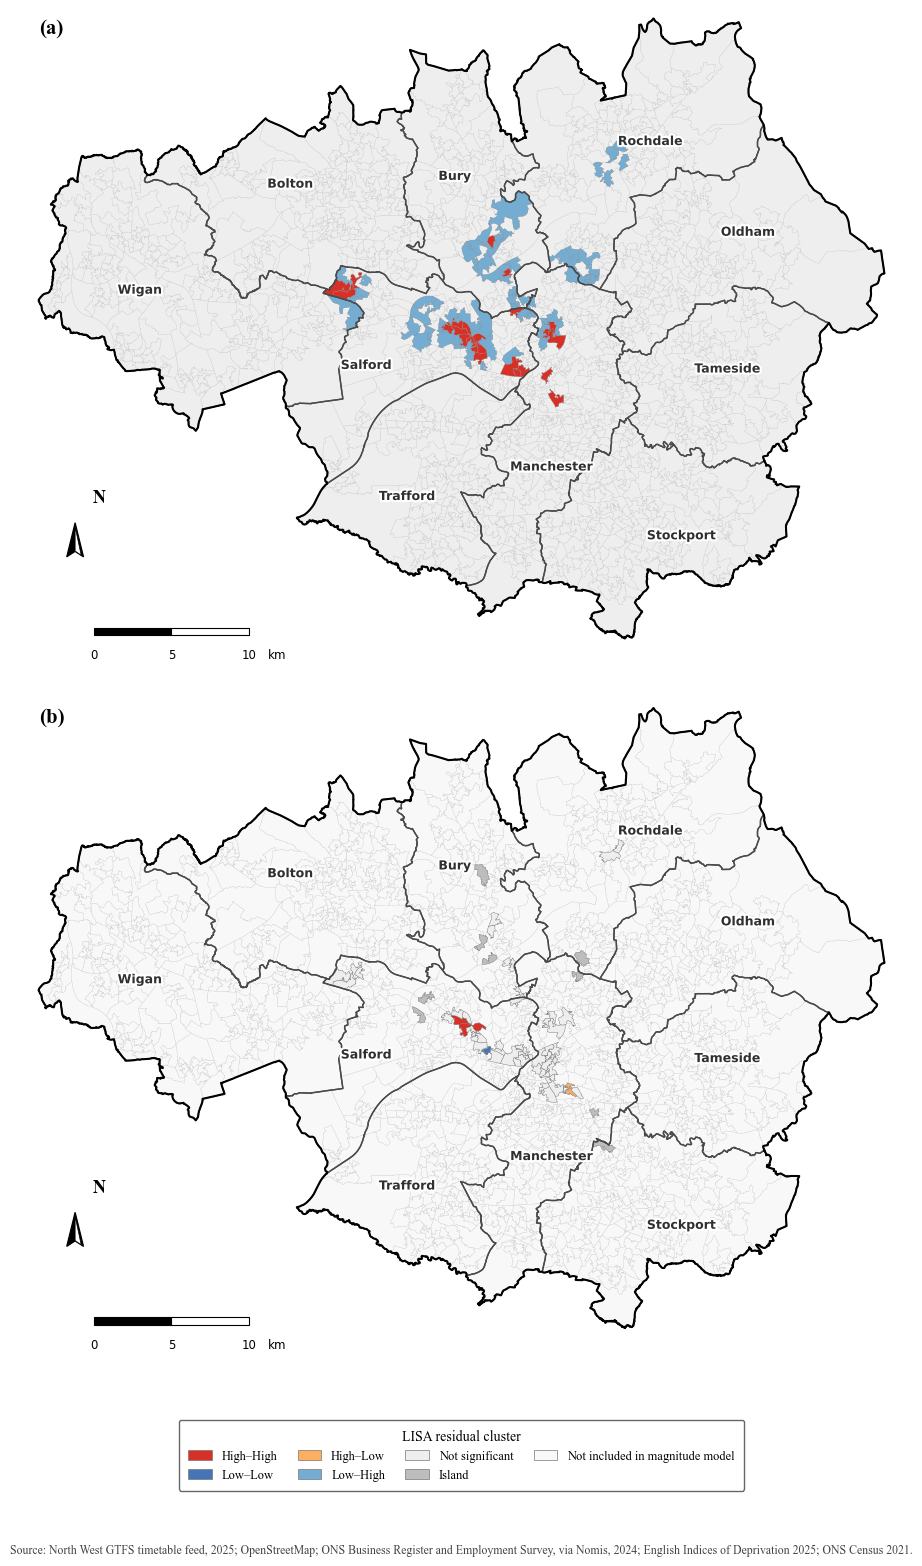

In [ ]:
# output path
lisa_map_path = (
    results_output_dir
    / "residual_lisa_clusters_percentage_change.png"
)

# ensure British National Grid
if logistic_lisa_gdf.crs.to_epsg() != 27700:

    logistic_lisa_gdf = (
        logistic_lisa_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

if magnitude_lisa_gdf.crs.to_epsg() != 27700:

    magnitude_lisa_gdf = (
        magnitude_lisa_gdf
        .to_crs(
            "EPSG:27700"
        )
    )

if borough_boundaries.crs.to_epsg() != 27700:

    borough_boundaries = (
        borough_boundaries
        .to_crs(
            "EPSG:27700"
        )
    )

# Greater Manchester external boundary
gm_lisa_boundary = (
    logistic_lisa_gdf[
        [
            "geometry"
        ]
    ]
    .dissolve()
)

# LISA colours
lisa_colours = {
    "High–High":
        "#D73027",

    "Low–Low":
        "#4575B4",

    "High–Low":
        "#FDAE61",

    "Low–High":
        "#74ADD1",

    "Not significant":
        "#EEEEEE",

    "Island":
        "#BDBDBD",

    "Not included in magnitude model":
        "#F8F8F8"
}

# map boundary styling
borough_boundary_colour = (
    "#4A4A4A"
)

borough_boundary_width = (
    1.0
)

external_boundary_width = (
    1.50
)

# north arrow
def add_north_arrow(
    axis,
    x=0.085,
    y=0.165,
    size=0.050
):
    """
    Add a black-and-white compass-style north arrow.
    """

    axis.text(
        x,
        y + size * 1.12,
        "N",
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        family="Times New Roman",
        color="black",
        zorder=30
    )

    outer_arrow = np.array(
        [
            [
                x,
                y + size
            ],
            [
                x - size * 0.18,
                y
            ],
            [
                x,
                y + size * 0.16
            ],
            [
                x + size * 0.18,
                y
            ]
        ]
    )

    outer_display = (
        axis.transAxes
        .transform(
            outer_arrow
        )
    )

    outer_data = (
        axis.transData
        .inverted()
        .transform(
            outer_display
        )
    )

    axis.add_patch(
        Polygon(
            outer_data,
            closed=True,
            facecolor="black",
            edgecolor="black",
            linewidth=0.9,
            zorder=30
        )
    )

    inner_arrow = np.array(
        [
            [
                x,
                y + size * 0.88
            ],
            [
                x,
                y + size * 0.17
            ],
            [
                x + size * 0.13,
                y + size * 0.05
            ]
        ]
    )

    inner_display = (
        axis.transAxes
        .transform(
            inner_arrow
        )
    )

    inner_data = (
        axis.transData
        .inverted()
        .transform(
            inner_display
        )
    )

    axis.add_patch(
        Polygon(
            inner_data,
            closed=True,
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            zorder=31
        )
    )

# map extent
xmin, ymin, xmax, ymax = (
    logistic_lisa_gdf.total_bounds
)

x_margin = (
    xmax - xmin
) * 0.015

y_margin = (
    ymax - ymin
) * 0.015

common_xlim = (
    xmin - x_margin,
    xmax + x_margin
)

common_ylim = (
    ymin - y_margin,
    ymax + y_margin
)

# create figure
fig, axes = plt.subplots(
    2,
    1,
    figsize=(
        13,
        16
    )
)

# Probability of positive accessibility change
ax = axes[
    0
]

# LSOA background
logistic_lisa_gdf.plot(
    ax=ax,
    facecolor=lisa_colours[
        "Not significant"
    ],
    edgecolor="#B8B8B8",
    linewidth=0.15,
    zorder=1
)

# significant clusters
for cluster_name in [
    "High–High",
    "Low–Low",
    "High–Low",
    "Low–High"
]:

    cluster_layer = (
        logistic_lisa_gdf.loc[
            logistic_lisa_gdf[
                "LISA_cluster"
            ] == cluster_name
        ]
    )

    if cluster_layer.empty:

        continue

    cluster_layer.plot(
        ax=ax,
        facecolor=lisa_colours[
            cluster_name
        ],
        edgecolor="#8A8A8A",
        linewidth=0.22,
        zorder=3
    )

# borough boundaries
borough_boundaries.boundary.plot(
    ax=ax,
    color=borough_boundary_colour,
    linewidth=borough_boundary_width,
    alpha=1.0,
    zorder=5
)

# external boundary
gm_lisa_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=external_boundary_width,
    zorder=6
)

# borough labels
add_borough_labels(
    axis=ax,
    label_gdf=borough_label_points
)

# north arrow
add_north_arrow(
    axis=ax
)

# scale bar
add_scale_bar(
    axis=ax
)

# map extent
ax.set_xlim(
    common_xlim
)

ax.set_ylim(
    common_ylim
)

ax.set_aspect(
    "equal"
)

ax.set_axis_off()

# panel label
ax.text(
    0.015,
    0.985,
    "(a)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=15,
    fontweight="bold",
    family="Times New Roman"
)

# Magnitude of positive percentage change
ax = axes[
    1
]

# LSOAs not included in magnitude model
logistic_lisa_gdf.plot(
    ax=ax,
    facecolor=lisa_colours[
        "Not included in magnitude model"
    ],
    edgecolor="#B8B8B8",
    linewidth=0.15,
    zorder=1
)

# LSOAs included in magnitude model
for cluster_name in [
    "High–High",
    "Low–Low",
    "High–Low",
    "Low–High",
    "Not significant",
    "Island"
]:

    cluster_layer = (
        magnitude_lisa_gdf.loc[
            magnitude_lisa_gdf[
                "LISA_cluster"
            ] == cluster_name
        ]
    )

    if cluster_layer.empty:

        continue

    cluster_layer.plot(
        ax=ax,
        facecolor=lisa_colours[
            cluster_name
        ],
        edgecolor="#777777",
        linewidth=0.28,
        zorder=3
    )

# borough boundaries
borough_boundaries.boundary.plot(
    ax=ax,
    color=borough_boundary_colour,
    linewidth=borough_boundary_width,
    alpha=1.0,
    zorder=5
)

# external boundary
gm_lisa_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=external_boundary_width,
    zorder=6
)

# borough labels
add_borough_labels(
    axis=ax,
    label_gdf=borough_label_points
)

# north arrow
add_north_arrow(
    axis=ax
)

# scale bar
add_scale_bar(
    axis=ax
)

# map extent
ax.set_xlim(
    common_xlim
)

ax.set_ylim(
    common_ylim
)

ax.set_aspect(
    "equal"
)

ax.set_axis_off()

# panel label
ax.text(
    0.015,
    0.985,
    "(b)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=15,
    fontweight="bold",
    family="Times New Roman"
)

# Legend
legend_order = [
    "High–High",
    "Low–Low",
    "High–Low",
    "Low–High",
    "Not significant",
    "Island",
    "Not included in magnitude model"
]

legend_handles = [
    Patch(
        facecolor=lisa_colours[
            cluster_name
        ],
        edgecolor="#777777",
        linewidth=0.5,
        label=cluster_name
    )
    for cluster_name in legend_order
]

legend = fig.legend(
    handles=legend_handles,
    title="LISA residual cluster",
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(
        0.5,
        0.055
    ),
    frameon=True,
    framealpha=1.0,
    facecolor="white",
    edgecolor="#666666",
    fontsize=9,
    title_fontsize=10,
    labelspacing=0.55,
    columnspacing=1.6,
    borderpad=0.75,
    handlelength=1.9,
    handleheight=0.85,
    prop={
        "family":
            "Times New Roman",

        "size":
            9
    }
)

legend.get_title().set_fontweight(
    "normal"
)

legend.get_title().set_fontfamily(
    "Times New Roman"
)

# Source
source_note = (
    "Source: North West GTFS timetable feed, 2025; OpenStreetMap; "
    "ONS Business Register and Employment Survey, via Nomis, 2024; "
    "English Indices of Deprivation 2025; ONS Census 2021."
)

fig.text(
    0.5,
    0.022,
    source_note,
    ha="center",
    va="center",
    fontsize=8.5,
    family="Times New Roman",
    color="#444444"
)

# layout
fig.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.985,
    bottom=0.155,
    hspace=0.08
)

# save and display
fig.savefig(
    lisa_map_path,
    dpi=600,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

plt.close(
    fig
)

The LISA results show where the residual spatial clustering occurred. 24 LSOAs were identified as High–High clusters, while 60 were classified as Low–High spatial outliers. The remaining 1,618 LSOAs showed no significant local spatial association. Figure 10(a) shows that the significant clusters were mainly concentrated in central and inner Greater Manchester. High–High clusters indicate areas with high residuals surrounded by similarly high residuals, while Low–High outliers indicate areas with relatively low residuals next to areas with higher residuals.

Residual spatial autocorrelation was stronger for the magnitude model, with Moran’s (I=0.369) and (p=0.003). However, the spatial structure of this analysis was more fragmented because it included only the 63 LSOAs that experienced a positive accessibility change. 9 LSOAs were spatial islands, the sample was divided into 16 connected components, and only 60.3% of observations belonged to the largest connected component. The Global Moran’s I result for the magnitude model should be interpreted with greater caution.

The local results for the magnitude model were limited. Only 2 LSOAs were identified as Low–Low clusters, while 52 LSOAs showed no significant local spatial association. No High–High, High–Low or Low–High clusters were identified. Figure 10(b) also shows that the affected LSOAs were geographically dispersed and that significant residual clustering was restricted to a very small number of locations.

The spatial diagnostics show that residual spatial dependence remained after controlling for income deprivation, population density, no-car households and baseline accessibility. This pattern was clearer for the probability model, where several local clusters remained despite most LSOAs showing no significant local association. For the magnitude model, the residual spatial pattern was less clear because of the small and fragmented sample. 

# 5 Discussion

## 5.1 Summary of Key Findings

This study examined the impact of the Bee Network overnight bus pilot on access to hospitality employment across Greater Manchester, with particular attention to whether the accessibility benefits were distributed equitably across neighbourhoods with different levels of income deprivation. Accessibility was measured using a cumulative opportunity approach, which estimated the number of hospitality jobs that could be reached within a 45-minute public transport journey under both the pre-pilot and pilot scenarios. The analysis combined GTFS timetable data, the OSM transport network and LSOA-level employment and income deprivation data to assess changes in accessibility and their distribution across the study area.

The first key finding is that night-time accessibility to hospitality employment was characterised by substantial spatial inequality before the introduction of the overnight bus pilot. The baseline accessibility maps demonstrated a clear concentration of accessible employment within and around Manchester city centre, where hospitality employment opportunities and public transport services are both densely clustered. In contrast, neighbourhoods located towards the metropolitan periphery generally exhibited considerably lower levels of accessibility. This pattern reflects the spatial concentration of economic activity within Greater Manchester and the radial structure of the public transport network, in which many services converge on the regional centre. The ability to access hospitality employment during the night-time period varies considerably according to geographical location.

When baseline accessibility was compared across the five income deprivation quintiles, more deprived neighbourhoods generally recorded higher levels of accessibility than less deprived neighbourhoods. The descriptive analysis showed that the median number of accessible hospitality jobs increased progressively from the least deprived to the most deprived quintile, although substantial variation remained within every deprivation group. This finding indicates that neighbourhood income deprivation alone does not correspond directly to lower levels of public transport accessibility. Instead, many of the more deprived neighbourhoods are located within the inner urban area where employment opportunities and transport services are concentrated, allowing residents to access a larger number of hospitality jobs despite experiencing relatively high levels of socioeconomic disadvantage.

The second key finding concerns the impact of the overnight bus pilot itself. Comparing the accessibility results before and after the introduction of the pilot showed that the additional overnight services generated measurable improvements in access to hospitality employment. However, these improvements were not distributed evenly across Greater Manchester. More than half of the LSOAs experienced no increase in the number of accessible hospitality jobs within the 45-minute travel-time threshold, while substantial gains were observed only in selected locations situated along or close to the four pilot bus routes. Although individual neighbourhoods benefited considerably from the extension of overnight services, the overall increase in accessibility across the metropolitan area remained relatively modest. These findings suggest that extending the operating hours of a small number of existing bus routes can generate meaningful local improvements without fundamentally altering the wider spatial distribution of accessibility.

The equity analysis demonstrates that the accessibility benefits of the pilot were not systematically associated with neighbourhood income deprivation. Descriptive statistics indicated that the most deprived quintile recorded the highest average increase in accessible hospitality jobs. Nevertheless, the distribution of accessibility change was highly uneven within every deprivation group. The median accessibility improvement was zero across all five quintiles, indicating that more than half of the neighbourhoods within each group experienced no measurable improvement. Furthermore, the relatively high mean value observed in the most deprived quintile was largely influenced by a small number of neighbourhoods that recorded exceptionally large accessibility gains, rather than reflecting a consistent improvement across the deprivation group as a whole.

These observations were confirmed by the statistical analysis. The Kruskal–Wallis test found no statistically significant differences in accessibility improvements between the five income deprivation quintiles, and the calculated effect size was negligible. The observed differences in descriptive statistics cannot be interpreted as evidence that the pilot preferentially benefited either more or less deprived neighbourhoods. The results indicate that accessibility improvements were primarily determined by the geographical alignment of the overnight bus routes. Neighbourhoods located close to the pilot routes generally benefited regardless of their deprivation level, whereas neighbourhoods situated outside these routes experienced little or no change in accessibility.

These findings suggest that the overnight bus pilot achieved its primary objective of improving night-time accessibility in the areas directly served by the additional services, but its influence on transport equity at the metropolitan scale was limited. The pilot generated clear local accessibility gains without producing statistically distinguishable differences between neighbourhoods with different levels of income deprivation. This distinction between local accessibility improvement and wider equity outcomes forms the basis for the following discussion, which considers how the spatial characteristics of the pilot, the geography of hospitality employment and the structure of the public transport network help to explain the observed patterns and what these findings imply for the future development of night-time public transport in Greater Manchester.

## 5.2 Equity Implications of the Overnight Bus Pilot

The results indicate that the overnight bus pilot improved accessibility to hospitality employment, but these improvements did not translate into significant differences across neighbourhoods with different levels of income deprivation. Although the most deprived quintile recorded the highest average increase in accessible jobs, the statistical analysis showed that this difference was not significant. Instead, accessibility improvements were concentrated within a relatively small number of neighbourhoods located along the four pilot routes. This suggests that the distribution of benefits was primarily determined by the geographical coverage of the pilot rather than by the socioeconomic characteristics of the communities served.

This finding also points out an important distinction between improving accessibility and improving transport equity. Accessibility improvements can be substantial within individual locations while having only a limited influence on the overall distribution of opportunities across different population groups. In this study, more than half of all LSOAs experienced no measurable increase in the number of accessible hospitality jobs, indicating that the pilot produced highly localised benefits rather than a metropolitan-wide redistribution of employment accessibility. Consequently, although the pilot successfully enhanced night-time public transport in selected routes, its contribution to reducing inequalities in accessibility was limited.

The observed pattern is related to the design of the Bee Network pilot. Unlike large-scale network expansion programmes, the intervention did not introduce new routes or extend services into previously unserved areas. It extended the operating hours of four existing daytime bus routes into the overnight period. As a result, neighbourhoods that were already located close to these routes were most likely to benefit, whereas neighbourhoods beyond the influence of the pilot routes experienced little or no change. The spatial distribution of accessibility improvements therefore reflects the alignment of the selected routes rather than a targeted strategy to address neighbourhood-level inequalities.

The baseline analysis also provides important context for interpreting these findings. More deprived neighbourhoods generally exhibited higher levels of night-time accessibility before the pilot was introduced. This does not imply that deprivation is associated with better transport provision. It reflects the spatial relationship between deprivation, employment concentration and the public transport network within Greater Manchester. Many relatively deprived neighbourhoods are located in the inner urban area surrounding Manchester city centre, where hospitality employment opportunities are concentrated and public transport services are more frequent. In contrast, less deprived neighbourhoods located on the metropolitan fringe often have fewer nearby employment opportunities and lower levels of night-time public transport provision. Similar relationships between urban structure, employment concentration and public transport accessibility have been reported in previous studies, which have shown that transport disadvantage cannot be understood solely through socioeconomic indicators but must also be considered within its geographical context.

These findings suggest that extending operating hours on a small number of existing bus routes can generate meaningful accessibility improvements for neighbourhoods directly served by the intervention. However, such improvements do not necessarily lead to measurable changes in transport equity at the metropolitan scale. If the objective is to reduce inequalities in access to employment, future interventions may need to consider not only extending service hours but also expanding the spatial coverage of the overnight network to include neighbourhoods that currently remain beyond convenient access to night-time public transport.

## 5.3 Policy Implications

The findings of this study suggest that accessibility analysis can provide valuable evidence for planning future night-time public transport services. Rather than relying primarily on existing passenger demand or operational considerations, accessibility-based evaluation enables transport authorities to assess how proposed service changes influence access to employment opportunities before they are implemented. Incorporating accessibility measures into the planning process would therefore support more evidence-based decision making and improve the transparency of investment priorities.

The other implication concerns the spatial targeting of future night-time services. The results indicate that extending operating hours can generate substantial accessibility gains for neighbourhoods located close to the selected routes. However, improving accessibility within individual routes does not necessarily translate into more equitable accessibility across the wider metropolitan area. Future service planning could therefore place greater emphasis on identifying areas that currently have limited night-time access to major employment centres and evaluating whether additional routes or revised service patterns would provide greater overall benefits.

The findings also demonstrate the value of integrating transport planning with employment geography. Hospitality employment in Greater Manchester is concentrated in a relatively small number of locations, particularly within and around Manchester city centre. Future night-time public transport planning may therefore benefit from considering both where employment opportunities are located and where potential workers live. Aligning transport provision more closely with major employment destinations could improve access to work while making more effective use of available transport resources.

Finally, the analytical framework developed in this study has wider applications beyond the Bee Network pilot. The combination of GTFS timetable data, road network information and cumulative accessibility analysis provides a practical method for evaluating the accessibility impacts of proposed public transport interventions. 

## 5.4 Limitations

Although this study provides a systematic assessment of the accessibility impacts of the Bee Network overnight bus pilot, several limitations should be acknowledged when interpreting the findings.

First, the accessibility analysis is based on static GTFS timetable data and therefore represents scheduled public transport services rather than actual operating conditions. The travel times estimated by the R5 routing engine assume that services operate according to the published timetable and do not account for delays caused by traffic congestion, vehicle reliability or operational disruption. These factors may be particularly relevant during the evening and overnight periods, when service frequencies are lower and individual delays can have a greater influence on overall journey times. Consequently, the accessibility estimates should be interpreted as potential accessibility under scheduled operating conditions rather than observed travel experiences.

Second, accessibility was measured using a cumulative opportunity approach with a 45-minute travel-time threshold. This method provides an intuitive measure of the number of employment opportunities that can be reached within a specified travel time and is widely used in accessibility research. However, it treats all opportunities within the threshold as equally accessible while excluding those beyond the threshold entirely. In practice, accessibility changes continuously as travel time increases, and travellers may also value shorter journeys more highly than longer ones. Alternative measures, such as gravity-based accessibility indices or utility-based approaches, may therefore capture additional aspects of accessibility that are not reflected in the cumulative opportunity measure used in this study.

Third, the analysis evaluates a specific pilot intervention consisting of overnight services on four existing bus routes within Greater Manchester. The findings therefore reflect the characteristics of this particular intervention rather than the potential impacts of a comprehensive expansion of the overnight public transport network. Different route selections, service frequencies or network configurations may produce different accessibility outcomes and distributional effects. 

Finally, this study focuses exclusively on accessibility to hospitality employment and examines equity using neighbourhood income deprivation. Income deprivation represents only one dimension of transport equity. Other characteristics, such as age, disability, ethnicity, household car availability or shift-working patterns, may also influence the ability to access employment by public transport. Future research could therefore extend the analytical framework to consider a wider range of employment sectors, destinations and socioeconomic characteristics in order to provide a more comprehensive assessment of transport equity.

# 6 Conclusions

This study examined the impact of the Bee Network overnight bus pilot on public transport accessibility to hospitality employment in Greater Manchester, with particular attention to the distribution of accessibility across neighbourhoods with different levels of income deprivation. Using GTFS timetable data, the R5 routing engine and a cumulative opportunity accessibility measure, accessibility was evaluated before and after the introduction of the overnight services to assess both accessibility outcomes and equity implications.

The results show that the overnight bus pilot improved access to hospitality employment, but these improvements were spatially concentrated rather than evenly distributed across Greater Manchester. Accessibility gains were largely limited to neighbourhoods located along the four pilot routes, while more than half of all LSOAs experienced no measurable increase in accessible employment within the 45-minute travel-time threshold. Although the most deprived neighbourhoods recorded the largest average accessibility improvements, the differences between income deprivation groups were not statistically significant. These findings indicate that the distribution of accessibility gains was primarily influenced by the geographical coverage of the pilot routes rather than neighbourhood income deprivation.

The study also highlights the importance of distinguishing between improvements in accessibility and improvements in transport equity. Extending operating hours on existing bus routes can provide meaningful benefits for communities directly served by the intervention, but such improvements do not necessarily reduce wider spatial inequalities in employment accessibility. Achieving broader equity objectives is therefore likely to require interventions that consider both the temporal availability and the spatial coverage of public transport services. This research demonstrates the value of combining timetable data, network modelling and accessibility analysis to evaluate public transport interventions. 

Future research could extend this work by evaluating a wider range of public transport interventions, including additional overnight routes, increased service frequencies and alternative network configurations, to examine how different strategies influence accessibility and transport equity. The analytical framework developed in this study could also be applied to other employment sectors or essential destinations, such as healthcare, education and retail services, while incorporating additional socioeconomic characteristics, including age, disability, household car availability and shift-working patterns, to provide a more comprehensive assessment of transport equity. Furthermore, integrating timetable-based accessibility modelling with observed travel behaviour or passenger demand data would offer a more complete understanding of how public transport interventions influence both potential accessibility and actual travel opportunities, thereby supporting more effective evidence-based transport planning.

word count

In [63]:
import io
from nbformat import current

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".ipynb") and not file.endswith("checkpoint.ipynb"):
            print(os.path.join(root, file))

            with io.open(os.path.join(root, file), 'r', encoding='utf-8') as f:
                nb = current.read(f, 'json')

            word_count_markdown = 0
            word_count_heading = 0
            word_count_code = 0

            for cell in nb.worksheets[0].cells:
                if cell.cell_type == "markdown":
                    word_count_markdown += len(cell['source'].replace('#', '').lstrip().split())
                elif cell.cell_type == "heading":
                    word_count_heading += len(cell['source'].replace('#', '').lstrip().split())
                elif cell.cell_type == "code":
                    word_count_code += len(cell['input'].replace('#', '').lstrip().split())

            print("{} Words in notebooks' markdown".format(word_count_markdown))
            print("{} Words in notebooks' heading".format(word_count_heading))
            print("{} Words in notebooks' code".format(word_count_code))

            break  

    break  

.\final.ipynb
8276 Words in notebooks' markdown
129 Words in notebooks' heading
25013 Words in notebooks' code


C:\Users\84966\AppData\Local\Temp\ipykernel_6784\2568822449.py:2: DeprecationWarning: nbformat.current is deprecated since before nbformat 3.0

- use nbformat for read/write/validate public API
- use nbformat.vX directly to composing notebooks of a particular version

  from nbformat import current
